In [ ]:
# 1. EXTRAER LOS ARCHIVOS DE DATOS

# zipfile permite abrir y descomprimir archivos ZIP.
import zipfile

# Abrimos el ZIP que hemos subido a Colab.
with zipfile.ZipFile("/content/H2020.zip", "r") as archivo_zip:

    # Extraemos los dos Excel a una carpeta llamada "datos".
    # La carpeta se crea automáticamente si no existe.
    archivo_zip.extract("projects.xlsx", "/content/datos")
    archivo_zip.extract("SciVocCodes.xlsx", "/content/datos")

# Este mensaje aparecerá si la extracción termina sin errores.
print("Archivos extraídos correctamente:")
print("projects.xlsx")
print("SciVocCodes.xlsx")


Archivos extraídos correctamente:
projects.xlsx
SciVocCodes.xlsx


In [ ]:
# 2. LEER LOS DOS ARCHIVOS EXCEL

# Importamos Pandas y usamos "pd" como nombre abreviado.
import pandas as pd

# Leemos los proyectos y guardamos la tabla en "proyectos".
proyectos = pd.read_excel("/content/datos/projects.xlsx")

# Leemos el catálogo de categorías y lo guardamos en "categorias".
categorias = pd.read_excel("/content/datos/SciVocCodes.xlsx")

# .shape indica el tamaño de una tabla:
# [0] es el número de filas y [1] es el número de columnas.
print("Número de proyectos:", proyectos.shape[0])
print("Columnas de proyectos:", proyectos.shape[1])

print("Entradas del catálogo:", categorias.shape[0])
print("Columnas del catálogo:", categorias.shape[1])

Número de proyectos: 35378
Columnas de proyectos: 19
Entradas del catálogo: 1013
Columnas del catálogo: 4


In [ ]:
# 3. VER LAS COLUMNAS Y ALGUNOS EJEMPLOS

# Mostramos los nombres de todas las columnas de los proyectos.
print("Columnas de la tabla de proyectos:")
print(proyectos.columns.tolist())

# Seleccionamos cuatro columnas importantes y mostramos tres proyectos.
print("\nEjemplos de proyectos:")
display(proyectos[
    ["projectID", "title", "summary", "euroSciVocCode"]
].head(3))

# Mostramos cinco filas del catálogo de categorías científicas.
print("\nEjemplos del catálogo de categorías:")
display(categorias.head(5))

Columnas de la tabla de proyectos:
['projectID', 'acronym', 'title', 'summary', 'startDate', 'endDate', 'totalCost', 'ecMaxContribution', 'masterCall', 'subCall', 'fundingScheme', 'rcn', 'topic', 'topic_title', 'countryContr', 'coordinatorCountry', 'euroSciVocCode', 'publicationID', 'patentID']

Ejemplos de proyectos:


,projectID,title,summary,euroSciVocCode
0,115843,Ebola Virus: Modern Approaches for developing ...,The current Ebola Virus Disease (EVD) outbreak...,"[155, 56306972, 325, 137, 1609]"
1,115910,PERtussIS COrrelates of Protection Europe - So...,Pertussis vaccines have been very successful i...,"[137, 1439, 44109686, 48479582]"
2,635266,Opening the cycling and walking tracking poten...,This project will explore the potential of wal...,[1373]



Ejemplos del catálogo de categorías:


,full_path,title,code,full_code
0,/agricultural sciences/agricultural biotechnol...,livestock cloning,NaN,/27/79/483/
1,/agricultural sciences/agricultural biotechnol...,plant cloning,1275.0,/27/79/483/1275
2,/agricultural sciences/agricultural biotechnol...,agricultural genetics,483.0,/27/79/483
3,/agricultural sciences/agricultural biotechnol...,biomass,481.0,/27/79/481
4,/agricultural sciences/agricultural biotechnol...,marker assisted selection,487.0,/27/79/487


In [ ]:
# 4. REVISAR LOS TIPOS DE DATOS Y LOS VALORES AUSENTES

# Creamos una tabla de revisión para los proyectos.
# dtypes indica el tipo de dato de cada columna.
# isna() detecta valores ausentes y sum() los cuenta por columna.
revision_proyectos = pd.DataFrame({
    "tipo_de_dato": proyectos.dtypes.astype(str),
    "valores_ausentes": proyectos.isna().sum()
})

print("Revisión de la tabla de proyectos:")
display(revision_proyectos)

# Hacemos la misma comprobación para el catálogo de categorías.
revision_categorias = pd.DataFrame({
    "tipo_de_dato": categorias.dtypes.astype(str),
    "valores_ausentes": categorias.isna().sum()
})

print("Revisión del catálogo de categorías:")
display(revision_categorias)

Revisión de la tabla de proyectos:


,tipo_de_dato,valores_ausentes
projectID,int64,0
acronym,object,0
title,object,0
summary,object,0
startDate,datetime64[ns],11
endDate,datetime64[ns],11
totalCost,float64,0
ecMaxContribution,float64,0
masterCall,object,20358
subCall,object,0


Revisión del catálogo de categorías:


,tipo_de_dato,valores_ausentes
full_path,object,0
title,object,0
code,float64,3
full_code,object,0


In [ ]:
# 5. CONVERTIR LOS CÓDIGOS GUARDADOS COMO TEXTO EN LISTAS

# ast permite interpretar una lista escrita dentro de un texto.
# Esta biblioteca viene incluida con Python.
import ast

# Definimos cómo convertir el contenido de una casilla.
def convertir_codigos(valor):

    # Si la casilla está vacía, devolvemos una lista vacía.
    if pd.isna(valor):
        return []

    # Si contiene texto con una lista, lo convertimos en una lista real.
    return ast.literal_eval(valor)


# apply ejecuta la función sobre cada casilla de euroSciVocCode.
# Guardamos el resultado en una columna nueva.
proyectos["lista_codigos"] = proyectos["euroSciVocCode"].apply(convertir_codigos)

# Comprobamos la conversión utilizando el primer proyecto.
# iloc[0] selecciona la primera fila.
print("Tipo original:", type(proyectos["euroSciVocCode"].iloc[0]).__name__)
print("Tipo convertido:", type(proyectos["lista_codigos"].iloc[0]).__name__)
print("Lista del primer proyecto:", proyectos["lista_codigos"].iloc[0])

# len cuenta los elementos de cada lista.
# Una longitud de cero significa que el proyecto no tiene códigos.
sin_codigos = proyectos["lista_codigos"].apply(len) == 0
print("Proyectos sin códigos:", sin_codigos.sum())

Tipo original: str
Tipo convertido: list
Lista del primer proyecto: [155, 56306972, 325, 137, 1609]
Proyectos sin códigos: 3326


In [ ]:
# 6. RELACIONAR CADA CÓDIGO CON SUS CATEGORÍAS DE NIVEL 1 Y 2

# Creamos un diccionario vacío que iremos rellenando.
mapa_categorias = {}

# Recorremos las filas del catálogo.
for indice, fila in categorias.iterrows():

    # Saltamos las entradas que no tienen código.
    if pd.isna(fila["code"]):
        continue

    # Quitamos las barras de los extremos y separamos los niveles.
    # Ejemplo:
    # "/agricultural sciences/agricultural biotechnology/plant cloning"
    # se convierte en una lista con esos tres nombres.
    niveles = fila["full_path"].strip("/").split("/")

    # Si la ruta solo tiene un nivel, no permite obtener el nivel 2.
    if len(niveles) < 2:
        continue

    # Convertimos el código a entero: por ejemplo, 1275.0 pasa a 1275.
    codigo = int(fila["code"])

    # Guardamos los dos primeros niveles asociados a este código.
    # En Python, la primera posición es [0] y la segunda es [1].
    mapa_categorias[codigo] = {
        "nivel_1": niveles[0],
        "nivel_2": niveles[1]
    }

# Comprobamos el resultado con el código 1275.
print("Comprobación del código 1275:")
print("Nivel 1:", mapa_categorias[1275]["nivel_1"])
print("Nivel 2:", mapa_categorias[1275]["nivel_2"])

Comprobación del código 1275:
Nivel 1: agricultural sciences
Nivel 2: agricultural biotechnology


In [ ]:
# 7. ASIGNAR LAS CATEGORÍAS DE CADA PROYECTO

# Esta función recibe la lista de códigos de un proyecto.
def obtener_categorias(codigos):

    # Revisamos los códigos en su orden original.
    for codigo in codigos:

        # El diccionario solo contiene códigos con un nivel 2 válido.
        if codigo in mapa_categorias:

            # return devuelve las categorías y termina la función.
            # Así elegimos únicamente el primer código válido.
            return (
                mapa_categorias[codigo]["nivel_1"],
                mapa_categorias[codigo]["nivel_2"]
            )

    # Si ningún código sirve, devolvemos dos valores ausentes.
    return (None, None)


# Aplicamos la función a la lista de códigos de cada proyecto.
asignaciones = proyectos["lista_codigos"].apply(obtener_categorias)

# Organizamos los resultados en una tabla con dos columnas.
# Conservamos los índices para mantener cada resultado junto a su proyecto.
etiquetas = pd.DataFrame(
    asignaciones.tolist(),
    columns=["nivel_1", "nivel_2"],
    index=proyectos.index
)

# Añadimos las dos columnas a la tabla de proyectos.
proyectos[["nivel_1", "nivel_2"]] = etiquetas

# Contamos cuántos proyectos tienen una categoría válida.
print("Proyectos con categoría válida:", proyectos["nivel_2"].notna().sum())
print("Proyectos sin categoría válida:", proyectos["nivel_2"].isna().sum())

# Mostramos tres ejemplos para revisar la asignación.
display(proyectos[
    ["projectID", "lista_codigos", "nivel_1", "nivel_2"]
].head(3))

Proyectos con categoría válida: 31982
Proyectos sin categoría válida: 3396


,projectID,lista_codigos,nivel_1,nivel_2
0,115843,"[155, 56306972, 325, 137, 1609]",medical and health sciences,basic medicine
1,115910,"[137, 1439, 44109686, 48479582]",medical and health sciences,health sciences
2,635266,[1373],social sciences,sociology


In [ ]:
# 8. SELECCIONAR LOS PROYECTOS CON CATEGORÍA VÁLIDA

# Seleccionamos las filas que tienen una categoría de nivel 2.
# copy() crea una copia para trabajar con ella.
datos = proyectos.dropna(subset=["nivel_2"]).copy()

# Numeramos las filas desde cero, sin cambiar el identificador projectID.
datos = datos.reset_index(drop=True)

# Comprobamos cuántos proyectos conservamos y cuántos descartamos.
print("Proyectos originales:", len(proyectos))
print("Proyectos válidos:", len(datos))
print("Proyectos descartados:", len(proyectos) - len(datos))

# Calculamos el porcentaje de proyectos conservados.
porcentaje_conservado = 100 * len(datos) / len(proyectos)

# :.2f muestra el porcentaje con dos decimales.
print(f"Porcentaje conservado: {porcentaje_conservado:.2f}%")

# nunique() cuenta cuántas categorías diferentes aparecen.
print("Clases de nivel 1:", datos["nivel_1"].nunique())
print("Clases de nivel 2:", datos["nivel_2"].nunique())

Proyectos originales: 35378
Proyectos válidos: 31982
Proyectos descartados: 3396
Porcentaje conservado: 90.40%
Clases de nivel 1: 6
Clases de nivel 2: 39


In [ ]:
# 9. COMPROBAR IDENTIFICADORES Y RESÚMENES

# Contamos identificadores repetidos.
# Cada proyecto debería tener un identificador diferente.
ids_repetidos = datos["projectID"].duplicated().sum()

# Comprobamos si algún resumen está vacío o contiene solo espacios.
# fillna("") sustituye temporalmente los valores ausentes por texto vacío.
# strip() elimina los espacios de los extremos.
resumenes_vacios = (
    datos["summary"].fillna("").str.strip() == ""
).sum()

# Contamos repeticiones de textos exactamente iguales.
# duplicated() marca las apariciones posteriores a la primera.
resumenes_repetidos = datos["summary"].duplicated().sum()

print("Identificadores repetidos:", ids_repetidos)
print("Resúmenes vacíos:", resumenes_vacios)
print("Repeticiones adicionales de resúmenes:", resumenes_repetidos)

Identificadores repetidos: 0
Resúmenes vacíos: 0
Repeticiones adicionales de resúmenes: 21


In [ ]:
# 10. AGRUPAR LOS PROYECTOS CON RESÚMENES IDÉNTICOS

# factorize asigna un número a cada texto diferente.
# Los textos exactamente iguales reciben el mismo número.
# [0] selecciona los números de grupo que devuelve esta función.
datos["grupo_resumen"] = pd.factorize(datos["summary"])[0]

# groupby reúne las filas que tienen el mismo número de grupo.
# size() cuenta los proyectos de cada grupo.
# nunique() cuenta sus categorías distintas de nivel 2.
revision_grupos = pd.DataFrame({
    "numero_proyectos": datos.groupby("grupo_resumen").size(),
    "categorias_distintas": datos.groupby("grupo_resumen")["nivel_2"].nunique()
})

# Seleccionamos los grupos que contienen más de un proyecto.
grupos_repetidos = revision_grupos[
    revision_grupos["numero_proyectos"] > 1
]

# Contamos los grupos repetidos que tienen categorías diferentes.
grupos_con_distintas_categorias = (
    grupos_repetidos["categorias_distintas"] > 1
).sum()

print("Proyectos conservados:", len(datos))
print("Resúmenes distintos:", datos["grupo_resumen"].nunique())
print("Grupos con texto repetido:", len(grupos_repetidos))
print("Grupos repetidos con categorías diferentes:",
      grupos_con_distintas_categorias)

# Mostramos una fila por cada grupo de textos repetidos.
display(grupos_repetidos)

Proyectos conservados: 31982
Resúmenes distintos: 31961
Grupos con texto repetido: 19
Grupos repetidos con categorías diferentes: 3


,numero_proyectos,categorias_distintas
grupo_resumen,,
2227,2,1
2540,2,1
3006,3,1
3033,3,2
3402,2,2
4249,2,1
5291,2,1
8575,2,1
10265,2,1


In [ ]:
# 11. CONTAR LOS PROYECTOS DE CADA CATEGORÍA

# value_counts() cuenta cuántas veces aparece cada categoría.
# Ordena el resultado de mayor a menor frecuencia.
frecuencias = datos["nivel_2"].value_counts()

# Creamos una tabla con el número de proyectos y su porcentaje.
distribucion_clases = pd.DataFrame({
    "numero_proyectos": frecuencias,
    "porcentaje": 100 * frecuencias / len(datos)
})

# Mostramos los porcentajes con dos decimales.
print("Distribución de las categorías de nivel 2:")
display(distribucion_clases.round(2))

# La primera posición corresponde a la categoría más frecuente.
print("Clase más frecuente:", frecuencias.index[0])
print("Proyectos de esa clase:", frecuencias.iloc[0])

# La posición [-1] corresponde al último elemento.
print("Clase menos frecuente:", frecuencias.index[-1])
print("Proyectos de esa clase:", frecuencias.iloc[-1])

Distribución de las categorías de nivel 2:


,numero_proyectos,porcentaje
nivel_2,,
biological sciences,3464,10.83
computer and information sciences,2912,9.11
physical sciences,2613,8.17
environmental engineering,2023,6.33
basic medicine,1914,5.98
"electrical engineering, electronic engineering, information engineering",1909,5.97
economics and business,1895,5.93
clinical medicine,1888,5.90
chemical sciences,1586,4.96


Clase más frecuente: biological sciences
Proyectos de esa clase: 3464
Clase menos frecuente: other medical sciences
Proyectos de esa clase: 9


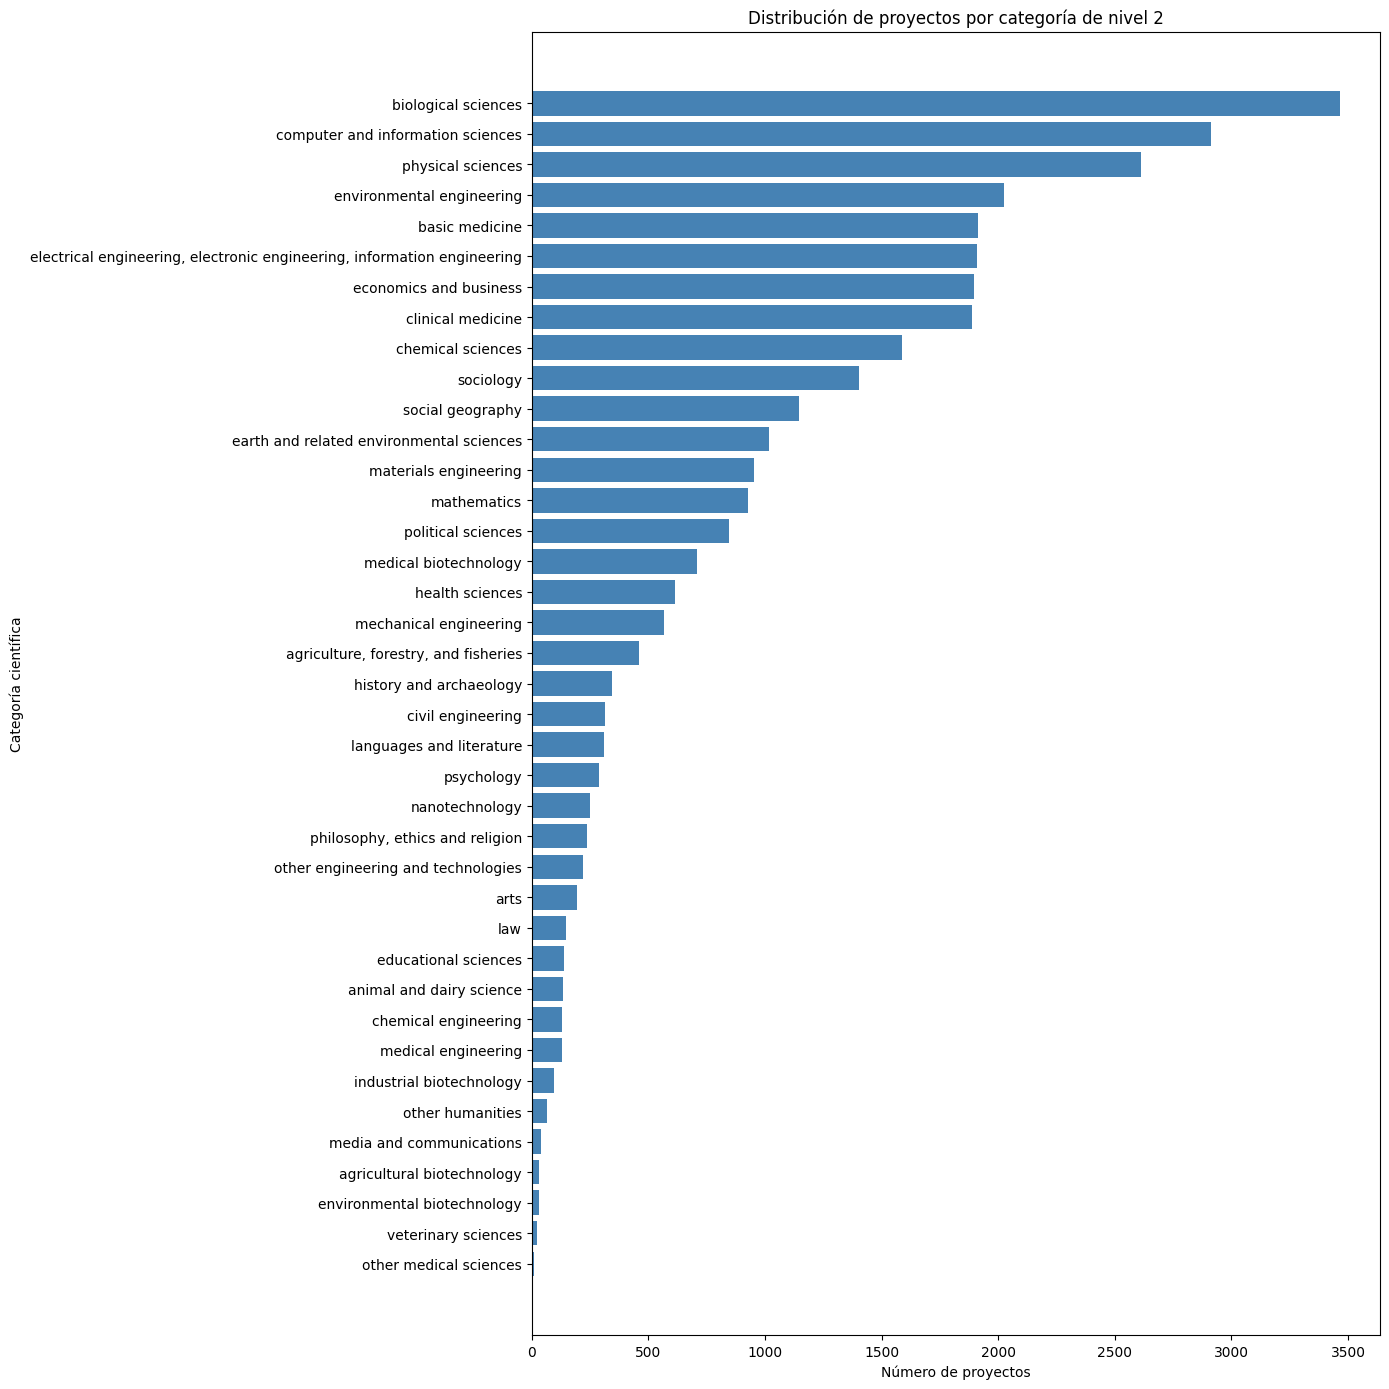

In [ ]:
# 12. REPRESENTAR LA DISTRIBUCIÓN DE LAS CATEGORÍAS

# Matplotlib es una biblioteca para crear gráficas.
import matplotlib.pyplot as plt

# Path permite trabajar con carpetas y rutas de archivos.
from pathlib import Path

# Creamos una carpeta donde guardaremos los resultados.
carpeta_resultados = Path("/content/resultados")
carpeta_resultados.mkdir(exist_ok=True)

# Ordenamos las frecuencias para que las barras más grandes
# aparezcan en la parte superior de la gráfica horizontal.
frecuencias_grafica = frecuencias.sort_values()

# Creamos una figura suficientemente alta para las 39 categorías.
plt.figure(figsize=(14, 14))

# Los nombres de las categorías van en el eje vertical.
# El número de proyectos determina la longitud de cada barra.
plt.barh(
    frecuencias_grafica.index,
    frecuencias_grafica.values,
    color="steelblue"
)

plt.title("Distribución de proyectos por categoría de nivel 2")
plt.xlabel("Número de proyectos")
plt.ylabel("Categoría científica")

# Ajustamos los márgenes para que se vean los nombres completos.
plt.tight_layout()

# Guardamos la gráfica antes de mostrarla.
plt.savefig(
    carpeta_resultados / "distribucion_clases_nivel2.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

Estadísticas de longitud de los resúmenes, en palabras:


,num_palabras
count,31982.00
mean,265.34
std,41.85
min,1.00
25%,257.00
50%,276.00
75%,289.00
95%,307.00
max,587.00


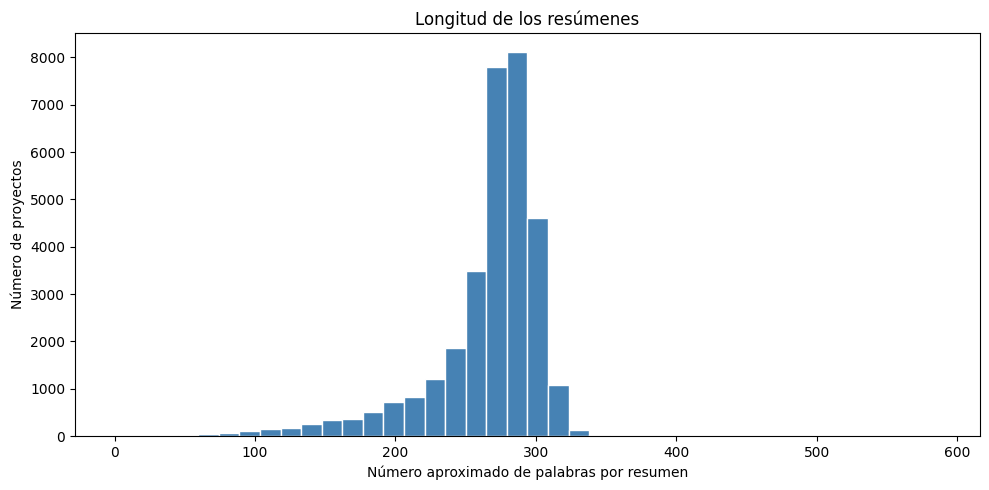

In [ ]:
# 13. ANALIZAR LA LONGITUD DE LOS RESÚMENES

# split() separa cada resumen en palabras.
# len() cuenta cuántas palabras contiene.
datos["num_palabras"] = datos["summary"].str.split().str.len()

# Calculamos estadísticas de longitud.
# Incluimos el percentil 95, además de los percentiles habituales.
estadisticas_longitud = datos["num_palabras"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95]
)

print("Estadísticas de longitud de los resúmenes, en palabras:")
display(estadisticas_longitud.round(2))

# Creamos un histograma:
# cada barra cuenta los resúmenes de un intervalo de longitudes.
plt.figure(figsize=(10, 5))

# bins=40 divide el rango de longitudes en 40 intervalos.
plt.hist(
    datos["num_palabras"],
    bins=40,
    color="steelblue",
    edgecolor="white"
)

plt.title("Longitud de los resúmenes")
plt.xlabel("Número aproximado de palabras por resumen")
plt.ylabel("Número de proyectos")
plt.tight_layout()

# Guardamos la figura para el informe.
plt.savefig(
    carpeta_resultados / "longitud_resumenes.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# 14. INSPECCIONAR LOS RESÚMENES MUY CORTOS

# Seleccionamos los resúmenes de hasta 10 palabras para revisarlos.
# Este límite sirve únicamente para la inspección.
resumenes_cortos = datos.loc[
    datos["num_palabras"] <= 10,
    ["projectID", "num_palabras", "summary", "nivel_2"]
].sort_values("num_palabras")

# Mostramos cuántos casos hemos encontrado.
print("Proyectos con resúmenes de hasta 10 palabras:",
      len(resumenes_cortos))

# Mostramos hasta 10 ejemplos.
# option_context permite ver el texto completo de las casillas
# durante esta visualización.
with pd.option_context("display.max_colwidth", None):
    display(resumenes_cortos.head(10))

Proyectos con resúmenes de hasta 10 palabras: 8


,projectID,num_palabras,summary,nivel_2
15504,743407,1,H2020,political sciences
30945,830949,3,KAM and EIMC,economics and business
14656,945385,4,Integrated Genomics Research Centre,biological sciences
10932,645094,6,Automatic Sentiment Estimation in the Wild,mathematics
8361,726320,8,European registry for human embryonic stem cell lines,medical biotechnology
23035,674335,8,Intelligent wireless Driver for outdoor LED lighting application,"electrical engineering, electronic engineering, information engineering"
20212,674855,9,Innovation capacity analysis and services for SMEs in Thuringia,economics and business
31449,673428,10,Innovative active air pollution control system based on plasma technology.,veterinary sciences


Proyectos con año de inicio: 31971
Proyectos sin año de inicio: 11
Número de proyectos por año de inicio:


,numero_proyectos
anio_inicio,
2014,311
2015,4473
2016,4675
2017,4667
2018,4540
2019,4799
2020,3823
2021,3833
2022,848


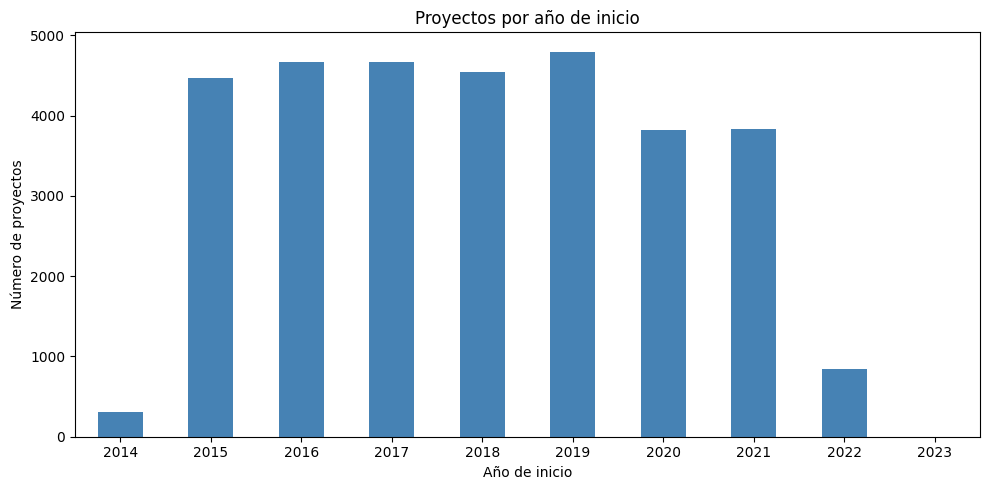

In [ ]:
# 15. ANALIZAR LOS PROYECTOS POR AÑO DE INICIO

# Extraemos el año de la fecha de inicio.
# Int64 permite guardar años enteros y conservar los valores ausentes.
datos["anio_inicio"] = datos["startDate"].dt.year.astype("Int64")

# Comprobamos cuántos proyectos tienen una fecha disponible.
print("Proyectos con año de inicio:",
      datos["anio_inicio"].notna().sum())

print("Proyectos sin año de inicio:",
      datos["anio_inicio"].isna().sum())

# Contamos los proyectos de cada año.
# value_counts() omite los valores ausentes.
# sort_index() ordena los años cronológicamente.
proyectos_por_anio = datos["anio_inicio"].value_counts().sort_index()

print("Número de proyectos por año de inicio:")
display(proyectos_por_anio.to_frame(name="numero_proyectos"))

# Dibujamos una barra por año.
plt.figure(figsize=(10, 5))
proyectos_por_anio.plot(kind="bar", color="steelblue")

plt.title("Proyectos por año de inicio")
plt.xlabel("Año de inicio")
plt.ylabel("Número de proyectos")
plt.xticks(rotation=0)
plt.tight_layout()

# Guardamos la gráfica para el informe.
plt.savefig(
    carpeta_resultados / "proyectos_por_anio.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

Registros corregidos: 9
Países coordinadores distintos: 53
Proyectos contabilizados: 31982


,numero_proyectos,porcentaje
pais_coordinador,,
UK,5027,15.72
ES,3929,12.29
DE,3466,10.84
FR,3040,9.51
IT,2822,8.82
NL,2206,6.90
CH,1335,4.17
BE,1207,3.77
DK,1096,3.43


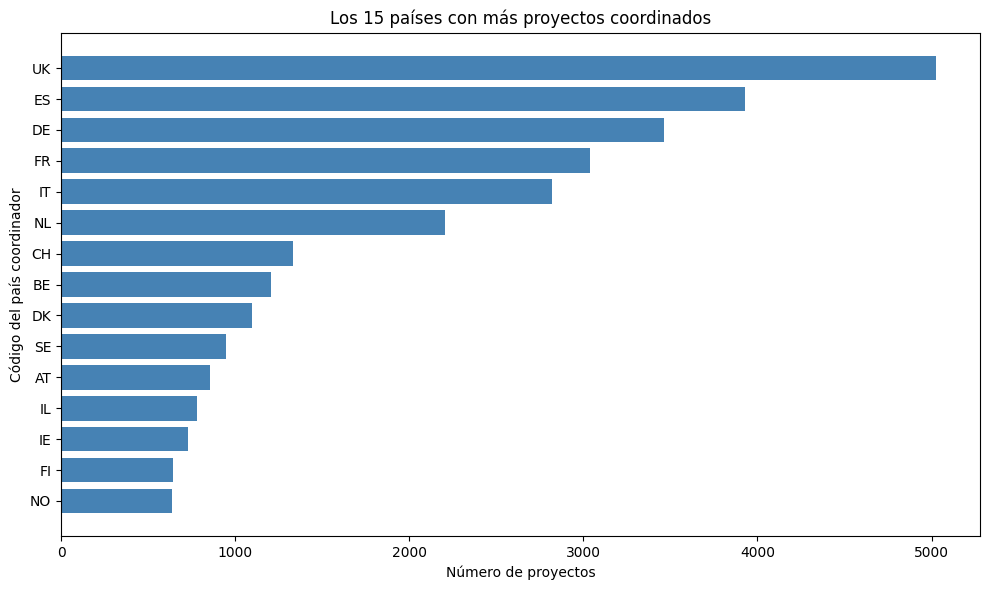

In [ ]:
# 16. NORMALIZAR LOS PAÍSES Y REPRESENTAR LOS PROYECTOS COORDINADOS

# Indicamos cómo corregir las cuatro variantes observadas.
correcciones_paises = {
    "FR;FR": "FR",
    "DE;DE": "DE",
    "IT;IT": "IT",
    "ES;ES": "ES"
}

# Creamos una columna con los países normalizados.
# Conservamos los valores originales en coordinatorCountry.
datos["pais_coordinador"] = datos["coordinatorCountry"].replace(
    correcciones_paises
)

# Contamos cuántos registros han cambiado de denominación.
# != significa "distinto de".
registros_corregidos = (
    datos["pais_coordinador"] != datos["coordinatorCountry"]
).sum()

# Contamos los proyectos utilizando la columna normalizada.
proyectos_por_pais = datos["pais_coordinador"].value_counts()

# Creamos la tabla con recuentos y porcentajes.
tabla_paises = pd.DataFrame({
    "numero_proyectos": proyectos_por_pais,
    "porcentaje": 100 * proyectos_por_pais / len(datos)
})

print("Registros corregidos:", registros_corregidos)
print("Países coordinadores distintos:", len(proyectos_por_pais))
print("Proyectos contabilizados:", proyectos_por_pais.sum())

display(tabla_paises.round(2))

# Seleccionamos los 15 países con más proyectos.
principales_paises = proyectos_por_pais.head(15).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    principales_paises.index,
    principales_paises.values,
    color="steelblue"
)

plt.title("Los 15 países con más proyectos coordinados")
plt.xlabel("Número de proyectos")
plt.ylabel("Código del país coordinador")
plt.tight_layout()

# Actualizamos la imagen guardada con los recuentos corregidos.
plt.savefig(
    carpeta_resultados / "proyectos_por_pais.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# 17. SEPARAR ENTRENAMIENTO, VALIDACIÓN Y PRUEBA

import numpy as np
import sklearn
from sklearn.model_selection import StratifiedGroupKFold

SEMILLA = 42

# Obtenemos los identificadores de los grupos de resúmenes.
grupos_originales = datos["grupo_resumen"].unique()

# Ordenamos los grupos aleatoriamente de forma reproducible.
generador = np.random.default_rng(SEMILLA)
orden_aleatorio = generador.permutation(grupos_originales)

# Asignamos a cada grupo su posición en ese orden.
orden_grupos = {}

for posicion, grupo in enumerate(orden_aleatorio):
    orden_grupos[grupo] = posicion

# Creamos los identificadores que utilizaremos para repartir.
# Los proyectos del mismo grupo siguen teniendo el mismo identificador.
grupos_reparto = datos["grupo_resumen"].map(orden_grupos)

# Creamos cinco bloques manteniendo juntos los resúmenes idénticos.
# La aleatoriedad ya se ha aplicado al orden de los grupos.
separador = StratifiedGroupKFold(
    n_splits=5,
    shuffle=False
)

# Inicialmente asignamos todos los proyectos a entrenamiento.
datos["particion"] = "entrenamiento"

for numero_bloque, (otros_indices, indices_bloque) in enumerate(
    separador.split(
        datos,
        datos["nivel_2"],
        groups=grupos_reparto
    )
):
    # Primer bloque: prueba, aproximadamente el 20 %.
    if numero_bloque == 0:
        datos.loc[datos.index[indices_bloque], "particion"] = "prueba"

    # Segundo bloque: validación, aproximadamente el 20 %.
    elif numero_bloque == 1:
        datos.loc[datos.index[indices_bloque], "particion"] = "validacion"

    # Los otros tres bloques quedan para entrenamiento.

# Creamos las tres tablas.
datos_train = datos.loc[datos["particion"] == "entrenamiento"].copy()
datos_val = datos.loc[datos["particion"] == "validacion"].copy()
datos_test = datos.loc[datos["particion"] == "prueba"].copy()

# Mostramos los tamaños y el número de clases.
print("Entrenamiento:", len(datos_train),
      "proyectos;", datos_train["nivel_2"].nunique(), "clases")

print("Validación:", len(datos_val),
      "proyectos;", datos_val["nivel_2"].nunique(), "clases")

print("Prueba:", len(datos_test),
      "proyectos;", datos_test["nivel_2"].nunique(), "clases")

# Comprobamos que ningún grupo aparece en varias particiones.
grupos_mezclados = (
    datos.groupby("grupo_resumen")["particion"].nunique() > 1
).sum()

print("Grupos presentes en más de un conjunto:", grupos_mezclados)
print("Versión de Scikit-learn:", sklearn.__version__)

# set obtiene el conjunto de categorías diferentes.
clases_esperadas = set(datos["nivel_2"])

# assert comprueba una condición y detiene la ejecución si no se cumple.
assert set(datos_train["nivel_2"]) == clases_esperadas, \
    "Faltan categorías en entrenamiento."

assert set(datos_val["nivel_2"]) == clases_esperadas, \
    "Faltan categorías en validación."

assert set(datos_test["nivel_2"]) == clases_esperadas, \
    "Faltan categorías en prueba."

assert grupos_mezclados == 0, \
    "Hay resúmenes idénticos repartidos entre conjuntos."

assert len(datos_train) + len(datos_val) + len(datos_test) == len(datos), \
    "El total de proyectos no coincide."

print("Comprobaciones correctas.")

Entrenamiento: 19188 proyectos; 39 clases
Validación: 6397 proyectos; 39 clases
Prueba: 6397 proyectos; 39 clases
Grupos presentes en más de un conjunto: 0
Versión de Scikit-learn: 1.6.1
Comprobaciones correctas.


In [ ]:
# 18. GUARDAR EL REPARTO Y REVISAR LAS CATEGORÍAS

# Guardamos qué proyectos pertenecen a cada conjunto.
# Así podremos recuperar exactamente el mismo reparto.
columnas_particion = [
    "projectID",
    "grupo_resumen",
    "nivel_1",
    "nivel_2",
    "particion"
]

datos[columnas_particion].to_csv(
    carpeta_resultados / "particiones.csv",
    index=False,
    encoding="utf-8"
)

# crosstab cuenta cuántos proyectos hay para cada combinación
# de categoría científica y conjunto.
reparto_clases = pd.crosstab(
    datos["nivel_2"],
    datos["particion"]
)

# Colocamos las columnas en el orden que utilizamos habitualmente.
reparto_clases = reparto_clases[
    ["entrenamiento", "validacion", "prueba"]
].copy()

# sum(axis=1) suma las columnas de cada fila.
# Obtenemos el total de proyectos de cada categoría.
reparto_clases["total"] = reparto_clases.sum(axis=1)

# Mostramos primero las categorías con menos proyectos.
reparto_clases = reparto_clases.sort_values("total")

# Guardamos la tabla completa, con las 39 categorías.
# Aquí conservamos el índice porque contiene sus nombres.
reparto_clases.to_csv(
    carpeta_resultados / "reparto_por_clase.csv",
    index=True,
    encoding="utf-8"
)

print("Archivos guardados en:", carpeta_resultados)
print("- particiones.csv")
print("- reparto_por_clase.csv")

print("\nReparto de las 10 categorías con menos proyectos:")
display(reparto_clases.head(10))

Archivos guardados en: /content/resultados
- particiones.csv
- reparto_por_clase.csv

Reparto de las 10 categorías con menos proyectos:


particion,entrenamiento,validacion,prueba,total
nivel_2,,,,
other medical sciences,6,2,1,9
veterinary sciences,15,5,4,24
environmental biotechnology,18,6,6,30
agricultural biotechnology,19,7,7,33
media and communications,25,8,8,41
other humanities,38,13,13,64
industrial biotechnology,57,19,19,95
medical engineering,77,26,26,129
chemical engineering,78,26,26,130


In [ ]:
# 19. MODELO DE REFERENCIA: PREDECIR LA CLASE MAYORITARIA

from sklearn.metrics import accuracy_score, f1_score

# Contamos las categorías usando únicamente entrenamiento.
frecuencias_train = datos_train["nivel_2"].value_counts()

# idxmax() devuelve el nombre de la categoría con más proyectos.
clase_mayoritaria = frecuencias_train.idxmax()

# Creamos una predicción para cada proyecto de validación.
# Repetimos siempre el mismo nombre de categoría.
pred_base_val = [clase_mayoritaria] * len(datos_val)

# Comparamos las categorías reales con nuestras predicciones.
accuracy_base_val = accuracy_score(
    datos_val["nivel_2"],
    pred_base_val
)

# Indicamos las 39 categorías que deben entrar en la evaluación.
clases_nivel2 = sorted(datos_train["nivel_2"].unique())

# average="macro" da el mismo peso a cada categoría.
# zero_division=0 asigna cero si alguna división no está definida.
f1_macro_base_val = f1_score(
    datos_val["nivel_2"],
    pred_base_val,
    labels=clases_nivel2,
    average="macro",
    zero_division=0
)

print("Categoría que predecimos siempre:", clase_mayoritaria)
print("Proyectos evaluados:", len(datos_val))
print(f"Accuracy en validación: {accuracy_base_val:.2%}")
print(f"F1-macro en validación: {f1_macro_base_val:.4f}")

# Guardamos los resultados para compararlos con futuros modelos.
# En el archivo conservamos las métricas sin redondearlas.
resultados_baseline = pd.DataFrame([{
    "modelo": "Clase mayoritaria",
    "conjunto": "validacion",
    "clase_predicha": clase_mayoritaria,
    "accuracy": accuracy_base_val,
    "f1_macro": f1_macro_base_val
}])

resultados_baseline.to_csv(
    carpeta_resultados / "baseline_validacion.csv",
    index=False,
    encoding="utf-8"
)

print("\nResultados guardados en baseline_validacion.csv")

Categoría que predecimos siempre: biological sciences
Proyectos evaluados: 6397
Accuracy en validación: 10.83%
F1-macro en validación: 0.0050

Resultados guardados en baseline_validacion.csv


In [ ]:
# 20. PREPARAR LA HERRAMIENTA PARA PROCESAR EL TEXTO

# Instalamos spaCy si todavía no está disponible.
%pip install -q spacy

# Descargamos un modelo pequeño de inglés compatible con spaCy.
!python -m spacy download en_core_web_sm

import spacy

# Cargamos el modelo.
# Desactivamos dos tareas que no necesitamos para este análisis:
# el análisis de relaciones gramaticales y el reconocimiento de entidades.
# Conservamos los componentes necesarios para obtener los lemas.
nlp = spacy.load(
    "en_core_web_sm",
    disable=["parser", "ner"]
)

# Mostramos las versiones para documentar las herramientas utilizadas.
print("Versión de spaCy:", spacy.__version__)
print("Versión del modelo de inglés:", nlp.meta["version"])

# Probamos el modelo con una frase corta.
frase_prueba = "The researchers study networks and technologies."
documento_prueba = nlp(frase_prueba)

# Recorremos los elementos en los que spaCy ha dividido la frase.
# Cada elemento se llama token: puede ser una palabra o puntuación.
filas_prueba = []

for token in documento_prueba:
    filas_prueba.append({
        "texto_original": token.text,
        "lema": token.lemma_
    })

print("\nEjemplo de lematización:")
display(pd.DataFrame(filas_prueba))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 60.8 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Versión de spaCy: 3.8.18
Versión del modelo de inglés: 3.8.0

Ejemplo de lematización:


,texto_original,lema
0,The,the
1,researchers,researcher
2,study,study
3,networks,network
4,and,and
5,technologies,technology
6,.,.


In [ ]:
# 21. PREPROCESAR LOS RESÚMENES DE ENTRENAMIENTO

from tqdm.auto import tqdm

# Utilizamos la lista de palabras vacías del modelo de inglés.
palabras_vacias = nlp.Defaults.stop_words

# Esta función recibe un documento ya analizado por spaCy
# y devuelve una lista con las palabras que conservamos.
def limpiar_documento(documento):
    palabras = []

    for token in documento:

        # Saltamos las palabras vacías y los elementos que
        # no están formados únicamente por letras.
        if token.is_stop or not token.is_alpha:
            continue

        # Obtenemos la forma básica y la pasamos a minúsculas.
        lema = token.lemma_.lower().strip()

        # Conservamos lemas de al menos tres letras.
        if len(lema) < 3 or not lema.isalpha():
            continue

        # Comprobamos también si el lema es una palabra vacía.
        if lema in palabras_vacias:
            continue

        palabras.append(lema)

    return palabras

# nlp.pipe procesa los resúmenes por lotes.
# tqdm muestra el progreso mientras se ejecuta este trabajo.
tokens_entrenamiento = []

documentos = nlp.pipe(
    datos_train["summary"],
    batch_size=64,
    n_process=1
)

for documento in tqdm(
    documentos,
    total=len(datos_train),
    desc="Procesando entrenamiento"
):
    tokens_entrenamiento.append(limpiar_documento(documento))

# Añadimos las columnas nuevas.
# summary conserva el texto original que necesitarán los Transformers.
datos_train["tokens_limpios"] = tokens_entrenamiento
datos_train["texto_limpio"] = datos_train["tokens_limpios"].apply(" ".join)

# Contamos los resúmenes que hayan quedado sin palabras.
# Conservamos esos proyectos para revisar los casos encontrados.
sin_palabras_train = datos_train["tokens_limpios"].apply(len) == 0

# Guardamos el texto procesado junto al identificador del proyecto.
datos_train[["projectID", "texto_limpio"]].to_csv(
    carpeta_resultados / "entrenamiento_procesado.csv",
    index=False,
    encoding="utf-8"
)

print("\nProyectos procesados:", len(datos_train))
print("Resúmenes sin palabras tras el filtrado:", sin_palabras_train.sum())

# Mostramos un ejemplo para comprobar la transformación.
ejemplo = datos_train.iloc[0]

print("\nFragmento del resumen original:")
print(ejemplo["summary"][:350])

print("\nPrimeros 25 términos procesados:")
print(ejemplo["tokens_limpios"][:25])

print("\nGuardado: entrenamiento_procesado.csv")

Procesando entrenamiento:   0%|          | 0/19188 [00:00<?, ?it/s]


Proyectos procesados: 19188
Resúmenes sin palabras tras el filtrado: 0

Fragmento del resumen original:
The current Ebola Virus Disease (EVD) outbreak has caused more than 5000 deaths within a few months in West Africa (Guinea, Sierra Leone and Liberia being the most severely affected countries), including numerous healthcare workers. It is now is serious public health crisis of international concern . The numbers of cases are still increasing 11 mon

Primeros 25 términos procesados:
['current', 'ebola', 'virus', 'disease', 'evd', 'outbreak', 'cause', 'death', 'month', 'west', 'africa', 'guinea', 'sierra', 'leone', 'liberia', 'severely', 'affect', 'country', 'include', 'numerous', 'healthcare', 'worker', 'public', 'health', 'crisis']

Guardado: entrenamiento_procesado.csv


Términos diferentes tras el procesamiento: 70225

Los 20 términos con más apariciones:


,termino,apariciones,numero_resumenes,porcentaje_resumenes
0,project,24272,12170,63.43
1,new,17187,9689,50.50
2,research,16162,7927,41.31
3,system,15650,7502,39.10
4,develop,15506,9927,51.74
5,technology,13272,6935,36.14
6,base,12127,7911,41.23
7,high,11878,7290,37.99
8,study,11212,6718,35.01
9,provide,10990,7806,40.68


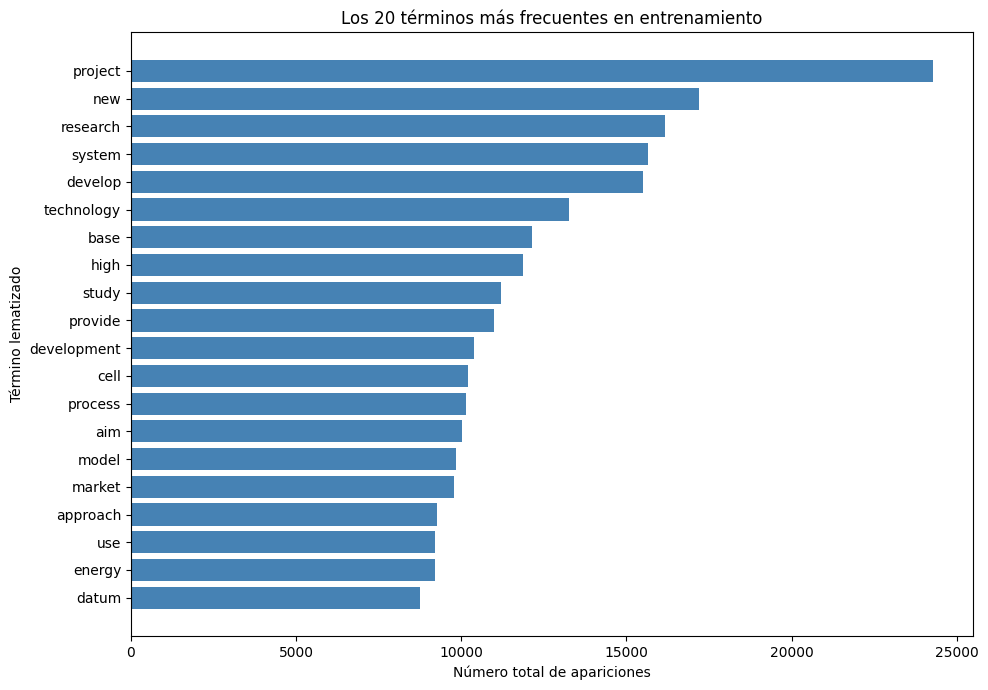

In [ ]:
# 22. CONTAR Y REPRESENTAR LOS TÉRMINOS MÁS FRECUENTES

from collections import Counter
import matplotlib.pyplot as plt

# Counter cuenta cuántas veces aparece cada elemento.
frecuencia_terminos = Counter()
resumenes_por_termino = Counter()

for palabras in datos_train["tokens_limpios"]:

    # Contamos todas las apariciones, incluidas las repeticiones.
    frecuencia_terminos.update(palabras)

    # set elimina las repeticiones dentro de este resumen.
    # Así cada término suma como máximo un resumen.
    resumenes_por_termino.update(set(palabras))

# Creamos una tabla ordenada de mayor a menor frecuencia.
tabla_terminos = pd.DataFrame(
    frecuencia_terminos.most_common(),
    columns=["termino", "apariciones"]
)

# Añadimos en cuántos resúmenes aparece cada término.
tabla_terminos["numero_resumenes"] = (
    tabla_terminos["termino"].map(resumenes_por_termino)
)

# Calculamos el porcentaje de resúmenes que contienen cada término.
tabla_terminos["porcentaje_resumenes"] = (
    100 * tabla_terminos["numero_resumenes"] / len(datos_train)
)

print("Términos diferentes tras el procesamiento:", len(tabla_terminos))
print("\nLos 20 términos con más apariciones:")
display(tabla_terminos.head(20).round(2))

# Guardamos la tabla completa, incluyendo los términos menos frecuentes.
tabla_terminos.to_csv(
    carpeta_resultados / "frecuencia_terminos_entrenamiento.csv",
    index=False,
    encoding="utf-8"
)

# Seleccionamos los 20 primeros.
# Los ordenamos para que el más frecuente quede arriba en la gráfica.
terminos_grafica = (
    tabla_terminos.head(20).sort_values("apariciones")
)

plt.figure(figsize=(10, 7))

plt.barh(
    terminos_grafica["termino"],
    terminos_grafica["apariciones"],
    color="steelblue"
)

plt.title("Los 20 términos más frecuentes en entrenamiento")
plt.xlabel("Número total de apariciones")
plt.ylabel("Término lematizado")
plt.tight_layout()

plt.savefig(
    carpeta_resultados / "terminos_frecuentes_entrenamiento.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

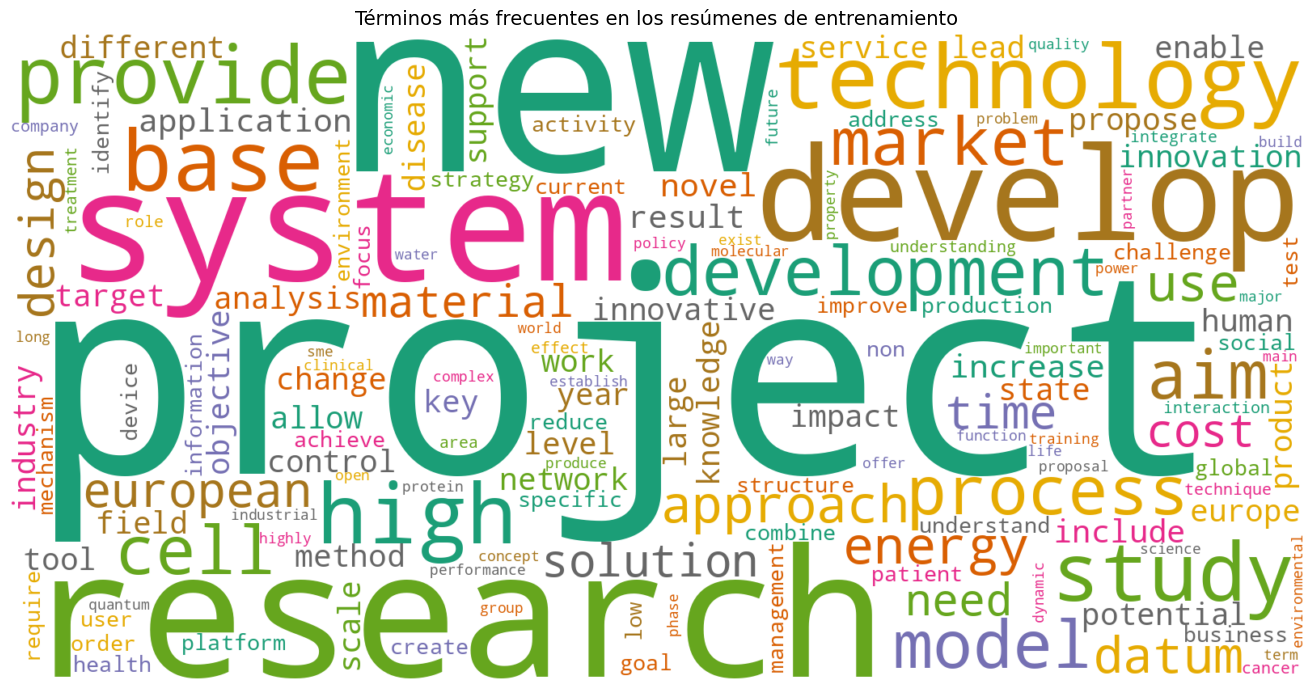

Guardado: nube_palabras_entrenamiento.png


In [ ]:
# 23. CREAR LA NUBE DE PALABRAS DEL ENTRENAMIENTO

# Instalamos la biblioteca si todavía no está disponible.
%pip install -q wordcloud

from wordcloud import WordCloud

# Configuramos la imagen.
# max_words limita la nube a los 150 términos más frecuentes.
# random_state fija la aleatoriedad para reproducir la distribución.
nube_palabras = WordCloud(
    width=1600,
    height=800,
    background_color="white",
    max_words=150,
    colormap="Dark2",
    random_state=SEMILLA
)

# Generamos la nube usando las frecuencias ya calculadas.
# Estos recuentos proceden únicamente de entrenamiento.
nube_palabras.generate_from_frequencies(frecuencia_terminos)

# Mostramos la imagen.
plt.figure(figsize=(14, 7))
plt.imshow(nube_palabras, interpolation="bilinear")
plt.axis("off")
plt.title(
    "Términos más frecuentes en los resúmenes de entrenamiento",
    fontsize=14
)
plt.tight_layout()

# Guardamos la figura para incorporarla al informe.
plt.savefig(
    carpeta_resultados / "nube_palabras_entrenamiento.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Guardado: nube_palabras_entrenamiento.png")

In [ ]:
# 24. SELECCIONAR EJEMPLOS DE CADA CATEGORÍA

# groupby agrupa los proyectos según su categoría de nivel 2.
# sample elige un proyecto al azar dentro de cada categoría.
# La semilla permite repetir la misma selección.
ejemplos_por_clase = (
    datos_train.groupby("nivel_2")
    .sample(n=1, random_state=SEMILLA)
)

# Conservamos la información necesaria para revisar cada ejemplo.
ejemplos_por_clase = ejemplos_por_clase[
    ["nivel_1", "nivel_2", "projectID", "title", "summary"]
].copy()

# Ordenamos los ejemplos por área general y categoría.
ejemplos_por_clase = (
    ejemplos_por_clase
    .sort_values(["nivel_1", "nivel_2"])
    .reset_index(drop=True)
)

# Guardamos los 39 ejemplos con sus resúmenes completos.
ejemplos_por_clase.to_csv(
    carpeta_resultados / "ejemplos_por_clase.csv",
    index=False,
    encoding="utf-8"
)

print("Categorías con un ejemplo:", ejemplos_por_clase["nivel_2"].nunique())
print("Guardado: ejemplos_por_clase.csv")

# Para esta primera lectura mostramos un ejemplo de cada área general.
# head(1) selecciona la primera fila de cada grupo.
ejemplos_mostrar = (
    ejemplos_por_clase.groupby("nivel_1").head(1)
)

for indice, fila in ejemplos_mostrar.iterrows():

    print("\nÁrea general:", fila["nivel_1"])
    print("Categoría:", fila["nivel_2"])
    print("Identificador del proyecto:", fila["projectID"])
    print("Título:", fila["title"])

    # Unimos los espacios y saltos de línea para facilitar la lectura.
    resumen = " ".join(fila["summary"].split())

    # Mostramos un fragmento de hasta 450 caracteres.
    fragmento = resumen[:450]

    if len(resumen) > 450:
        fragmento += "..."

    print("Fragmento del resumen:", fragmento)

Categorías con un ejemplo: 39
Guardado: ejemplos_por_clase.csv

Área general: agricultural sciences
Categoría: agricultural biotechnology
Identificador del proyecto: 758653
Título: Nanostructured catalyst overcoats for renewable chemical production from biomass
Fragmento del resumen: In the CATACOAT project, we will develop layer-by-layer solution-processed catalyst overcoating methods, which will result in catalysts that have both targeted and broad impacts. We will produce highly active, stable and selective catalysts for the upgrading of lignin – the largest natural source of aromatic chemicals – into commodity chemicals, which will have an important targeted impact. The broader impact of our work will lie in the productio...

Área general: engineering and technology
Categoría: chemical engineering
Identificador del proyecto: 791254
Título: Advanced Universal Control and monitoring solution to remotely manage complex power systems
Fragmento del resumen: To successfully transition to

In [ ]:
# 25. PREPROCESAR LOS RESÚMENES DE VALIDACIÓN

# Reutilizamos la misma función y el mismo modelo de spaCy
# que hemos empleado con los textos de entrenamiento.
tokens_validacion = []

documentos_val = nlp.pipe(
    datos_val["summary"],
    batch_size=64,
    n_process=1
)

for documento in tqdm(
    documentos_val,
    total=len(datos_val),
    desc="Procesando validación"
):
    tokens_validacion.append(limpiar_documento(documento))

# Guardamos las palabras procesadas en dos columnas nuevas.
# La columna summary conserva el resumen original.
datos_val["tokens_limpios"] = tokens_validacion
datos_val["texto_limpio"] = datos_val["tokens_limpios"].apply(" ".join)

# Comprobamos cuántos resúmenes han quedado sin palabras.
sin_palabras_val = datos_val["tokens_limpios"].apply(len) == 0

print("\nProyectos procesados:", len(datos_val))
print("Resúmenes sin palabras tras el filtrado:", sin_palabras_val.sum())

# Mostramos los casos vacíos para conocer su contenido original.
# Conservamos estas filas en el conjunto de validación.
if sin_palabras_val.any():
    print("\nResúmenes que han quedado sin palabras:")
    display(
        datos_val.loc[
            sin_palabras_val,
            ["projectID", "summary", "nivel_2"]
        ]
    )

# Guardamos los textos procesados junto a sus identificadores.
datos_val[["projectID", "texto_limpio"]].to_csv(
    carpeta_resultados / "validacion_procesada.csv",
    index=False,
    encoding="utf-8"
)

print("\nGuardado: validacion_procesada.csv")

Procesando validación:   0%|          | 0/6397 [00:00<?, ?it/s]


Proyectos procesados: 6397
Resúmenes sin palabras tras el filtrado: 1

Resúmenes que han quedado sin palabras:


,projectID,summary,nivel_2
15504,743407,H2020,political sciences



Guardado: validacion_procesada.csv


In [ ]:
# 26. CONVERTIR LOS TEXTOS EN VECTORES TF-IDF

import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# Definimos cómo construiremos la representación.
vectorizador_tfidf = TfidfVectorizer(
    # El texto ya está en minúsculas y separado por espacios.
    lowercase=False,
    tokenizer=str.split,
    token_pattern=None,

    # Incluimos palabras individuales y parejas de palabras.
    ngram_range=(1, 2),

    # Filtramos según el número de resúmenes que contienen el término.
    min_df=3,
    max_df=0.95,

    # Si quedan más términos, conservamos los 50.000 más frecuentes.
    max_features=50000,

    # Suavizamos el efecto de repetir muchas veces un término.
    sublinear_tf=True,

    # Ajustamos la escala de cada vector mediante normalización L2.
    norm="l2",

    # Usamos números de 32 bits para reducir el consumo de memoria.
    dtype=np.float32
)

# fit_transform aprende el vocabulario y los pesos IDF
# utilizando únicamente los textos de entrenamiento.
# También devuelve su representación numérica.
X_train_tfidf = vectorizador_tfidf.fit_transform(
    datos_train["texto_limpio"]
)

# transform representa validación utilizando el vocabulario
# y los pesos que ya hemos aprendido con entrenamiento.
X_val_tfidf = vectorizador_tfidf.transform(
    datos_val["texto_limpio"]
)

# shape indica (número de proyectos, número de términos).
print("Tamaño de entrenamiento:", X_train_tfidf.shape)
print("Tamaño de validación:", X_val_tfidf.shape)

# getnnz(axis=1) cuenta los valores distintos de cero de cada fila.
# Una fila vacía no contiene ningún término del vocabulario elegido.
filas_cero_train = (
    X_train_tfidf.getnnz(axis=1) == 0
).sum()

filas_cero_val = (
    X_val_tfidf.getnnz(axis=1) == 0
).sum()

print("Filas completamente a cero en entrenamiento:", filas_cero_train)
print("Filas completamente a cero en validación:", filas_cero_val)

Tamaño de entrenamiento: (19188, 50000)
Tamaño de validación: (6397, 50000)
Filas completamente a cero en entrenamiento: 0
Filas completamente a cero en validación: 1


In [ ]:
# 27. ENTRENAR Y EVALUAR UN SVM LINEAL CON TF-IDF

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
from time import perf_counter

# Las X contienen las representaciones numéricas de los resúmenes.
# Las y contienen las categorías que debe aprender a predecir el modelo.
y_train = datos_train["nivel_2"].to_numpy()
y_val = datos_val["nivel_2"].to_numpy()

# Creamos una primera configuración del clasificador.
modelo_svm_tfidf = LinearSVC(
    # C controla el equilibrio entre ajustar los ejemplos
    # y limitar los pesos del modelo. Empezamos probando 1.
    C=1.0,

    # Damos más peso a las categorías con menos proyectos.
    class_weight="balanced",

    # Seleccionamos automáticamente el método de optimización.
    dual="auto",

    # Fijamos el límite de iteraciones y la semilla.
    max_iter=5000,
    random_state=SEMILLA
)

# fit aprende utilizando los textos y las categorías de entrenamiento.
print("Entrenando el SVM lineal...")

inicio = perf_counter()
modelo_svm_tfidf.fit(X_train_tfidf, y_train)
tiempo_svm_tfidf = perf_counter() - inicio

# predict asigna una categoría a cada proyecto de validación.
pred_svm_tfidf_val = modelo_svm_tfidf.predict(X_val_tfidf)

# Comparamos las predicciones con las categorías reales.
accuracy_svm_tfidf_val = accuracy_score(
    y_val,
    pred_svm_tfidf_val
)

f1_macro_svm_tfidf_val = f1_score(
    y_val,
    pred_svm_tfidf_val,
    labels=clases_nivel2,
    average="macro",
    zero_division=0
)

print("\nCategorías del modelo:", len(modelo_svm_tfidf.classes_))
print(f"Accuracy en validación: {accuracy_svm_tfidf_val:.2%}")
print(f"F1-macro en validación: {f1_macro_svm_tfidf_val:.4f}")
print(f"Tiempo de entrenamiento: {tiempo_svm_tfidf:.1f} segundos")
print("Iteraciones, máximo entre las clases:", modelo_svm_tfidf.n_iter_)

# Guardamos esta primera configuración y sus resultados.
resultados_svm_tfidf = pd.DataFrame([{
    "modelo": "SVM lineal",
    "representacion": "TF-IDF",
    "conjunto": "validacion",
    "C": modelo_svm_tfidf.C,
    "class_weight": modelo_svm_tfidf.class_weight,
    "accuracy": accuracy_svm_tfidf_val,
    "f1_macro": f1_macro_svm_tfidf_val,
    "tiempo_entrenamiento_s": tiempo_svm_tfidf
}])

resultados_svm_tfidf.to_csv(
    carpeta_resultados / "svm_tfidf_inicial_validacion.csv",
    index=False,
    encoding="utf-8"
)

print("\nGuardado: svm_tfidf_inicial_validacion.csv")

Entrenando el SVM lineal...

Categorías del modelo: 39
Accuracy en validación: 53.71%
F1-macro en validación: 0.4127
Tiempo de entrenamiento: 8.0 segundos
Iteraciones, máximo entre las clases: 112

Guardado: svm_tfidf_inicial_validacion.csv


In [ ]:
# 28. REVISAR LOS RESULTADOS DEL SVM POR CATEGORÍA

from sklearn.metrics import precision_recall_fscore_support

# Calculamos las métricas de cada categoría por separado.
# average=None devuelve un resultado por categoría, sin promediarlos.
precision_clase, recall_clase, f1_clase, soporte_clase = (
    precision_recall_fscore_support(
        y_val,
        pred_svm_tfidf_val,
        labels=clases_nivel2,
        average=None,
        zero_division=0
    )
)

# Cada fila corresponde a una de las 39 categorías.
tabla_clases_svm_tfidf = pd.DataFrame({
    "categoria": clases_nivel2,
    "precision": precision_clase,
    "recall": recall_clase,
    "f1": f1_clase,
    "proyectos_validacion": soporte_clase
})

# Ordenamos primero las categorías con menor F1.
# En caso de empate, ponemos antes las que tienen más ejemplos.
tabla_clases_svm_tfidf = tabla_clases_svm_tfidf.sort_values(
    ["f1", "proyectos_validacion"],
    ascending=[True, False]
).reset_index(drop=True)

# Guardamos las métricas completas, sin redondear.
tabla_clases_svm_tfidf.to_csv(
    carpeta_resultados / "svm_tfidf_inicial_por_clase_validacion.csv",
    index=False,
    encoding="utf-8"
)

print("Categorías evaluadas:", len(tabla_clases_svm_tfidf))
print(
    "Proyectos contabilizados:",
    tabla_clases_svm_tfidf["proyectos_validacion"].sum()
)

# Mostramos las diez categorías con menor F1.
# El redondeo afecta únicamente a esta visualización.
print("\nLas 10 categorías con menor F1 en validación:")
display(tabla_clases_svm_tfidf.head(10).round(4))

Categorías evaluadas: 39
Proyectos contabilizados: 6397

Las 10 categorías con menor F1 en validación:


,categoria,precision,recall,f1,proyectos_validacion
0,environmental biotechnology,0.0000,0.0000,0.0000,6
1,other medical sciences,0.0000,0.0000,0.0000,2
2,agricultural biotechnology,0.2000,0.1429,0.1667,7
3,medical engineering,0.2000,0.1538,0.1739,26
4,other humanities,0.2857,0.1538,0.2000,13
5,media and communications,1.0000,0.1250,0.2222,8
6,industrial biotechnology,0.3333,0.2105,0.2581,19
7,civil engineering,0.2742,0.2698,0.2720,63
8,animal and dairy science,0.2174,0.3704,0.2740,27
9,arts,0.3438,0.2821,0.3099,39


In [ ]:
# 29. COMPARAR CONFIGURACIONES DEL SVM CON VALIDACIÓN

valores_c = [0.1, 1.0, 10.0]
opciones_peso = [None, "balanced"]

resultados_ajuste = []

# El F1 siempre está entre 0 y 1.
# Empezamos en -1 para poder guardar la primera configuración.
mejor_f1_svm = -1.0
mejor_svm_tfidf = None
pred_mejor_svm_tfidf_val = None

# Probamos cada combinación de C y ponderación de clases.
for valor_c in valores_c:
    for peso in opciones_peso:

        nombre_peso = "sin ponderar" if peso is None else "balanced"
        print(f"Probando C={valor_c}, pesos={nombre_peso}...", flush=True)

        # Creamos un modelo nuevo para esta combinación.
        svm_actual = LinearSVC(
            C=valor_c,
            class_weight=peso,
            dual="auto",
            max_iter=5000,
            random_state=SEMILLA
        )

        # Entrenamos únicamente con entrenamiento.
        inicio = perf_counter()
        svm_actual.fit(X_train_tfidf, y_train)
        tiempo_actual = perf_counter() - inicio

        # Evaluamos la configuración en validación.
        pred_actual = svm_actual.predict(X_val_tfidf)

        accuracy_actual = accuracy_score(y_val, pred_actual)

        f1_actual = f1_score(
            y_val,
            pred_actual,
            labels=clases_nivel2,
            average="macro",
            zero_division=0
        )

        # Guardamos las métricas y el coste del entrenamiento.
        resultados_ajuste.append({
            "C": valor_c,
            "pesos_clase": nombre_peso,
            "accuracy": accuracy_actual,
            "f1_macro": f1_actual,
            "tiempo_s": tiempo_actual,
            "iteraciones": svm_actual.n_iter_
        })

        # Conservamos el modelo y las predicciones si mejora el F1.
        # Si hay un empate exacto, mantenemos el primero.
        if f1_actual > mejor_f1_svm:
            mejor_f1_svm = f1_actual
            mejor_svm_tfidf = svm_actual
            pred_mejor_svm_tfidf_val = pred_actual

# Ordenamos las configuraciones de mayor a menor F1-macro.
# El orden estable conserva el orden de prueba en caso de empate.
tabla_ajuste_svm = (
    pd.DataFrame(resultados_ajuste)
    .sort_values("f1_macro", ascending=False, kind="stable")
    .reset_index(drop=True)
)

# Guardamos los resultados completos, sin redondear.
tabla_ajuste_svm.to_csv(
    carpeta_resultados / "ajuste_svm_tfidf_validacion.csv",
    index=False,
    encoding="utf-8"
)

print("\nResultados ordenados por F1-macro:")
display(tabla_ajuste_svm.round(4))

print("\nMejor C:", mejor_svm_tfidf.C)
print("Ponderación seleccionada:", mejor_svm_tfidf.class_weight)
print(f"Mejor F1-macro en validación: {mejor_f1_svm:.4f}")

Probando C=0.1, pesos=sin ponderar...
Probando C=0.1, pesos=balanced...
Probando C=1.0, pesos=sin ponderar...
Probando C=1.0, pesos=balanced...
Probando C=10.0, pesos=sin ponderar...
Probando C=10.0, pesos=balanced...

Resultados ordenados por F1-macro:


,C,pesos_clase,accuracy,f1_macro,tiempo_s,iteraciones
0,1.0,balanced,0.5371,0.4127,7.2805,112
1,0.1,balanced,0.5082,0.4045,12.1618,37
2,10.0,balanced,0.5115,0.3711,20.4676,487
3,1.0,sin ponderar,0.5304,0.3601,7.9316,40
4,10.0,sin ponderar,0.5077,0.3538,21.7971,334
5,0.1,sin ponderar,0.5246,0.3122,14.2045,12



Mejor C: 1.0
Ponderación seleccionada: balanced
Mejor F1-macro en validación: 0.4127


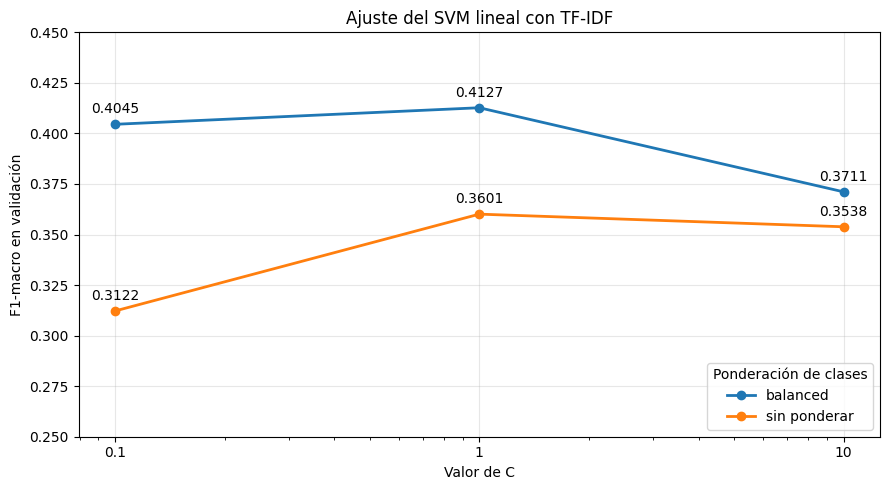

In [ ]:
# 30. REPRESENTAR EL AJUSTE DEL SVM

plt.figure(figsize=(9, 5))

# Dibujamos una línea por cada opción de ponderación.
for pesos, grupo in tabla_ajuste_svm.groupby("pesos_clase"):

    # Ordenamos por C para conectar los puntos correctamente.
    grupo = grupo.sort_values("C")

    plt.plot(
        grupo["C"],
        grupo["f1_macro"],
        marker="o",
        linewidth=2,
        label=pesos
    )

    # Escribimos el F1-macro junto a cada punto.
    for indice, fila in grupo.iterrows():
        plt.annotate(
            f"{fila['f1_macro']:.4f}",
            (fila["C"], fila["f1_macro"]),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center"
        )

# La escala logarítmica separa por igual los pasos:
# de 0.1 a 1 y de 1 a 10, que multiplican C por diez.
plt.xscale("log")
plt.xticks([0.1, 1.0, 10.0], ["0.1", "1", "10"])

# Ampliamos la zona donde están nuestros resultados.
# La escala completa del F1 sigue siendo de 0 a 1.
plt.ylim(0.25, 0.45)

plt.xlabel("Valor de C")
plt.ylabel("F1-macro en validación")
plt.title("Ajuste del SVM lineal con TF-IDF")
plt.legend(title="Ponderación de clases", loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Guardamos la figura para el informe.
plt.savefig(
    carpeta_resultados / "curva_validacion_svm_tfidf.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# 31. GUARDAR EL MODELO Y DESCARGAR UNA COPIA DE SEGURIDAD

import joblib
import json
import platform
import shutil
from importlib.metadata import version
from google.colab import files

# Guardamos juntos el vectorizador y el mejor clasificador.
# El clasificador necesita el mismo vectorizador con el que se entrenó.
modelo_guardado = {
    "vectorizador": vectorizador_tfidf,
    "clasificador": mejor_svm_tfidf,
    "clases_nivel2": clases_nivel2,
    "semilla": SEMILLA
}

ruta_modelo = carpeta_resultados / "modelo_tfidf_svm.joblib"

# compress reduce el tamaño del archivo.
joblib.dump(modelo_guardado, ruta_modelo, compress=3)

# Registramos las versiones utilizadas para poder reproducir el trabajo.
versiones = {
    "python": platform.python_version(),
    "en_core_web_sm": nlp.meta["version"],
    "semilla": SEMILLA
}

for paquete in [
    "numpy", "pandas", "scipy", "scikit-learn",
    "spacy", "wordcloud", "joblib"
]:
    versiones[paquete] = version(paquete)

with open(
    carpeta_resultados / "versiones_hasta_tfidf.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(versiones, archivo, ensure_ascii=False, indent=4)

# Comprimimos toda la carpeta de resultados:
# tablas, gráficas, textos procesados y modelo guardado.
# El ZIP se crea fuera de esa carpeta.
ruta_respaldo = shutil.make_archive(
    "/content/respaldo_resultados_tfidf",
    "zip",
    root_dir=str(carpeta_resultados)
)

print("Modelo guardado:", ruta_modelo.name)
print("Copia preparada:", ruta_respaldo)

# Descargamos la copia al ordenador.
files.download(ruta_respaldo)

Modelo guardado: modelo_tfidf_svm.joblib
Copia preparada: /content/respaldo_resultados_tfidf.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 32. PREPARAR WORD2VEC

# Instalamos la biblioteca que vamos a utilizar.
%pip install -q gensim

import gensim
from gensim.models import Word2Vec

# Comprobamos que se ha instalado correctamente.
print("Versión de Gensim:", gensim.__version__)

# Comprobamos que tenemos los textos de entrenamiento preparados.
print("Resúmenes disponibles:", len(datos_train))
print("Primeras palabras del primer resumen:")
print(datos_train["tokens_limpios"].iloc[0][:15])

Versión de Gensim: 4.4.0
Resúmenes disponibles: 19188
Primeras palabras del primer resumen:
['current', 'ebola', 'virus', 'disease', 'evd', 'outbreak', 'cause', 'death', 'month', 'west', 'africa', 'guinea', 'sierra', 'leone', 'liberia']


In [ ]:
# 33. ENTRENAMIENTO DE WORD2VEC

# Preparamos las palabras de los resúmenes de entrenamiento.
textos_w2v = datos_train["tokens_limpios"].tolist()

# Entrenamos Word2Vec con nuestros textos.
modelo_w2v = Word2Vec(
    sentences=textos_w2v,
    vector_size=200,
    window=5,
    min_count=5,
    sg=1,
    workers=1,
    seed=42,
    epochs=5
)

# Comprobamos que el entrenamiento ha terminado.
print("Word2Vec entrenado correctamente")
print("Dimensiones de los vectores:", modelo_w2v.vector_size)
print("Palabras en el vocabulario:", len(modelo_w2v.wv))

Word2Vec entrenado correctamente
Dimensiones de los vectores: 200
Palabras en el vocabulario: 20904


In [ ]:
# 34. CREAR LOS VECTORES DE LOS RESÚMENES CON WORD2VEC

# Esta función convierte las palabras de un resumen
# en un único vector calculando su media.
def vector_resumen(palabras, modelo):

    vectores = []

    for palabra in palabras:

        # Solo utilizamos palabras conocidas por Word2Vec.
        if palabra in modelo.wv:
            vectores.append(modelo.wv[palabra])

    # Si no encontramos ninguna palabra conocida,
    # devolvemos un vector de ceros.
    if len(vectores) == 0:
        return np.zeros(modelo.vector_size, dtype=np.float32)

    # Calculamos el vector medio del resumen.
    return np.mean(vectores, axis=0)


# Convertimos los resúmenes de entrenamiento.
X_train_w2v = np.array([
    vector_resumen(palabras, modelo_w2v)
    for palabras in datos_train["tokens_limpios"]
])

# Convertimos los resúmenes de validación.
X_val_w2v = np.array([
    vector_resumen(palabras, modelo_w2v)
    for palabras in datos_val["tokens_limpios"]
])


# Comprobamos las dimensiones obtenidas.
print("Entrenamiento:", X_train_w2v.shape)
print("Validación:", X_val_w2v.shape)

# Comprobamos si algún resumen ha quedado sin representación.
print("Vectores vacíos en entrenamiento:",
      np.sum(np.all(X_train_w2v == 0, axis=1)))

print("Vectores vacíos en validación:",
      np.sum(np.all(X_val_w2v == 0, axis=1)))

Entrenamiento: (19188, 200)
Validación: (6397, 200)
Vectores vacíos en entrenamiento: 0
Vectores vacíos en validación: 1


In [ ]:
# 35. ESTANDARIZAR LOS VECTORES DE WORD2VEC

from sklearn.preprocessing import StandardScaler

# Creamos el escalador.
escalador_w2v = StandardScaler()

# Ajustamos el escalador solo con entrenamiento.
X_train_w2v_scaled = escalador_w2v.fit_transform(X_train_w2v)

# Aplicamos el mismo escalador a validación.
X_val_w2v_scaled = escalador_w2v.transform(X_val_w2v)

# Comprobamos los resultados.
print("Entrenamiento:", X_train_w2v_scaled.shape)
print("Validación:", X_val_w2v_scaled.shape)

print("Media de entrenamiento:",
      np.mean(X_train_w2v_scaled))

print("Desviación típica de entrenamiento:",
      np.std(X_train_w2v_scaled))

Entrenamiento: (19188, 200)
Validación: (6397, 200)
Media de entrenamiento: -4.771354e-10
Desviación típica de entrenamiento: 1.0


In [ ]:
# 36. ENTRENAR Y EVALUAR UN SVM CON WORD2VEC

# Creamos el clasificador SVM.
modelo_svm_w2v = LinearSVC(
    C=1.0,
    class_weight="balanced",
    dual="auto",
    max_iter=5000,
    random_state=SEMILLA
)

# Entrenamos utilizando los vectores Word2Vec.
print("Entrenando SVM con Word2Vec...")

inicio = perf_counter()

modelo_svm_w2v.fit(X_train_w2v_scaled, y_train)

tiempo_svm_w2v = perf_counter() - inicio

# Predecimos las categorías de validación.
pred_svm_w2v_val = modelo_svm_w2v.predict(X_val_w2v_scaled)

# Calculamos las métricas.
accuracy_svm_w2v_val = accuracy_score(
    y_val,
    pred_svm_w2v_val
)

f1_macro_svm_w2v_val = f1_score(
    y_val,
    pred_svm_w2v_val,
    labels=clases_nivel2,
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("\nCategorías del modelo:", len(modelo_svm_w2v.classes_))
print(f"Accuracy en validación: {accuracy_svm_w2v_val:.2%}")
print(f"F1-macro en validación: {f1_macro_svm_w2v_val:.4f}")
print(f"Tiempo de entrenamiento: {tiempo_svm_w2v:.1f} segundos")

# Guardamos los resultados.
resultados_svm_w2v = pd.DataFrame([{
    "modelo": "SVM lineal",
    "representacion": "Word2Vec",
    "conjunto": "validacion",
    "C": modelo_svm_w2v.C,
    "class_weight": modelo_svm_w2v.class_weight,
    "accuracy": accuracy_svm_w2v_val,
    "f1_macro": f1_macro_svm_w2v_val,
    "tiempo_entrenamiento_s": tiempo_svm_w2v
}])

resultados_svm_w2v.to_csv(
    carpeta_resultados / "svm_w2v_inicial_validacion.csv",
    index=False,
    encoding="utf-8"
)

print("\nResultados guardados en svm_w2v_inicial_validacion.csv")

Entrenando SVM con Word2Vec...

Categorías del modelo: 39
Accuracy en validación: 38.35%
F1-macro en validación: 0.2730
Tiempo de entrenamiento: 55.4 segundos

Resultados guardados en svm_w2v_inicial_validacion.csv


In [ ]:
# 37. AJUSTAR LOS PARAMETROS DEL SVM CON WORD2VEC

# Probamos distintas configuraciones del clasificador.
configuraciones = [
    (0.1, None),
    (1.0, None),
    (0.1, "balanced"),
    (1.0, "balanced")
]

resultados_ajuste_w2v = []

for C, pesos in configuraciones:

    # Ya tenemos entrenada esta configuración del paso 36.
    if C == 1.0 and pesos == "balanced":
        accuracy = accuracy_svm_w2v_val
        f1 = f1_macro_svm_w2v_val
        tiempo = tiempo_svm_w2v

    else:
        modelo = LinearSVC(
            C=C,
            class_weight=pesos,
            dual="auto",
            max_iter=5000,
            random_state=SEMILLA
        )

        inicio = perf_counter()
        modelo.fit(X_train_w2v_scaled, y_train)
        tiempo = perf_counter() - inicio

        predicciones = modelo.predict(X_val_w2v_scaled)

        accuracy = accuracy_score(y_val, predicciones)
        f1 = f1_score(
            y_val,
            predicciones,
            labels=clases_nivel2,
            average="macro",
            zero_division=0
        )

    resultados_ajuste_w2v.append({
        "C": C,
        "class_weight": str(pesos),
        "accuracy": accuracy,
        "f1_macro": f1,
        "tiempo_s": tiempo
    })

# Mostramos los resultados ordenados por F1-macro.
tabla_ajuste_w2v = pd.DataFrame(resultados_ajuste_w2v)
tabla_ajuste_w2v = tabla_ajuste_w2v.sort_values(
    "f1_macro", ascending=False
)

print(tabla_ajuste_w2v.to_string(index=False))

# Guardamos los resultados.
tabla_ajuste_w2v.to_csv(
    carpeta_resultados / "ajuste_svm_w2v.csv",
    index=False
)

print("\nResultados del ajuste guardados correctamente")

  C class_weight  accuracy  f1_macro  tiempo_s
1.0         None  0.462717  0.292234 45.100762
0.1         None  0.467719  0.287047 49.264266
0.1     balanced  0.382523  0.275507 43.950020
1.0     balanced  0.383461  0.273043 55.427418

Resultados del ajuste guardados correctamente


In [ ]:
# 38. ENTRENAR EL MEJOR SVM CON WORD2VEC

# Creamos el modelo con los mejores parámetros.
mejor_svm_w2v = LinearSVC(
    C=1.0,
    class_weight=None,
    dual="auto",
    max_iter=5000,
    random_state=SEMILLA
)

# Entrenamos con los datos de entrenamiento.
mejor_svm_w2v.fit(X_train_w2v_scaled, y_train)

# Realizamos las predicciones de validación.
pred_mejor_w2v = mejor_svm_w2v.predict(X_val_w2v_scaled)

# Calculamos las métricas.
accuracy_mejor_w2v = accuracy_score(y_val, pred_mejor_w2v)

f1_mejor_w2v = f1_score(
    y_val,
    pred_mejor_w2v,
    labels=clases_nivel2,
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("Mejor modelo Word2Vec entrenado correctamente")
print("Categorías:", len(mejor_svm_w2v.classes_))
print(f"Accuracy en validación: {accuracy_mejor_w2v:.2%}")
print(f"F1-macro en validación: {f1_mejor_w2v:.4f}")

Mejor modelo Word2Vec entrenado correctamente
Categorías: 39
Accuracy en validación: 46.27%
F1-macro en validación: 0.2922


In [ ]:
# 39. GUARDAR LOS RESULTADOS DE WORD2VEC

import joblib

# Guardamos el modelo Word2Vec entrenado.
modelo_w2v.save(
    str(carpeta_resultados / "modelo_word2vec.model")
)

# Guardamos el escalador utilizado.
joblib.dump(
    escalador_w2v,
    carpeta_resultados / "escalador_word2vec.joblib"
)

# Guardamos el mejor clasificador SVM.
joblib.dump(
    mejor_svm_w2v,
    carpeta_resultados / "modelo_svm_word2vec.joblib"
)

# Guardamos los vectores de entrenamiento y validación.
np.savez_compressed(
    carpeta_resultados / "vectores_word2vec.npz",
    X_train=X_train_w2v_scaled,
    X_val=X_val_w2v_scaled
)

# Guardamos las métricas del mejor modelo.
resultados_finales_w2v = pd.DataFrame([{
    "representacion": "Word2Vec",
    "modelo": "SVM lineal",
    "C": 1.0,
    "class_weight": "None",
    "accuracy": accuracy_mejor_w2v,
    "f1_macro": f1_mejor_w2v
}])

resultados_finales_w2v.to_csv(
    carpeta_resultados / "resultados_word2vec.csv",
    index=False
)

print("Modelo Word2Vec guardado correctamente")
print("Escalador guardado correctamente")
print("SVM guardado correctamente")
print("Vectores guardados correctamente")
print("Métricas guardadas correctamente")

Modelo Word2Vec guardado correctamente
Escalador guardado correctamente
SVM guardado correctamente
Vectores guardados correctamente
Métricas guardadas correctamente


In [ ]:
# 40. COPIA DE SEGURIDAD DE TF-IDF Y WORD2VEC

import shutil
from google.colab import files
from pathlib import Path

# Comprimimos la carpeta completa de resultados.
ruta_respaldo = shutil.make_archive(
    "/content/respaldo_resultados_tfidf_word2vec",
    "zip",
    root_dir=str(carpeta_resultados)
)

# Comprobamos que el ZIP se ha creado correctamente.
tamano_mb = Path(ruta_respaldo).stat().st_size / (1024 * 1024)

print("Copia de seguridad creada correctamente")
print("Archivo:", ruta_respaldo)
print(f"Tamaño: {tamano_mb:.2f} MB")

# Descargamos la copia al ordenador.
files.download(ruta_respaldo)

Copia de seguridad creada correctamente
Archivo: /content/respaldo_resultados_tfidf_word2vec.zip
Tamaño: 73.03 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 41. COMPROBAR SI TENEMOS GPU DISPONIBLE

import torch

# Comprobamos si Google Colab tiene una GPU activa.
if torch.cuda.is_available():
    print("GPU disponible")
    print("Modelo:", torch.cuda.get_device_name(0))
else:
    print("No hay GPU disponible")
    print("Estamos utilizando la CPU")

print("Versión de PyTorch:", torch.__version__)

GPU disponible
Modelo: Tesla T4
Versión de PyTorch: 2.14.1+cu130


In [ ]:
# 44. RECUPERAR LOS DATOS Y RESULTADOS

from pathlib import Path
import zipfile

# Creamos las carpetas necesarias.
carpeta_datos = Path("/content/datos")
carpeta_resultados = Path("/content/resultados")

carpeta_datos.mkdir(exist_ok=True)
carpeta_resultados.mkdir(exist_ok=True)

# Recuperamos los datos originales.
with zipfile.ZipFile("/content/H2020.zip", "r") as archivo:
    archivo.extractall(carpeta_datos)

# Recuperamos los resultados y modelos anteriores.
with zipfile.ZipFile(
    "/content/respaldo_resultados_tfidf_word2vec.zip", "r"
) as archivo:
    archivo.extractall(carpeta_resultados)

# Comprobamos los archivos recuperados.
print("Datos originales:")
print("projects.xlsx:", (carpeta_datos / "projects.xlsx").exists())
print("SciVocCodes.xlsx:", (carpeta_datos / "SciVocCodes.xlsx").exists())

print("\nModelos recuperados:")
print("Word2Vec:", (carpeta_resultados / "modelo_word2vec.model").exists())
print("SVM Word2Vec:", (carpeta_resultados / "modelo_svm_word2vec.joblib").exists())

print("\nTotal de archivos de resultados:",
      sum(1 for archivo in carpeta_resultados.rglob("*") if archivo.is_file()))

Datos originales:
projects.xlsx: True
SciVocCodes.xlsx: True

Modelos recuperados:
Word2Vec: True
SVM Word2Vec: True

Total de archivos de resultados: 26


In [ ]:
# 45. RECUPERAR LOS CONJUNTOS DE DATOS

import pandas as pd
import numpy as np

# Leemos los identificadores y resúmenes originales.
proyectos = pd.read_excel(
    carpeta_datos / "projects.xlsx",
    usecols=["projectID", "summary"]
)

# Recuperamos el reparto que habíamos guardado.
particiones = pd.read_csv(
    carpeta_resultados / "particiones.csv"
)

# Unimos los resúmenes con sus categorías y particiones.
datos = particiones.merge(
    proyectos,
    on="projectID",
    how="left",
    validate="one_to_one"
)

# Comprobamos que no hemos perdido proyectos ni resúmenes.
assert len(datos) == len(particiones)
assert datos["summary"].notna().all()

# Recuperamos los tres conjuntos originales.
datos_train = datos[datos["particion"] == "entrenamiento"].copy()
datos_val = datos[datos["particion"] == "validacion"].copy()
datos_test = datos[datos["particion"] == "prueba"].copy()

# Recuperamos las etiquetas necesarias.
y_train = datos_train["nivel_2"].to_numpy()
y_val = datos_val["nivel_2"].to_numpy()

clases_nivel2 = sorted(datos["nivel_2"].unique())

# Comprobamos los resultados.
print("Entrenamiento:", len(datos_train))
print("Validación:", len(datos_val))
print("Prueba:", len(datos_test))
print("Categorías de nivel 2:", len(clases_nivel2))
print("Total de proyectos:", len(datos))

Entrenamiento: 19188
Validación: 6397
Prueba: 6397
Categorías de nivel 2: 39
Total de proyectos: 31982


In [ ]:
# 46. PREPARAR LAS BIBLIOTECAS PARA TRANSFORMERS

# Instalamos la biblioteca de Hugging Face.
%pip install -q transformers

import transformers
from transformers import AutoTokenizer, AutoModel

# Elegimos el modelo preentrenado.
nombre_transformer = "distilbert-base-uncased"

# Comprobamos que todo está preparado.
print("Transformers instalado correctamente")
print("Versión:", transformers.__version__)
print("Modelo seleccionado:", nombre_transformer)

# Comprobamos que seguimos teniendo la GPU.
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Transformers instalado correctamente
Versión: 5.22.1
Modelo seleccionado: distilbert-base-uncased
GPU disponible: True
GPU: Tesla T4


In [ ]:
# 47. CARGAR EL MODELO DISTILBERT

# Seleccionamos la GPU para realizar los cálculos.
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Cargamos el tokenizador del modelo.
tokenizador = AutoTokenizer.from_pretrained(nombre_transformer)

# Cargamos el modelo preentrenado.
modelo_transformer = AutoModel.from_pretrained(nombre_transformer)

# Enviamos el modelo a la GPU.
modelo_transformer = modelo_transformer.to(dispositivo)

# Activamos el modo evaluación.
# No vamos a modificar los pesos del modelo.
modelo_transformer.eval()

# Comprobamos que todo se ha cargado correctamente.
print("DistilBERT cargado correctamente")
print("Dispositivo:", dispositivo)
print("Dimensiones de los vectores:", modelo_transformer.config.hidden_size)
print("Longitud máxima:", tokenizador.model_max_length)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT cargado correctamente
Dispositivo: cuda
Dimensiones de los vectores: 768
Longitud máxima: 512


In [ ]:
# 48. PROBAR DISTILBERT CON DOS RESÚMENES

# Seleccionamos dos resúmenes de entrenamiento.
textos_ejemplo = datos_train["summary"].iloc[:2].tolist()

# Convertimos los textos en tokens.
entradas = tokenizador(
    textos_ejemplo,
    padding=True,
    truncation=True,
    max_length=512,
    return_tensors="pt"
)

# Enviamos los datos a la GPU.
entradas = {
    clave: valor.to(dispositivo)
    for clave, valor in entradas.items()
}

# Obtenemos los vectores sin entrenar el modelo.
with torch.no_grad():
    salidas = modelo_transformer(**entradas)

    # Calculamos la media de los vectores de los tokens válidos.
    mascara = entradas["attention_mask"].unsqueeze(-1)

    vectores_ejemplo = (
        (salidas.last_hidden_state * mascara).sum(dim=1)
        / mascara.sum(dim=1)
    )

# Comprobamos las dimensiones.
print("Resúmenes procesados:", len(textos_ejemplo))
print("Dimensiones de entrada:", entradas["input_ids"].shape)
print("Dimensiones de los vectores:", vectores_ejemplo.shape)
print("Dispositivo:", vectores_ejemplo.device)

Resúmenes procesados: 2
Dimensiones de entrada: torch.Size([2, 369])
Dimensiones de los vectores: torch.Size([2, 768])
Dispositivo: cuda:0


In [ ]:
# 49. OBTENER LOS EMBEDDINGS CONTEXTUALES DE ENTRENAMIENTO

# Creamos una función para convertir resúmenes en vectores.
def crear_embeddings(textos, tamano_lote=16):

    # Reservamos espacio para guardar los vectores.
    vectores = np.zeros(
        (len(textos), 768),
        dtype=np.float32
    )

    # Utilizamos DistilBERT sin modificar sus pesos.
    modelo_transformer.eval()

    # Procesamos los resúmenes por grupos.
    for inicio in range(0, len(textos), tamano_lote):

        lote = textos[inicio:inicio + tamano_lote]

        # Convertimos los resúmenes originales en tokens.
        entradas = tokenizador(
            lote,
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        )

        # Enviamos las entradas a la GPU.
        entradas = {
            clave: valor.to(dispositivo)
            for clave, valor in entradas.items()
        }

        # Obtenemos los embeddings sin entrenar DistilBERT.
        with torch.no_grad():

            salidas = modelo_transformer(**entradas)

            # Calculamos la media de los tokens válidos.
            mascara = entradas["attention_mask"].unsqueeze(-1)

            vectores_lote = (
                (salidas.last_hidden_state * mascara).sum(dim=1)
                / mascara.sum(dim=1).clamp(min=1)
            )

        # Guardamos los vectores del grupo en memoria.
        vectores[inicio:inicio + len(lote)] = (
            vectores_lote.cpu().numpy()
        )

        # Mostramos el progreso cada 100 grupos.
        if (inicio // tamano_lote + 1) % 100 == 0:
            print(f"Procesados: {inicio + len(lote)} / {len(textos)}")

    return vectores


# Recuperamos los resúmenes originales de entrenamiento.
textos_train_bert = datos_train["summary"].tolist()

print("Procesando resúmenes de entrenamiento...")

# Calculamos los embeddings contextuales.
X_train_bert = crear_embeddings(textos_train_bert)

# Guardamos los vectores para no tener que calcularlos de nuevo.
np.save(
    carpeta_resultados / "embeddings_distilbert_train.npy",
    X_train_bert
)

# Comprobamos el resultado.
print("\nEntrenamiento terminado")
print("Dimensiones:", X_train_bert.shape)
print("Archivo guardado correctamente")

Procesando resúmenes de entrenamiento...
Procesados: 1600 / 19188
Procesados: 3200 / 19188
Procesados: 4800 / 19188
Procesados: 6400 / 19188
Procesados: 8000 / 19188
Procesados: 9600 / 19188
Procesados: 11200 / 19188
Procesados: 12800 / 19188
Procesados: 14400 / 19188
Procesados: 16000 / 19188
Procesados: 17600 / 19188
Procesados: 19188 / 19188

Entrenamiento terminado
Dimensiones: (19188, 768)
Archivo guardado correctamente


In [ ]:
# 50. OBTENER LOS EMBEDDINGS CONTEXTUALES DE VALIDACIÓN

# Recuperamos los resúmenes originales de validación.
textos_val_bert = datos_val["summary"].tolist()

print("Procesando resúmenes de validación...")

# Calculamos los embeddings utilizando DistilBERT.
X_val_bert = crear_embeddings(textos_val_bert)

# Guardamos los vectores obtenidos.
np.save(
    carpeta_resultados / "embeddings_distilbert_val.npy",
    X_val_bert
)

# Comprobamos los resultados.
print("\nValidación terminada")
print("Dimensiones:", X_val_bert.shape)
print("Archivo guardado correctamente")

Procesando resúmenes de validación...
Procesados: 1600 / 6397
Procesados: 3200 / 6397
Procesados: 4800 / 6397
Procesados: 6397 / 6397

Validación terminada
Dimensiones: (6397, 768)
Archivo guardado correctamente


In [ ]:
# 51. ESTANDARIZAR LOS EMBEDDINGS DE DISTILBERT

from sklearn.preprocessing import StandardScaler
import joblib

# Creamos el escalador.
escalador_bert = StandardScaler()

# Ajustamos el escalador solo con entrenamiento.
X_train_bert_scaled = escalador_bert.fit_transform(X_train_bert)

# Aplicamos el mismo escalador a validación.
X_val_bert_scaled = escalador_bert.transform(X_val_bert)

# Guardamos el escalador para utilizarlo posteriormente.
joblib.dump(
    escalador_bert,
    carpeta_resultados / "escalador_distilbert.joblib"
)

# Comprobamos los resultados.
print("Entrenamiento:", X_train_bert_scaled.shape)
print("Validación:", X_val_bert_scaled.shape)

print("Media de entrenamiento:",
      np.mean(X_train_bert_scaled))

print("Desviación típica de entrenamiento:",
      np.std(X_train_bert_scaled))

print("Escalador guardado correctamente")

Entrenamiento: (19188, 768)
Validación: (6397, 768)
Media de entrenamiento: 4.2246362e-10
Desviación típica de entrenamiento: 1.0
Escalador guardado correctamente


In [ ]:
# 52. ENTRENAR Y EVALUAR UN SVM CON DISTILBERT

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
from time import perf_counter

# Creamos el clasificador SVM.
modelo_svm_bert = LinearSVC(
    C=1.0,
    class_weight="balanced",
    dual="auto",
    max_iter=5000,
    random_state=42
)

# Entrenamos utilizando los embeddings de DistilBERT.
print("Entrenando SVM con DistilBERT...")

inicio = perf_counter()

modelo_svm_bert.fit(X_train_bert_scaled, y_train)

tiempo_svm_bert = perf_counter() - inicio

# Predecimos las categorías del conjunto de validación.
pred_svm_bert_val = modelo_svm_bert.predict(X_val_bert_scaled)

# Calculamos las métricas.
accuracy_svm_bert_val = accuracy_score(
    y_val,
    pred_svm_bert_val
)

f1_macro_svm_bert_val = f1_score(
    y_val,
    pred_svm_bert_val,
    labels=clases_nivel2,
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("\nCategorías del modelo:", len(modelo_svm_bert.classes_))
print(f"Accuracy en validación: {accuracy_svm_bert_val:.2%}")
print(f"F1-macro en validación: {f1_macro_svm_bert_val:.4f}")
print(f"Tiempo de entrenamiento: {tiempo_svm_bert:.1f} segundos")

# Guardamos los resultados para compararlos posteriormente.
resultados_svm_bert = pd.DataFrame([{
    "modelo": "SVM lineal",
    "representacion": "DistilBERT",
    "conjunto": "validacion",
    "C": modelo_svm_bert.C,
    "class_weight": modelo_svm_bert.class_weight,
    "accuracy": accuracy_svm_bert_val,
    "f1_macro": f1_macro_svm_bert_val,
    "tiempo_entrenamiento_s": tiempo_svm_bert
}])

resultados_svm_bert.to_csv(
    carpeta_resultados / "svm_distilbert_inicial_validacion.csv",
    index=False
)

print("\nResultados guardados correctamente")

Entrenando SVM con DistilBERT...

Categorías del modelo: 39
Accuracy en validación: 37.05%
F1-macro en validación: 0.2483
Tiempo de entrenamiento: 849.0 segundos

Resultados guardados correctamente


In [ ]:
# 53. GUARDAR EL SVM INICIAL DE DISTILBERT

import joblib

# Guardamos el clasificador que acabamos de entrenar.
joblib.dump(
    modelo_svm_bert,
    carpeta_resultados / "modelo_svm_distilbert_inicial.joblib"
)

# Comprobamos que se ha guardado correctamente.
ruta_modelo = carpeta_resultados / "modelo_svm_distilbert_inicial.joblib"

print("Modelo SVM de DistilBERT guardado correctamente")
print("Archivo:", ruta_modelo.name)
print("Existe:", ruta_modelo.exists())
print("Categorías:", len(modelo_svm_bert.classes_))

Modelo SVM de DistilBERT guardado correctamente
Archivo: modelo_svm_distilbert_inicial.joblib
Existe: True
Categorías: 39


In [ ]:
# 54. PROBAR SVM CON DISTILBERT SIN PESOS BALANCEADOS

# Creamos otro SVM sin compensar las categorías.
modelo_svm_bert_sin_pesos = LinearSVC(
    C=1.0,
    class_weight=None,
    dual="auto",
    max_iter=5000,
    random_state=42
)

# Entrenamos con los embeddings de entrenamiento.
print("Entrenando SVM sin pesos balanceados...")

inicio = perf_counter()

modelo_svm_bert_sin_pesos.fit(X_train_bert_scaled, y_train)

tiempo_bert_sin_pesos = perf_counter() - inicio

# Realizamos las predicciones de validación.
pred_bert_sin_pesos = modelo_svm_bert_sin_pesos.predict(
    X_val_bert_scaled
)

# Calculamos las métricas.
accuracy_bert_sin_pesos = accuracy_score(
    y_val,
    pred_bert_sin_pesos
)

f1_bert_sin_pesos = f1_score(
    y_val,
    pred_bert_sin_pesos,
    labels=clases_nivel2,
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("\nCategorías:", len(modelo_svm_bert_sin_pesos.classes_))
print(f"Accuracy: {accuracy_bert_sin_pesos:.2%}")
print(f"F1-macro: {f1_bert_sin_pesos:.4f}")
print(f"Tiempo: {tiempo_bert_sin_pesos:.1f} segundos")

# Comparamos con el modelo anterior.
print("\nComparación de F1-macro:")
print(f"Con pesos balanceados: {f1_macro_svm_bert_val:.4f}")
print(f"Sin pesos balanceados: {f1_bert_sin_pesos:.4f}")

Entrenando SVM sin pesos balanceados...

Categorías: 39
Accuracy: 41.16%
F1-macro: 0.2601
Tiempo: 721.7 segundos

Comparación de F1-macro:
Con pesos balanceados: 0.2483
Sin pesos balanceados: 0.2601


In [ ]:
# 55. GUARDAR EL SVM DE DISTILBERT SIN PESOS BALANCEADOS

# Guardamos el nuevo modelo entrenado.
ruta_modelo_bert = carpeta_resultados / "modelo_svm_distilbert_sin_pesos.joblib"

joblib.dump(
    modelo_svm_bert_sin_pesos,
    ruta_modelo_bert
)

# Creamos una tabla con los dos modelos probados.
tabla_ajuste_bert = pd.DataFrame([
    {
        "C": 1.0,
        "class_weight": "balanced",
        "accuracy": accuracy_svm_bert_val,
        "f1_macro": f1_macro_svm_bert_val,
        "tiempo_s": tiempo_svm_bert
    },
    {
        "C": 1.0,
        "class_weight": "None",
        "accuracy": accuracy_bert_sin_pesos,
        "f1_macro": f1_bert_sin_pesos,
        "tiempo_s": tiempo_bert_sin_pesos
    }
])

# Ordenamos los resultados según F1-macro.
tabla_ajuste_bert = tabla_ajuste_bert.sort_values(
    "f1_macro",
    ascending=False
)

# Guardamos la tabla.
tabla_ajuste_bert.to_csv(
    carpeta_resultados / "ajuste_svm_distilbert.csv",
    index=False
)

# Comprobamos que todo se ha guardado.
print("Modelo guardado:", ruta_modelo_bert.exists())
print("\nResultados de DistilBERT:")
print(tabla_ajuste_bert.to_string(index=False))

print("\nTabla de resultados guardada correctamente")

Modelo guardado: True

Resultados de DistilBERT:
  C class_weight  accuracy  f1_macro   tiempo_s
1.0         None  0.411599  0.260057 721.688226
1.0     balanced  0.370486  0.248296 848.988369

Tabla de resultados guardada correctamente


In [ ]:
# 56. COPIA DE SEGURIDAD COMPLETA

import shutil
from pathlib import Path
from google.colab import files

# Comprimimos toda la carpeta de resultados.
ruta_respaldo = shutil.make_archive(
    "/content/respaldo_resultados_tfidf_word2vec_distilbert",
    "zip",
    root_dir=str(carpeta_resultados)
)

# Comprobamos que se ha creado correctamente.
tamano_mb = Path(ruta_respaldo).stat().st_size / (1024 * 1024)

print("Copia de seguridad creada correctamente")
print("Archivo:", ruta_respaldo)
print(f"Tamaño: {tamano_mb:.2f} MB")

# Comprobamos cuántos archivos hemos guardado.
total_archivos = sum(
    1 for archivo in carpeta_resultados.rglob("*")
    if archivo.is_file()
)

print("Archivos guardados:", total_archivos)

# Descargamos la copia al ordenador.
files.download(ruta_respaldo)

Copia de seguridad creada correctamente
Archivo: /content/respaldo_resultados_tfidf_word2vec_distilbert.zip
Tamaño: 142.99 MB
Archivos guardados: 33


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 57. PREPARAR LOS DATOS PARA LA RED NEURONAL

from sklearn.preprocessing import LabelEncoder
import torch

# Convertimos las categorías de texto en números.
codificador_etiquetas = LabelEncoder()

y_train_num = codificador_etiquetas.fit_transform(y_train)
y_val_num = codificador_etiquetas.transform(y_val)

# Convertimos los embeddings en tensores de PyTorch.
X_train_torch = torch.tensor(
    X_train_bert_scaled, dtype=torch.float32
)

X_val_torch = torch.tensor(
    X_val_bert_scaled, dtype=torch.float32
)

# Convertimos también las etiquetas.
y_train_torch = torch.tensor(
    y_train_num, dtype=torch.long
)

y_val_torch = torch.tensor(
    y_val_num, dtype=torch.long
)

# Comprobamos los resultados.
print("Entrenamiento:", X_train_torch.shape)
print("Validación:", X_val_torch.shape)

print("Etiquetas entrenamiento:", y_train_torch.shape)
print("Etiquetas validación:", y_val_torch.shape)

print("Número de categorías:", len(codificador_etiquetas.classes_))
print("Primera categoría numérica:", y_train_num[0])

Entrenamiento: torch.Size([19188, 768])
Validación: torch.Size([6397, 768])
Etiquetas entrenamiento: torch.Size([19188])
Etiquetas validación: torch.Size([6397])
Número de categorías: 39
Primera categoría numérica: 4


In [ ]:
# 58. CREAR LA RED NEURONAL CON PYTORCH

import torch.nn as nn

# Definimos la estructura de nuestra red neuronal.
class RedNeuronal(nn.Module):

    def __init__(self):
        super().__init__()

        self.capas = nn.Sequential(
            nn.Linear(768, 256),  # Entrada: 768 características
            nn.ReLU(),            # Función de activación
            nn.Dropout(0.3),      # Ayuda a evitar el sobreajuste
            nn.Linear(256, 39)    # Salida: 39 categorías
        )

    def forward(self, x):
        return self.capas(x)


# Creamos la red neuronal.
modelo_red = RedNeuronal()

# Enviamos la red a la GPU.
modelo_red = modelo_red.to(dispositivo)

# Mostramos su arquitectura.
print("Red neuronal creada correctamente")
print(modelo_red)

# Probamos la red con cuatro proyectos.
modelo_red.eval()

with torch.no_grad():
    ejemplo = X_train_torch[:4].to(dispositivo)
    salida = modelo_red(ejemplo)

print("\nDimensiones de salida:", salida.shape)
print("Dispositivo:", salida.device)

Red neuronal creada correctamente
RedNeuronal(
  (capas): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=39, bias=True)
  )
)

Dimensiones de salida: torch.Size([4, 39])
Dispositivo: cuda:0


In [ ]:
# 59. PREPARAR EL ENTRENAMIENTO DE LA RED NEURONAL

from torch.utils.data import TensorDataset, DataLoader

# Agrupamos los datos y sus etiquetas.
dataset_train = TensorDataset(X_train_torch, y_train_torch)
dataset_val = TensorDataset(X_val_torch, y_val_torch)

# Creamos los grupos de entrenamiento.
loader_train = DataLoader(
    dataset_train,
    batch_size=64,
    shuffle=True
)

# Creamos los grupos de validación.
loader_val = DataLoader(
    dataset_val,
    batch_size=64,
    shuffle=False
)

# Definimos la función que medirá los errores.
criterio = nn.CrossEntropyLoss()

# Definimos cómo aprenderá la red neuronal.
optimizador = torch.optim.Adam(
    modelo_red.parameters(),
    lr=0.001
)

# Comprobamos que todo está preparado.
print("Datos de entrenamiento:", len(dataset_train))
print("Datos de validación:", len(dataset_val))
print("Grupos de entrenamiento:", len(loader_train))
print("Grupos de validación:", len(loader_val))
print("Función de pérdida:", criterio)
print("Optimizador: Adam")

Datos de entrenamiento: 19188
Datos de validación: 6397
Grupos de entrenamiento: 300
Grupos de validación: 100
Función de pérdida: CrossEntropyLoss()
Optimizador: Adam


In [ ]:
# 60. ENTRENAR LA RED NEURONAL CON PYTORCH

# Número máximo de épocas de entrenamiento.
num_epocas = 12

# Guardaremos los resultados de cada época.
historial_red = []

mejor_f1_red = -1
mejor_epoca_red = 0

ruta_mejor_red = carpeta_resultados / "mejor_red_pytorch.pth"

print("Comenzando entrenamiento de la red neuronal...\n")

for epoca in range(num_epocas):

    # ACTIVAMOS EL MODO ENTRENAMIENTO.
    modelo_red.train()

    perdida_train = 0

    for X_lote, y_lote in loader_train:

        # Enviamos los datos a la GPU.
        X_lote = X_lote.to(dispositivo)
        y_lote = y_lote.to(dispositivo)

        # Reiniciamos los gradientes.
        optimizador.zero_grad()

        # La red calcula sus predicciones.
        salidas = modelo_red(X_lote)

        # Calculamos el error.
        perdida = criterio(salidas, y_lote)

        # Calculamos los gradientes y actualizamos la red.
        perdida.backward()
        optimizador.step()

        perdida_train += perdida.item() * len(y_lote)

    perdida_train /= len(dataset_train)

    # VALIDAMOS LA RED DESPUÉS DE CADA ÉPOCA.
    modelo_red.eval()

    predicciones_val = []
    etiquetas_val = []

    with torch.no_grad():

        for X_lote, y_lote in loader_val:

            X_lote = X_lote.to(dispositivo)

            salidas = modelo_red(X_lote)

            # Elegimos la categoría con mayor puntuación.
            predicciones = torch.argmax(salidas, dim=1)

            predicciones_val.extend(predicciones.cpu().numpy())
            etiquetas_val.extend(y_lote.numpy())

    # Calculamos las métricas de validación.
    accuracy = accuracy_score(etiquetas_val, predicciones_val)

    f1 = f1_score(
        etiquetas_val,
        predicciones_val,
        labels=range(39),
        average="macro",
        zero_division=0
    )

    # Guardamos los resultados de esta época.
    historial_red.append({
        "epoca": epoca + 1,
        "perdida_train": perdida_train,
        "accuracy_val": accuracy,
        "f1_macro_val": f1
    })

    print(
        f"Época {epoca+1}/{num_epocas} | "
        f"Pérdida: {perdida_train:.4f} | "
        f"Accuracy: {accuracy:.2%} | "
        f"F1-macro: {f1:.4f}"
    )

    # Guardamos el modelo si mejora el F1-macro.
    if f1 > mejor_f1_red:

        mejor_f1_red = f1
        mejor_epoca_red = epoca + 1

        torch.save(
            modelo_red.state_dict(),
            ruta_mejor_red
        )

# Guardamos el historial del entrenamiento.
tabla_historial_red = pd.DataFrame(historial_red)

tabla_historial_red.to_csv(
    carpeta_resultados / "historial_red_pytorch.csv",
    index=False
)

# Recuperamos los pesos de la mejor época.
modelo_red.load_state_dict(
    torch.load(
        ruta_mejor_red,
        map_location=dispositivo,
        weights_only=True
    )
)

modelo_red.eval()

print("\nEntrenamiento finalizado")
print("Mejor época:", mejor_epoca_red)
print(f"Mejor F1-macro: {mejor_f1_red:.4f}")
print("Mejor modelo y resultados guardados correctamente")

Comenzando entrenamiento de la red neuronal...

Época 1/12 | Pérdida: 2.0957 | Accuracy: 44.93% | F1-macro: 0.2584
Época 2/12 | Pérdida: 1.8586 | Accuracy: 45.68% | F1-macro: 0.2738
Época 3/12 | Pérdida: 1.7806 | Accuracy: 45.21% | F1-macro: 0.2762
Época 4/12 | Pérdida: 1.7178 | Accuracy: 45.51% | F1-macro: 0.2824
Época 5/12 | Pérdida: 1.6644 | Accuracy: 45.38% | F1-macro: 0.2908
Época 6/12 | Pérdida: 1.6198 | Accuracy: 44.08% | F1-macro: 0.2796
Época 7/12 | Pérdida: 1.5782 | Accuracy: 44.94% | F1-macro: 0.2964
Época 8/12 | Pérdida: 1.5371 | Accuracy: 45.40% | F1-macro: 0.2817
Época 9/12 | Pérdida: 1.4915 | Accuracy: 45.41% | F1-macro: 0.2849
Época 10/12 | Pérdida: 1.4664 | Accuracy: 45.77% | F1-macro: 0.2982
Época 11/12 | Pérdida: 1.4230 | Accuracy: 45.77% | F1-macro: 0.2943
Época 12/12 | Pérdida: 1.3815 | Accuracy: 45.57% | F1-macro: 0.3002

Entrenamiento finalizado
Mejor época: 12
Mejor F1-macro: 0.3002
Mejor modelo y resultados guardados correctamente


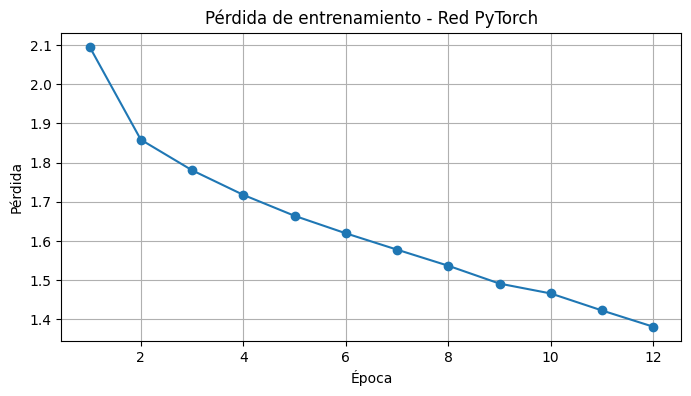

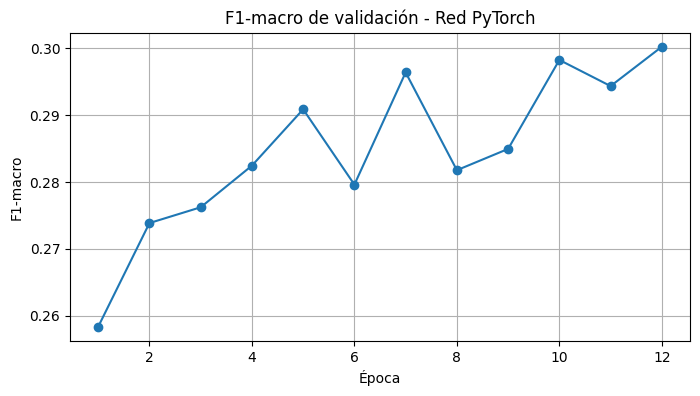

Gráficas guardadas correctamente


In [ ]:
# 61. GRAFICAS DEL ENTRENAMIENTO DE LA RED NEURONAL

import matplotlib.pyplot as plt

# Recuperamos los resultados de las 12 épocas.
epocas = tabla_historial_red["epoca"]
perdidas = tabla_historial_red["perdida_train"]
f1_val = tabla_historial_red["f1_macro_val"]

# Primera gráfica: evolución de la pérdida de entrenamiento.
plt.figure(figsize=(8, 4))

plt.plot(epocas, perdidas, marker="o")

plt.title("Pérdida de entrenamiento - Red PyTorch")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.grid(True)

plt.savefig(
    carpeta_resultados / "perdida_red_pytorch.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# Segunda gráfica: evolución del F1-macro en validación.
plt.figure(figsize=(8, 4))

plt.plot(epocas, f1_val, marker="o")

plt.title("F1-macro de validación - Red PyTorch")
plt.xlabel("Época")
plt.ylabel("F1-macro")
plt.grid(True)

plt.savefig(
    carpeta_resultados / "f1_red_pytorch.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Gráficas guardadas correctamente")

In [ ]:
# 62. CONTINUAR EL ENTRENAMIENTO HASTA 20 EPOCAS

# Continuamos desde la época 13 hasta la 20.
for epoca in range(13, 21):

    modelo_red.train()
    perdida_train = 0

    # Entrenamiento
    for X_lote, y_lote in loader_train:

        X_lote = X_lote.to(dispositivo)
        y_lote = y_lote.to(dispositivo)

        optimizador.zero_grad()

        salidas = modelo_red(X_lote)
        perdida = criterio(salidas, y_lote)

        perdida.backward()
        optimizador.step()

        perdida_train += perdida.item() * len(y_lote)

    perdida_train /= len(dataset_train)

    # Validación
    modelo_red.eval()

    predicciones_val = []
    etiquetas_val = []

    with torch.no_grad():

        for X_lote, y_lote in loader_val:

            X_lote = X_lote.to(dispositivo)

            salidas = modelo_red(X_lote)
            predicciones = torch.argmax(salidas, dim=1)

            predicciones_val.extend(predicciones.cpu().numpy())
            etiquetas_val.extend(y_lote.numpy())

    # Calculamos las métricas.
    accuracy = accuracy_score(etiquetas_val, predicciones_val)

    f1 = f1_score(
        etiquetas_val,
        predicciones_val,
        labels=range(39),
        average="macro",
        zero_division=0
    )

    # Añadimos los resultados al historial anterior.
    historial_red.append({
        "epoca": epoca,
        "perdida_train": perdida_train,
        "accuracy_val": accuracy,
        "f1_macro_val": f1
    })

    print(
        f"Época {epoca}/20 | "
        f"Pérdida: {perdida_train:.4f} | "
        f"Accuracy: {accuracy:.2%} | "
        f"F1-macro: {f1:.4f}"
    )

    # Solo guardamos el modelo si mejora el anterior.
    if f1 > mejor_f1_red:

        mejor_f1_red = f1
        mejor_epoca_red = epoca

        torch.save(
            modelo_red.state_dict(),
            ruta_mejor_red
        )

# Actualizamos el historial con las 20 épocas.
tabla_historial_red = pd.DataFrame(historial_red)

tabla_historial_red.to_csv(
    carpeta_resultados / "historial_red_pytorch.csv",
    index=False
)

# Recuperamos el mejor modelo de todas las épocas.
modelo_red.load_state_dict(
    torch.load(
        ruta_mejor_red,
        map_location=dispositivo,
        weights_only=True
    )
)

modelo_red.eval()

print("\nEntrenamiento ampliado finalizado")
print("Mejor época:", mejor_epoca_red)
print(f"Mejor F1-macro: {mejor_f1_red:.4f}")
print("Modelo e historial actualizados correctamente")

Época 13/20 | Pérdida: 1.3528 | Accuracy: 44.55% | F1-macro: 0.2905
Época 14/20 | Pérdida: 1.3186 | Accuracy: 45.07% | F1-macro: 0.2824
Época 15/20 | Pérdida: 1.2891 | Accuracy: 44.47% | F1-macro: 0.2805
Época 16/20 | Pérdida: 1.2526 | Accuracy: 44.30% | F1-macro: 0.2726
Época 17/20 | Pérdida: 1.2285 | Accuracy: 45.08% | F1-macro: 0.2968
Época 18/20 | Pérdida: 1.2022 | Accuracy: 44.54% | F1-macro: 0.2885
Época 19/20 | Pérdida: 1.1789 | Accuracy: 44.85% | F1-macro: 0.2992
Época 20/20 | Pérdida: 1.1463 | Accuracy: 44.47% | F1-macro: 0.2819

Entrenamiento ampliado finalizado
Mejor época: 12
Mejor F1-macro: 0.3002
Modelo e historial actualizados correctamente


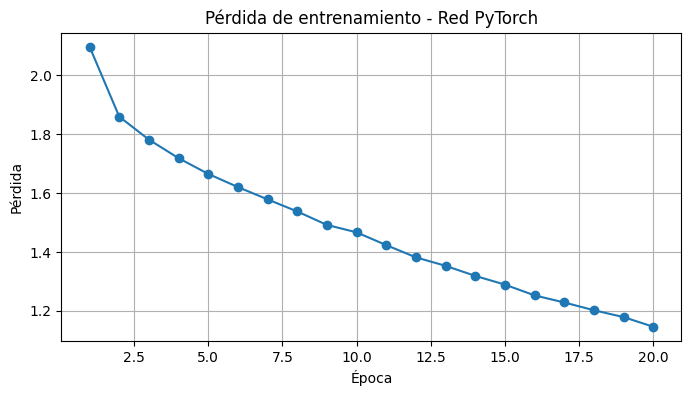

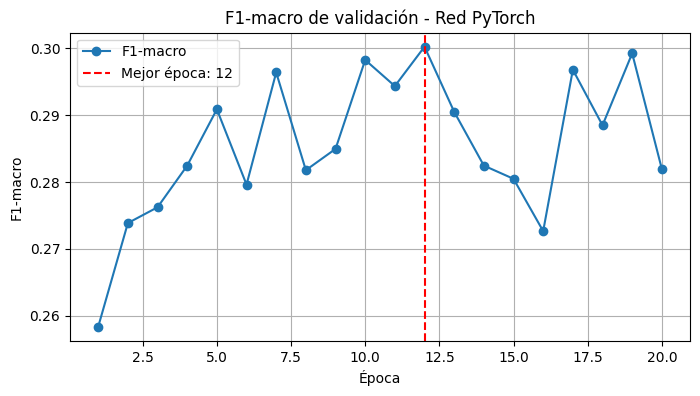

Gráficas actualizadas correctamente
Mejor época: 12
Mejor F1-macro: 0.3002


In [ ]:
# 63. ACTUALIZAR LAS GRAFICAS DE LA RED NEURONAL

import matplotlib.pyplot as plt

# Recuperamos los resultados de las 20 épocas.
epocas = tabla_historial_red["epoca"]
perdidas = tabla_historial_red["perdida_train"]
f1_val = tabla_historial_red["f1_macro_val"]

# Primera gráfica: pérdida de entrenamiento.
plt.figure(figsize=(8, 4))

plt.plot(epocas, perdidas, marker="o")

plt.title("Pérdida de entrenamiento - Red PyTorch")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.grid(True)

plt.savefig(
    carpeta_resultados / "perdida_red_pytorch.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# Segunda gráfica: F1-macro de validación.
plt.figure(figsize=(8, 4))

plt.plot(epocas, f1_val, marker="o", label="F1-macro")

# Marcamos la época que obtuvo el mejor resultado.
plt.axvline(
    mejor_epoca_red,
    color="red",
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_red}"
)

plt.title("F1-macro de validación - Red PyTorch")
plt.xlabel("Época")
plt.ylabel("F1-macro")
plt.legend()
plt.grid(True)

plt.savefig(
    carpeta_resultados / "f1_red_pytorch.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Gráficas actualizadas correctamente")
print("Mejor época:", mejor_epoca_red)
print(f"Mejor F1-macro: {mejor_f1_red:.4f}")

In [ ]:
# 64. EVALUAR LA RED NEURONAL POR CATEGORIAS

from sklearn.metrics import classification_report

# Utilizamos el mejor modelo que hemos guardado.
modelo_red.eval()

predicciones_red = []

# Realizamos las predicciones sobre validación.
with torch.no_grad():

    for X_lote, y_lote in loader_val:

        X_lote = X_lote.to(dispositivo)

        salidas = modelo_red(X_lote)

        predicciones = torch.argmax(salidas, dim=1)

        predicciones_red.extend(predicciones.cpu().numpy())

# Calculamos las métricas de cada categoría.
reporte_red = classification_report(
    y_val_num,
    predicciones_red,
    labels=range(39),
    target_names=[str(c) for c in codificador_etiquetas.classes_],
    output_dict=True,
    zero_division=0
)

# Convertimos los resultados en una tabla.
tabla_reporte_red = pd.DataFrame(reporte_red).T

# Guardamos la tabla.
tabla_reporte_red.to_csv(
    carpeta_resultados / "reporte_clases_red_pytorch.csv",
    encoding="utf-8"
)

# Mostramos las métricas generales.
print("RESULTADOS GENERALES DE LA RED NEURONAL")

print("Accuracy:",
      round(reporte_red["accuracy"], 4))

print("F1-macro:",
      round(reporte_red["macro avg"]["f1-score"], 4))

# Mostramos los resultados de las primeras categorías.
print("\nRESULTADOS POR CATEGORIA")
print(tabla_reporte_red.head(10).to_string())

print("\nReporte completo guardado correctamente")

RESULTADOS GENERALES DE LA RED NEURONAL
Accuracy: 0.4557
F1-macro: 0.3002

RESULTADOS POR CATEGORIA
                                      precision    recall  f1-score  support
agricultural biotechnology             0.000000  0.000000  0.000000      7.0
agriculture, forestry, and fisheries   0.392157  0.217391  0.279720     92.0
animal and dairy science               0.212121  0.259259  0.233333     27.0
arts                                   0.428571  0.307692  0.358209     39.0
basic medicine                         0.394191  0.496084  0.439306    383.0
biological sciences                    0.508497  0.561328  0.533608    693.0
chemical engineering                   0.000000  0.000000  0.000000     26.0
chemical sciences                      0.394541  0.501577  0.441667    317.0
civil engineering                      0.285714  0.190476  0.228571     63.0
clinical medicine                      0.516990  0.564987  0.539924    377.0

Reporte completo guardado correctamente


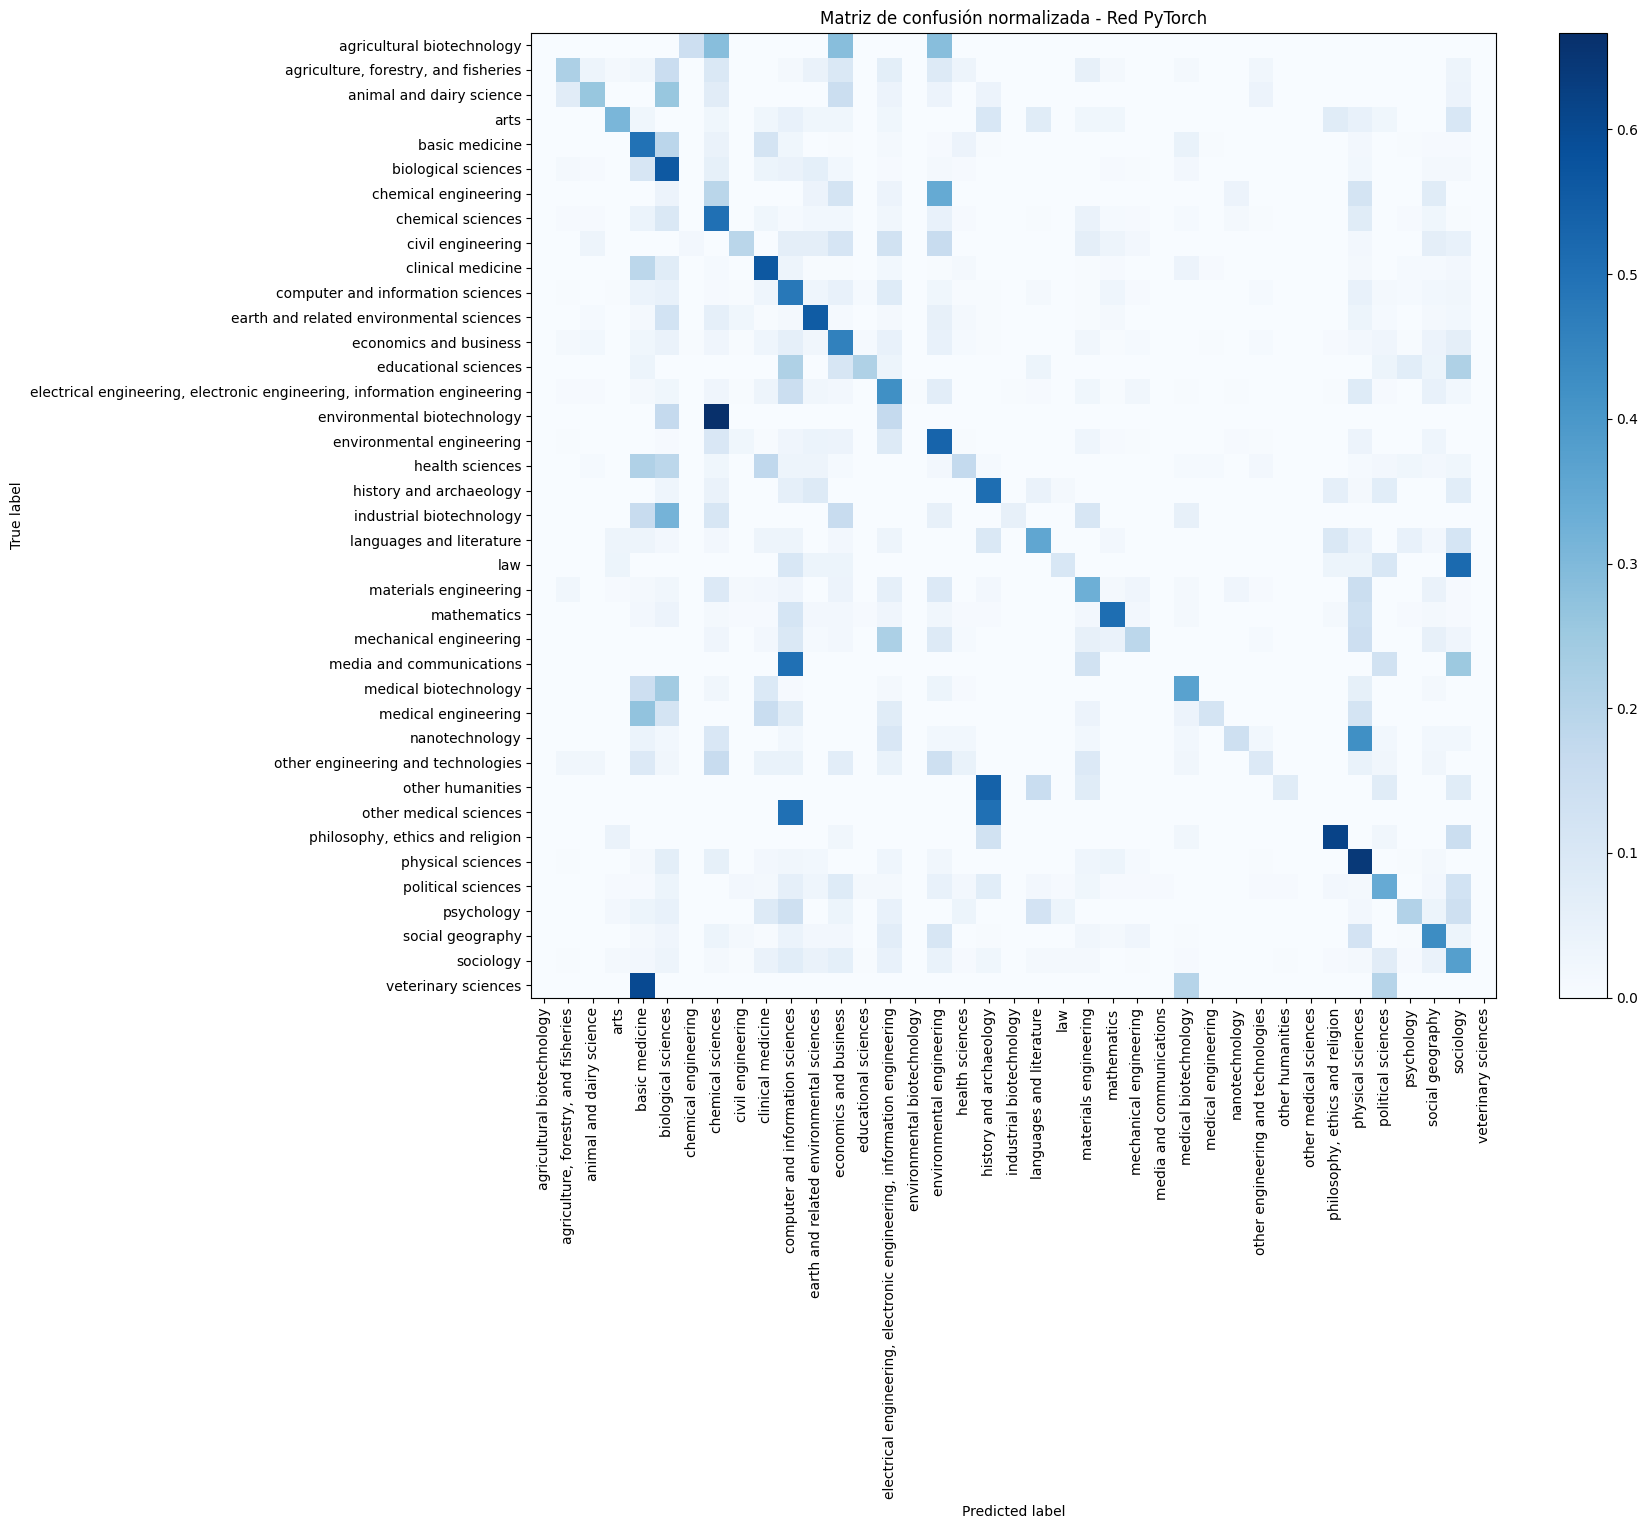

Matriz de confusión guardada correctamente
Total de proyectos evaluados: 6397
Predicciones correctas: 2915


In [ ]:
# 65. MATRIZ DE CONFUSION DE LA RED NEURONAL

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Obtenemos los nombres de las 39 categorías.
nombres_clases = codificador_etiquetas.classes_

# Calculamos la matriz de confusión.
matriz_confusion_red = confusion_matrix(
    y_val_num,
    predicciones_red,
    labels=range(39)
)

# Creamos una versión normalizada para comparar las categorías.
matriz_normalizada_red = confusion_matrix(
    y_val_num,
    predicciones_red,
    labels=range(39),
    normalize="true"
)

# Dibujamos la matriz normalizada.
fig, ax = plt.subplots(figsize=(18, 15))

grafica = ConfusionMatrixDisplay(
    confusion_matrix=matriz_normalizada_red,
    display_labels=nombres_clases
)

grafica.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format=".2f",
    include_values=False
)

plt.title("Matriz de confusión normalizada - Red PyTorch")
plt.tight_layout()

# Guardamos la gráfica.
plt.savefig(
    carpeta_resultados / "matriz_confusion_red_pytorch.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# Guardamos también la matriz con los valores originales.
tabla_confusion_red = pd.DataFrame(
    matriz_confusion_red,
    index=nombres_clases,
    columns=nombres_clases
)

tabla_confusion_red.to_csv(
    carpeta_resultados / "matriz_confusion_red_pytorch.csv"
)

print("Matriz de confusión guardada correctamente")
print("Total de proyectos evaluados:", matriz_confusion_red.sum())
print("Predicciones correctas:", np.trace(matriz_confusion_red))

In [ ]:
# 66. IDENTIFICAR LAS PRINCIPALES CONFUSIONES

# Creamos una lista para guardar los errores.
errores_red = []

# Recorremos las categorías reales.
for i, categoria_real in enumerate(nombres_clases):

    # Recorremos las categorías predichas.
    for j, categoria_predicha in enumerate(nombres_clases):

        # Solo estudiamos las predicciones incorrectas.
        if i != j and matriz_confusion_red[i, j] > 0:

            cantidad = matriz_confusion_red[i, j]
            total_real = matriz_confusion_red[i].sum()

            porcentaje = 100 * cantidad / total_real

            errores_red.append({
                "categoria_real": categoria_real,
                "categoria_predicha": categoria_predicha,
                "proyectos_confundidos": int(cantidad),
                "porcentaje_clase_real": round(porcentaje, 2)
            })

# Convertimos los errores en una tabla.
tabla_errores_red = pd.DataFrame(errores_red)

# Ordenamos de mayor a menor número de errores.
tabla_errores_red = tabla_errores_red.sort_values(
    "proyectos_confundidos",
    ascending=False
)

# Seleccionamos las 10 confusiones más frecuentes.
top_errores_red = tabla_errores_red.head(10)

# Mostramos los resultados.
print("PRINCIPALES CONFUSIONES DE LA RED NEURONAL")
print(top_errores_red.to_string(index=False))

# Guardamos la tabla completa para el informe.
tabla_errores_red.to_csv(
    carpeta_resultados / "errores_red_pytorch.csv",
    index=False,
    encoding="utf-8"
)

print("\nTabla de errores guardada correctamente")

PRINCIPALES CONFUSIONES DE LA RED NEURONAL
                                                         categoria_real                                                      categoria_predicha  proyectos_confundidos  porcentaje_clase_real
                                                    biological sciences                                                          basic medicine                     74                  10.68
                                                         basic medicine                                                     biological sciences                     72                  18.80
                                                      clinical medicine                                                          basic medicine                     70                  18.57
electrical engineering, electronic engineering, information engineering                                       computer and information sciences                     56                  14.66
       

In [ ]:
# 67. ANALIZAR LOS ERRORES SEGUN LA JERARQUIA EUROSCIVOC

# Relacionamos cada categoría de nivel 2 con su nivel 1.
mapa_nivel1 = (
    datos.drop_duplicates("nivel_2")
    .set_index("nivel_2")["nivel_1"]
    .to_dict()
)

# Recuperamos la tabla completa de errores.
tabla_jerarquia = tabla_errores_red.copy()

# Buscamos el nivel 1 de cada categoría real y predicha.
tabla_jerarquia["nivel1_real"] = (
    tabla_jerarquia["categoria_real"].map(mapa_nivel1)
)

tabla_jerarquia["nivel1_predicha"] = (
    tabla_jerarquia["categoria_predicha"].map(mapa_nivel1)
)

# Comprobamos que todas las categorías tienen un nivel 1.
assert tabla_jerarquia["nivel1_real"].notna().all()
assert tabla_jerarquia["nivel1_predicha"].notna().all()

# Comprobamos si ambas categorías pertenecen a la misma rama.
tabla_jerarquia["misma_rama"] = (
    tabla_jerarquia["nivel1_real"]
    == tabla_jerarquia["nivel1_predicha"]
)

# Contamos los errores dentro de la misma rama.
errores_misma_rama = tabla_jerarquia.loc[
    tabla_jerarquia["misma_rama"],
    "proyectos_confundidos"
].sum()

# Contamos todos los errores.
total_errores = tabla_jerarquia["proyectos_confundidos"].sum()

errores_distinta_rama = total_errores - errores_misma_rama

# Calculamos los porcentajes.
porcentaje_misma_rama = 100 * errores_misma_rama / total_errores

porcentaje_distinta_rama = 100 * errores_distinta_rama / total_errores

# Mostramos los resultados.
print("ANALISIS DE ERRORES SEGUN EUROSCIVOC")
print("Errores totales:", total_errores)
print("Errores en la misma rama:", errores_misma_rama)
print("Errores en distintas ramas:", errores_distinta_rama)

print(f"\nMisma rama: {porcentaje_misma_rama:.2f}%")
print(f"Distintas ramas: {porcentaje_distinta_rama:.2f}%")

# Mostramos las 10 principales confusiones.
print("\nPRINCIPALES CONFUSIONES:")
display(
    tabla_jerarquia[
        ["categoria_real", "categoria_predicha",
         "proyectos_confundidos", "misma_rama"]
    ].head(10)
)

# Guardamos los resultados.
tabla_jerarquia.to_csv(
    carpeta_resultados / "errores_jerarquia_pytorch.csv",
    index=False
)

print("\nResultados guardados correctamente")

ANALISIS DE ERRORES SEGUN EUROSCIVOC
Errores totales: 3482
Errores en la misma rama: 1271
Errores en distintas ramas: 2211

Misma rama: 36.50%
Distintas ramas: 63.50%

PRINCIPALES CONFUSIONES:


,categoria_real,categoria_predicha,proyectos_confundidos,misma_rama
62,biological sciences,basic medicine,74,False
44,basic medicine,biological sciences,72,False
124,clinical medicine,basic medicine,70,True
227,"electrical engineering, electronic engineering...",computer and information sciences,56,False
151,computer and information sciences,"electrical engineering, electronic engineering...",47,False
46,basic medicine,clinical medicine,44,True
67,biological sciences,earth and related environmental sciences,42,True
251,environmental engineering,chemical sciences,41,False
63,biological sciences,chemical sciences,38,True
448,physical sciences,biological sciences,35,True



Resultados guardados correctamente


In [ ]:
# 68. COPIA DE SEGURIDAD CON LA RED NEURONAL PYTORCH

import shutil
import joblib
from pathlib import Path
from google.colab import files

# Guardamos el codificador de las 39 categorías.
joblib.dump(
    codificador_etiquetas,
    carpeta_resultados / "codificador_etiquetas_pytorch.joblib"
)

# Comprobamos que los principales resultados existen.
archivos_importantes = [
    "mejor_red_pytorch.pth",
    "historial_red_pytorch.csv",
    "reporte_clases_red_pytorch.csv",
    "matriz_confusion_red_pytorch.png",
    "errores_jerarquia_pytorch.csv"
]

for nombre in archivos_importantes:
    ruta = carpeta_resultados / nombre
    print(nombre, ":", ruta.exists())

# Comprimimos toda la carpeta de resultados.
ruta_respaldo = shutil.make_archive(
    "/content/respaldo_resultados_con_red_pytorch",
    "zip",
    root_dir=str(carpeta_resultados)
)

# Comprobamos el tamaño de la copia.
tamano_mb = Path(ruta_respaldo).stat().st_size / (1024 * 1024)

total_archivos = sum(
    1 for archivo in carpeta_resultados.rglob("*")
    if archivo.is_file()
)

print("\nCopia de seguridad creada correctamente")
print("Archivo:", ruta_respaldo)
print(f"Tamaño: {tamano_mb:.2f} MB")
print("Archivos guardados:", total_archivos)

# Descargamos la copia al ordenador.
files.download(ruta_respaldo)

mejor_red_pytorch.pth : True
historial_red_pytorch.csv : True
reporte_clases_red_pytorch.csv : True
matriz_confusion_red_pytorch.png : True
errores_jerarquia_pytorch.csv : True

Copia de seguridad creada correctamente
Archivo: /content/respaldo_resultados_con_red_pytorch.zip
Tamaño: 144.14 MB
Archivos guardados: 43


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 69. PREPARAR LAS BIBLIOTECAS PARA EL FINE-TUNING

# Instalamos las herramientas necesarias.
%pip install -q datasets accelerate

import datasets
import accelerate

from transformers import AutoModelForSequenceClassification

# Comprobamos que las bibliotecas funcionan.
print("Datasets instalado correctamente")
print("Versión:", datasets.__version__)

print("\nAccelerate instalado correctamente")
print("Versión:", accelerate.__version__)

# Comprobamos que seguimos teniendo la GPU.
print("\nGPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Modelo:", torch.cuda.get_device_name(0))

# Comprobamos los datos que utilizaremos.
print("\nProyectos de entrenamiento:", len(datos_train))
print("Proyectos de validación:", len(datos_val))
print("Categorías:", len(codificador_etiquetas.classes_))

Datasets instalado correctamente
Versión: 4.8.5

Accelerate instalado correctamente
Versión: 1.15.0

GPU disponible: True
Modelo: Tesla T4

Proyectos de entrenamiento: 19188
Proyectos de validación: 6397
Categorías: 39


In [ ]:
# 70. PREPARAR LOS DATOS PARA EL FINE-TUNING

from datasets import Dataset, DatasetDict

# Creamos el conjunto de entrenamiento.
dataset_train_bert = Dataset.from_dict({
    "text": datos_train["summary"].tolist(),
    "label": y_train_num.tolist()
})

# Creamos el conjunto de validación.
dataset_val_bert = Dataset.from_dict({
    "text": datos_val["summary"].tolist(),
    "label": y_val_num.tolist()
})

# Agrupamos ambos conjuntos.
datasets_bert = DatasetDict({
    "train": dataset_train_bert,
    "validation": dataset_val_bert
})

# Comprobamos los resultados.
print("Conjuntos preparados correctamente")
print(datasets_bert)

print("\nPrimer proyecto de entrenamiento:")
print("Texto:", dataset_train_bert[0]["text"][:200])
print("Categoría numérica:", dataset_train_bert[0]["label"])

# Comprobamos que los tamaños coinciden.
print("\nProyectos de entrenamiento:", len(dataset_train_bert))
print("Proyectos de validación:", len(dataset_val_bert))

Conjuntos preparados correctamente
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 19188
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 6397
    })
})

Primer proyecto de entrenamiento:
Texto: The current Ebola Virus Disease (EVD) outbreak has caused more than 5000 deaths within a few months in West Africa (Guinea, Sierra Leone and Liberia being the most severely affected countries), includ
Categoría numérica: 4

Proyectos de entrenamiento: 19188
Proyectos de validación: 6397


In [ ]:
# 71. TOKENIZAR LOS RESUMENES PARA EL FINE-TUNING

# Creamos una función para tokenizar los textos.
def tokenizar_resumenes(ejemplos):

    return tokenizador(
        ejemplos["text"],
        truncation=True,
        max_length=512
    )


# Tokenizamos entrenamiento y validación.
print("Tokenizando los resúmenes...")

datasets_bert_tokenizados = datasets_bert.map(
    tokenizar_resumenes,
    batched=True
)

# Comprobamos los resultados.
print("\nTokenización completada correctamente")

print(datasets_bert_tokenizados)

# Comprobamos el primer proyecto.
primer_proyecto = datasets_bert_tokenizados["train"][0]

print("\nTokens del primer proyecto:",
      len(primer_proyecto["input_ids"]))

print("Categoría numérica:",
      primer_proyecto["label"])

# Comprobamos que conservamos todos los proyectos.
print("\nEntrenamiento:",
      len(datasets_bert_tokenizados["train"]))

print("Validación:",
      len(datasets_bert_tokenizados["validation"]))

Tokenizando los resúmenes...


Map:   0%|          | 0/19188 [00:00<?, ? examples/s]

Map:   0%|          | 0/6397 [00:00<?, ? examples/s]


Tokenización completada correctamente
DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 19188
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 6397
    })
})

Tokens del primer proyecto: 349
Categoría numérica: 4

Entrenamiento: 19188
Validación: 6397


In [ ]:
# 72. PREPARAR LOS DATOS DEFINITIVOS PARA DISTILBERT

from transformers import DataCollatorWithPadding

# Conservamos únicamente las columnas necesarias.
datasets_bert_final = datasets_bert_tokenizados.remove_columns(
    ["text", "token_type_ids"]
)

# Preparamos el relleno automático de los textos.
collator_bert = DataCollatorWithPadding(
    tokenizer=tokenizador
)

# Comprobamos las columnas disponibles.
print("Datos preparados correctamente")
print(datasets_bert_final)

# Probamos el relleno con dos proyectos.
lote_ejemplo = collator_bert([
    datasets_bert_final["train"][0],
    datasets_bert_final["train"][1]
])

# Mostramos las dimensiones.
print("\nDimensiones del lote de prueba:")
print("input_ids:", lote_ejemplo["input_ids"].shape)
print("attention_mask:", lote_ejemplo["attention_mask"].shape)
print("labels:", lote_ejemplo["labels"].shape)

print("\nPreparación final completada")

Datos preparados correctamente
DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 19188
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 6397
    })
})

Dimensiones del lote de prueba:
input_ids: torch.Size([2, 369])
attention_mask: torch.Size([2, 369])
labels: torch.Size([2])

Preparación final completada


In [ ]:
# 73. CARGAR DISTILBERT PARA CLASIFICACION

from transformers import AutoModelForSequenceClassification, set_seed

# Fijamos la semilla para facilitar la reproducción.
set_seed(42)

# Indicamos el número de categorías.
num_categorias = len(codificador_etiquetas.classes_)

# Cargamos DistilBERT con una capa de clasificación.
modelo_finetuning = AutoModelForSequenceClassification.from_pretrained(
    nombre_transformer,
    num_labels=num_categorias
)

# Enviamos el modelo a la GPU.
modelo_finetuning = modelo_finetuning.to(dispositivo)

# Comprobamos que funciona con dos proyectos.
modelo_finetuning.eval()

with torch.no_grad():

    # Utilizamos el lote preparado en el paso 72.
    entradas_ejemplo = {
        "input_ids": lote_ejemplo["input_ids"].to(dispositivo),
        "attention_mask": lote_ejemplo["attention_mask"].to(dispositivo)
    }

    salidas_ejemplo = modelo_finetuning(**entradas_ejemplo)

# Mostramos los resultados.
print("DistilBERT preparado para fine-tuning")
print("Dispositivo:", dispositivo)
print("Número de categorías:", modelo_finetuning.config.num_labels)
print("Dimensiones de salida:", salidas_ejemplo.logits.shape)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT preparado para fine-tuning
Dispositivo: cuda
Número de categorías: 39
Dimensiones de salida: torch.Size([2, 39])


In [ ]:
# 74. CONFIGURAR EL FINE-TUNING DE DISTILBERT

from transformers import TrainingArguments
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# Función para evaluar el modelo durante el entrenamiento.
def calcular_metricas_bert(predicciones):

    # Obtenemos las puntuaciones y las categorías reales.
    logits = predicciones.predictions
    etiquetas = predicciones.label_ids

    # Elegimos la categoría con mayor puntuación.
    categorias_predichas = np.argmax(logits, axis=1)

    # Calculamos las métricas.
    accuracy = accuracy_score(etiquetas, categorias_predichas)

    f1 = f1_score(
        etiquetas,
        categorias_predichas,
        labels=range(39),
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "f1_macro": f1
    }


# Configuramos el entrenamiento.
argumentos_bert = TrainingArguments(
    output_dir="/content/resultados/finetuning_distilbert",

    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,

    gradient_accumulation_steps=2,
    learning_rate=2e-5,
    weight_decay=0.01,

    # Utilizamos precisión mixta para ahorrar memoria.
    fp16=True,

    # Evaluamos y guardamos al terminar cada época.
    eval_strategy="epoch",
    save_strategy="epoch",

    # Conservamos la mejor versión del modelo.
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,

    # Limitamos las copias guardadas.
    save_total_limit=2,

    # Registramos el progreso del entrenamiento.
    logging_steps=100,
    report_to="none",

    # Fijamos la semilla aleatoria.
    seed=42
)

# Comprobamos la configuración.
print("Fine-tuning configurado correctamente")
print("Épocas:", argumentos_bert.num_train_epochs)
print("Lote de entrenamiento:", argumentos_bert.per_device_train_batch_size)
print("Lote de validación:", argumentos_bert.per_device_eval_batch_size)
print("Learning rate:", argumentos_bert.learning_rate)
print("Precisión mixta:", argumentos_bert.fp16)
print("Métrica principal:", argumentos_bert.metric_for_best_model)

Fine-tuning configurado correctamente
Épocas: 3
Lote de entrenamiento: 8
Lote de validación: 16
Learning rate: 2e-05
Precisión mixta: True
Métrica principal: f1_macro


In [ ]:
# 75. CREAR EL ENTRENADOR DE DISTILBERT

from transformers import Trainer

# Creamos el entrenador con los datos y parámetros preparados.
entrenador_bert = Trainer(
    model=modelo_finetuning,
    args=argumentos_bert,
    train_dataset=datasets_bert_final["train"],
    eval_dataset=datasets_bert_final["validation"],
    processing_class=tokenizador,
    data_collator=collator_bert,
    compute_metrics=calcular_metricas_bert
)

# Comprobamos que todo está preparado.
print("Entrenador de DistilBERT creado correctamente")

print("Modelo:", nombre_transformer)
print("Proyectos de entrenamiento:",
      len(entrenador_bert.train_dataset))

print("Proyectos de validación:",
      len(entrenador_bert.eval_dataset))

print("Épocas:",
      entrenador_bert.args.num_train_epochs)

print("Métrica principal:",
      entrenador_bert.args.metric_for_best_model)

print("GPU disponible:", torch.cuda.is_available())

Entrenador de DistilBERT creado correctamente
Modelo: distilbert-base-uncased
Proyectos de entrenamiento: 19188
Proyectos de validación: 6397
Épocas: 3
Métrica principal: f1_macro
GPU disponible: True


In [ ]:
# 76. ENTRENAR DISTILBERT CON FINE-TUNING

# Comenzamos el entrenamiento.
print("Comenzando fine-tuning de DistilBERT...")

resultado_entrenamiento_bert = entrenador_bert.train()

# Guardamos el mejor modelo al finalizar.
ruta_finetuning = carpeta_resultados / "modelo_distilbert_finetuning"

entrenador_bert.save_model(str(ruta_finetuning))

# Mostramos los resultados.
print("\nFine-tuning finalizado correctamente")

print("Épocas completadas:",
      entrenador_bert.state.epoch)

print("Mejor F1-macro de validación:",
      entrenador_bert.state.best_metric)

print("Mejor checkpoint:",
      entrenador_bert.state.best_model_checkpoint)

print("Modelo guardado en:", ruta_finetuning)

Comenzando fine-tuning de DistilBERT...


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,3.635126,1.770234,0.514773,0.263202
2,3.205415,1.599027,0.556355,0.307796
3,2.888605,1.567039,0.565578,0.325595


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Fine-tuning finalizado correctamente
Épocas completadas: 3.0
Mejor F1-macro de validación: 0.3255946331103884
Mejor checkpoint: /content/resultados/finetuning_distilbert/checkpoint-3600
Modelo guardado en: /content/resultados/modelo_distilbert_finetuning


In [ ]:
# 77. GUARDAR LOS RESULTADOS DEL FINE-TUNING

# Evaluamos el mejor modelo con los datos de validación.
metricas_finetuning = entrenador_bert.evaluate()

# Creamos una tabla con los resultados.
tabla_finetuning = pd.DataFrame([{
    "modelo": "DistilBERT fine-tuning",
    "conjunto": "validacion",
    "epocas": 3,
    "accuracy": metricas_finetuning["eval_accuracy"],
    "f1_macro": metricas_finetuning["eval_f1_macro"],
    "perdida_val": metricas_finetuning["eval_loss"]
}])

# Guardamos las métricas.
tabla_finetuning.to_csv(
    carpeta_resultados / "resultados_finetuning_distilbert.csv",
    index=False
)

# Guardamos también el historial del entrenamiento.
historial_finetuning = pd.DataFrame(
    entrenador_bert.state.log_history
)

historial_finetuning.to_csv(
    carpeta_resultados / "historial_finetuning_distilbert.csv",
    index=False
)

# Mostramos los resultados.
print("RESULTADOS DEL FINE-TUNING")
print(tabla_finetuning.to_string(index=False))

print("\nMétricas guardadas correctamente")
print("Historial del entrenamiento guardado correctamente")

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
2.888605,1.567039,3,0.565578,0.325595


RESULTADOS DEL FINE-TUNING
                modelo   conjunto  epocas  accuracy  f1_macro  perdida_val
DistilBERT fine-tuning validacion       3  0.565578  0.325595     1.567039

Métricas guardadas correctamente
Historial del entrenamiento guardado correctamente


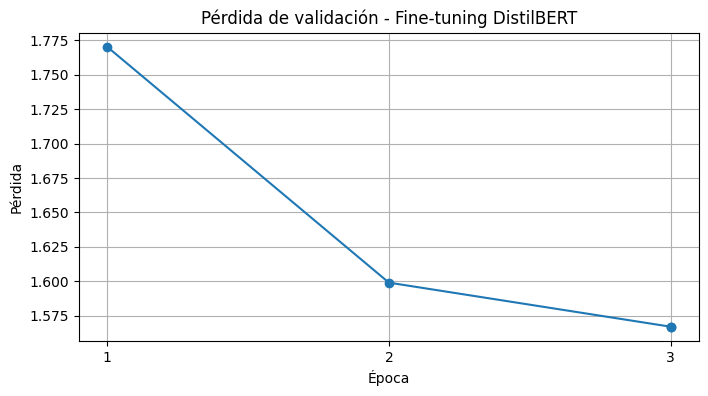

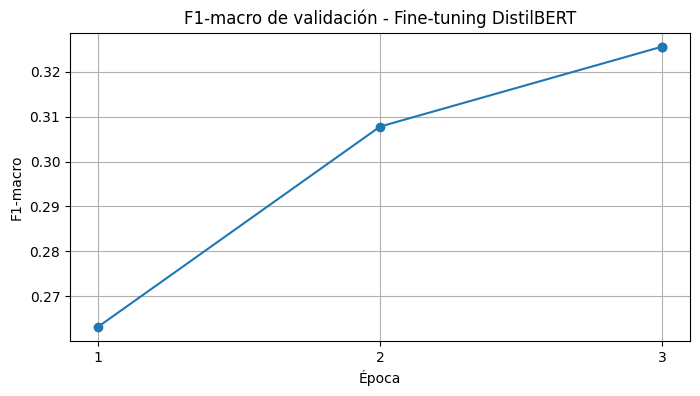

Gráficas del fine-tuning guardadas correctamente


In [ ]:
# 78. GRAFICAS DEL FINE-TUNING DE DISTILBERT

import matplotlib.pyplot as plt

# Recuperamos los resultados de validación de cada época.
datos_graficas_bert = historial_finetuning.dropna(
    subset=["eval_loss", "eval_f1_macro"]
)

epocas_bert = datos_graficas_bert["epoch"]
perdida_bert = datos_graficas_bert["eval_loss"]
f1_bert = datos_graficas_bert["eval_f1_macro"]


# Primera gráfica: pérdida de validación.
plt.figure(figsize=(8, 4))

plt.plot(epocas_bert, perdida_bert, marker="o")

plt.title("Pérdida de validación - Fine-tuning DistilBERT")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.xticks([1, 2, 3])
plt.grid(True)

plt.savefig(
    carpeta_resultados / "perdida_finetuning_distilbert.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# Segunda gráfica: evolución del F1-macro.
plt.figure(figsize=(8, 4))

plt.plot(epocas_bert, f1_bert, marker="o")

plt.title("F1-macro de validación - Fine-tuning DistilBERT")
plt.xlabel("Época")
plt.ylabel("F1-macro")
plt.xticks([1, 2, 3])
plt.grid(True)

plt.savefig(
    carpeta_resultados / "f1_finetuning_distilbert.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Gráficas del fine-tuning guardadas correctamente")

In [ ]:
# 79. EVALUAR EL FINE-TUNING POR CATEGORIAS

from sklearn.metrics import classification_report

# Obtenemos las predicciones del mejor modelo.
print("Evaluando DistilBERT en validación...")

resultado_predicciones_bert = entrenador_bert.predict(
    datasets_bert_final["validation"]
)

# Recuperamos las categorías reales.
etiquetas_reales_bert = resultado_predicciones_bert.label_ids

# Elegimos la categoría predicha por el modelo.
predicciones_finetuning = np.argmax(
    resultado_predicciones_bert.predictions,
    axis=1
)

# Calculamos las métricas de las 39 categorías.
reporte_finetuning = classification_report(
    etiquetas_reales_bert,
    predicciones_finetuning,
    labels=range(39),
    target_names=[str(c) for c in codificador_etiquetas.classes_],
    output_dict=True,
    zero_division=0
)

# Convertimos el informe en una tabla.
tabla_reporte_finetuning = pd.DataFrame(
    reporte_finetuning
).T

# Guardamos el informe completo.
tabla_reporte_finetuning.to_csv(
    carpeta_resultados / "reporte_clases_finetuning.csv",
    encoding="utf-8"
)

# Mostramos los resultados generales.
print("\nRESULTADOS GENERALES DEL FINE-TUNING")

print("Accuracy:",
      round(reporte_finetuning["accuracy"], 4))

print("F1-macro:",
      round(reporte_finetuning["macro avg"]["f1-score"], 4))

# Mostramos las primeras 10 categorías.
print("\nRESULTADOS POR CATEGORIA")
print(tabla_reporte_finetuning.head(10).to_string())

print("\nReporte completo guardado correctamente")

Evaluando DistilBERT en validación...



RESULTADOS GENERALES DEL FINE-TUNING
Accuracy: 0.5656
F1-macro: 0.3256

RESULTADOS POR CATEGORIA
                                      precision    recall  f1-score  support
agricultural biotechnology             0.000000  0.000000  0.000000      7.0
agriculture, forestry, and fisheries   0.365854  0.489130  0.418605     92.0
animal and dairy science               0.000000  0.000000  0.000000     27.0
arts                                   0.666667  0.051282  0.095238     39.0
basic medicine                         0.568445  0.639687  0.601966    383.0
biological sciences                    0.603922  0.666667  0.633745    693.0
chemical engineering                   0.000000  0.000000  0.000000     26.0
chemical sciences                      0.538721  0.504732  0.521173    317.0
civil engineering                      0.375000  0.047619  0.084507     63.0
clinical medicine                      0.579741  0.713528  0.639715    377.0

Reporte completo guardado correctamente


In [ ]:
# 80. COMPARAR LOS RESULTADOS POR CATEGORIA

# Recuperamos los nombres de las 39 categorías.
categorias = [str(c) for c in codificador_etiquetas.classes_]

# Creamos una tabla con los resultados de los dos modelos.
comparacion_clases = pd.DataFrame({
    "categoria": categorias,
    "proyectos": tabla_reporte_red.loc[categorias, "support"].astype(int).values,
    "f1_red_pytorch": tabla_reporte_red.loc[categorias, "f1-score"].values,
    "f1_finetuning": tabla_reporte_finetuning.loc[categorias, "f1-score"].values
})

# Calculamos la diferencia entre los F1 de ambos modelos.
comparacion_clases["diferencia_f1"] = (
    comparacion_clases["f1_finetuning"]
    - comparacion_clases["f1_red_pytorch"]
)

# Ordenamos las categorías según la mejora obtenida.
comparacion_clases = comparacion_clases.sort_values(
    "diferencia_f1",
    ascending=False
)

# Contamos en cuántas categorías mejora cada modelo.
mejor_finetuning = (comparacion_clases["diferencia_f1"] > 0).sum()
mejor_pytorch = (comparacion_clases["diferencia_f1"] < 0).sum()
empates = (comparacion_clases["diferencia_f1"] == 0).sum()

print("COMPARACION POR CATEGORIAS")
print("Categorías donde mejora DistilBERT:", mejor_finetuning)
print("Categorías donde mejora PyTorch:", mejor_pytorch)
print("Categorías empatadas:", empates)

# Mostramos las 10 mayores mejoras de DistilBERT.
print("\nMAYORES MEJORAS CON FINE-TUNING")
print(comparacion_clases.head(10).to_string(index=False))

# Mostramos las 10 categorías donde menos mejora.
print("\nCATEGORIAS DONDE DISTILBERT FUNCIONA PEOR O MEJORA MENOS")
print(comparacion_clases.tail(10).to_string(index=False))

# Guardamos la comparación completa.
comparacion_clases.to_csv(
    carpeta_resultados / "comparacion_clases_pytorch_finetuning.csv",
    index=False,
    encoding="utf-8"
)

print("\nComparación guardada correctamente")

COMPARACION POR CATEGORIAS
Categorías donde mejora DistilBERT: 23
Categorías donde mejora PyTorch: 10
Categorías empatadas: 6

MAYORES MEJORAS CON FINE-TUNING
                                                              categoria  proyectos  f1_red_pytorch  f1_finetuning  diferencia_f1
                                                  medical biotechnology        141        0.404669       0.681159       0.276490
                                                        health sciences        123        0.214286       0.440000       0.225714
                                                       social geography        229        0.425163       0.625498       0.200335
                                                         basic medicine        383        0.439306       0.601966       0.162659
electrical engineering, electronic engineering, information engineering        382        0.406566       0.565934       0.159368
                                                  materials enginee

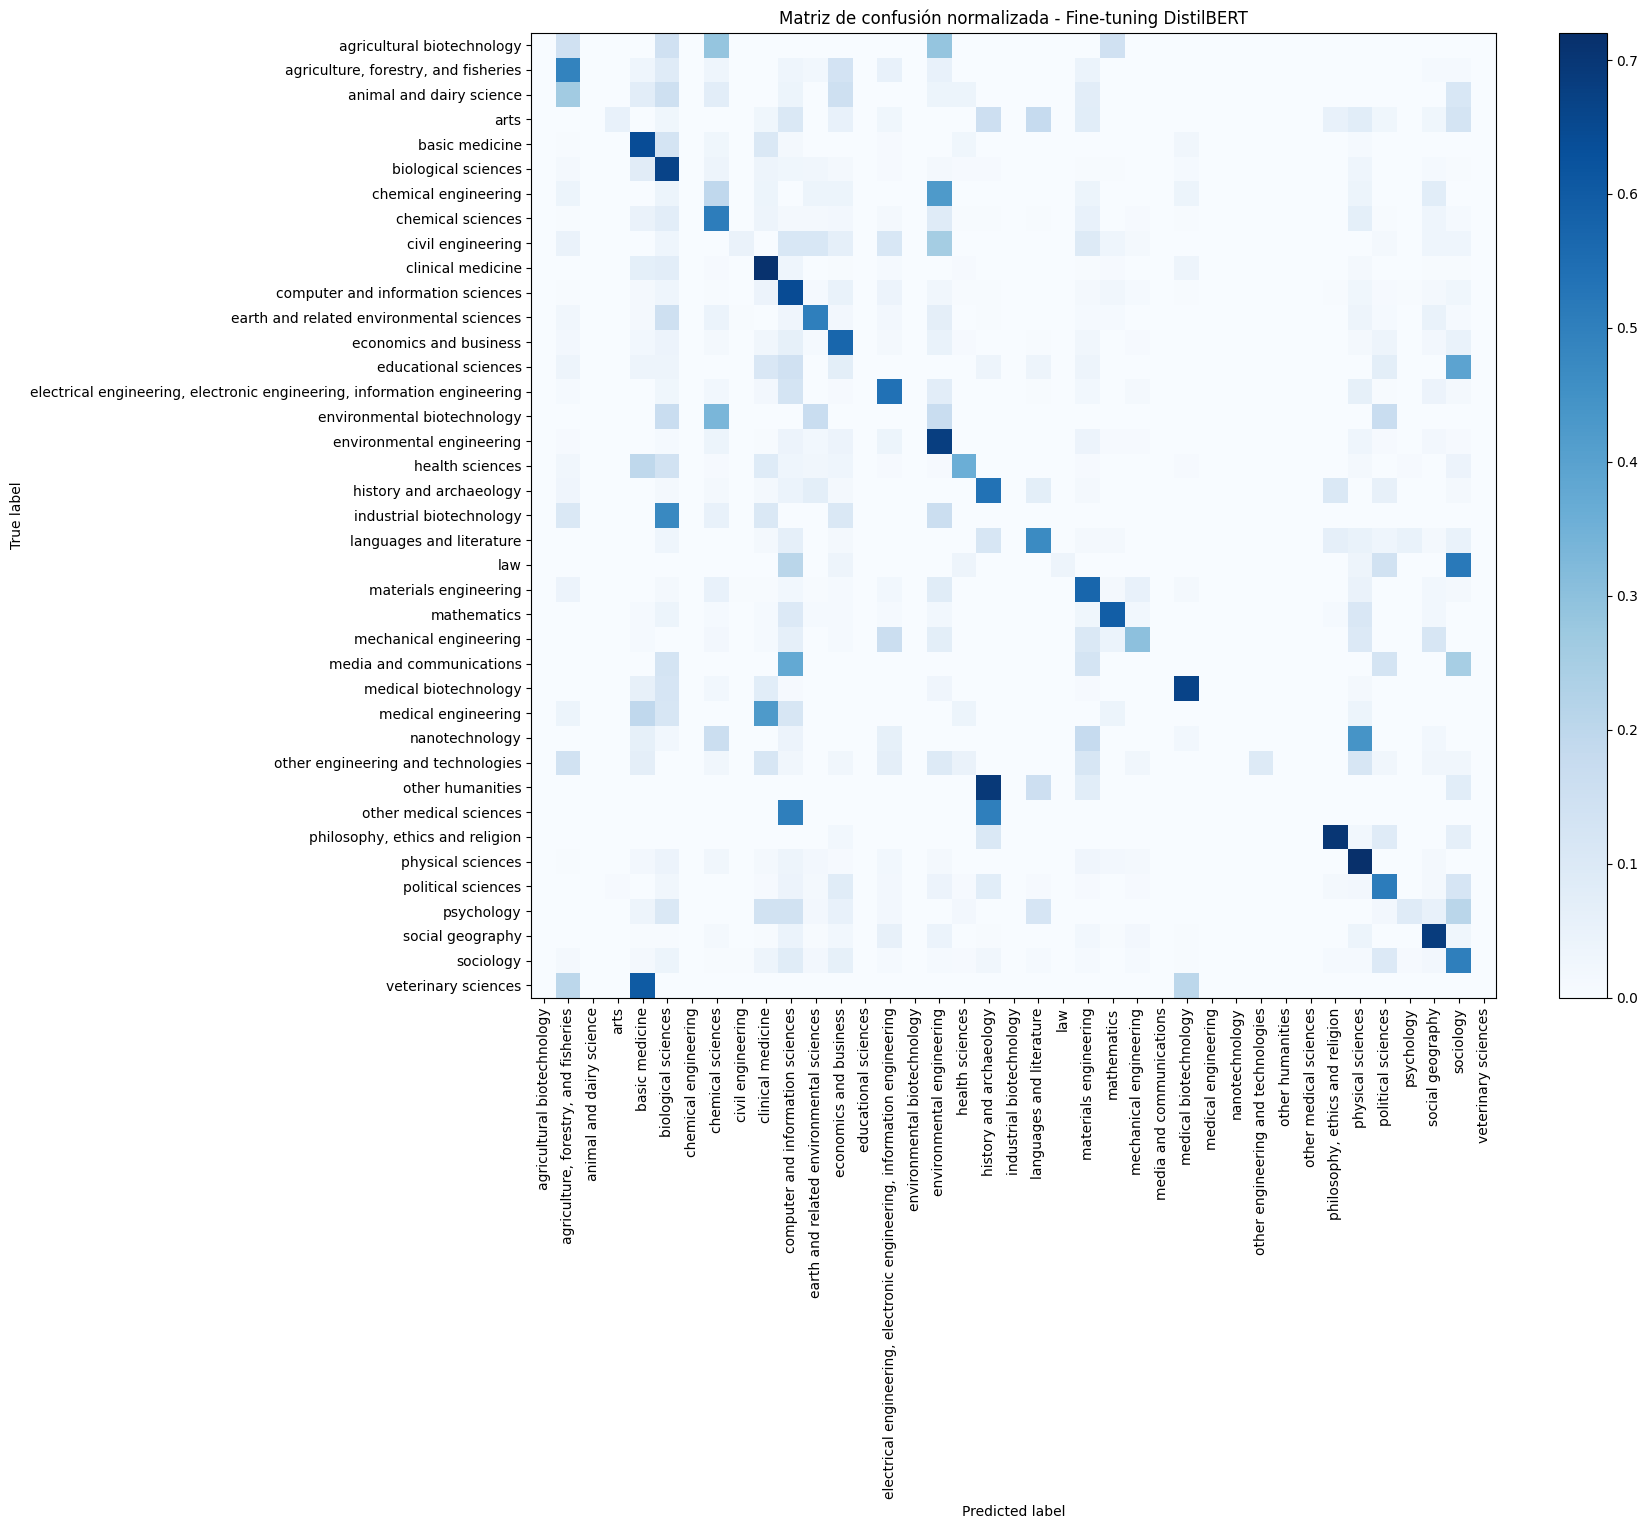

Matriz de confusión guardada correctamente
Total de proyectos evaluados: 6397
Predicciones correctas: 3618
Predicciones incorrectas: 2779


In [ ]:
# 81. MATRIZ DE CONFUSION DEL FINE-TUNING

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Recuperamos los nombres de las 39 categorías.
nombres_clases = codificador_etiquetas.classes_

# Calculamos la matriz de confusión.
matriz_confusion_finetuning = confusion_matrix(
    etiquetas_reales_bert,
    predicciones_finetuning,
    labels=range(39)
)

# Calculamos también la matriz normalizada.
matriz_normalizada_finetuning = confusion_matrix(
    etiquetas_reales_bert,
    predicciones_finetuning,
    labels=range(39),
    normalize="true"
)

# Dibujamos la matriz de confusión normalizada.
fig, ax = plt.subplots(figsize=(18, 15))

grafica = ConfusionMatrixDisplay(
    confusion_matrix=matriz_normalizada_finetuning,
    display_labels=nombres_clases
)

grafica.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format=".2f",
    include_values=False
)

plt.title("Matriz de confusión normalizada - Fine-tuning DistilBERT")
plt.tight_layout()

# Guardamos la gráfica.
plt.savefig(
    carpeta_resultados / "matriz_confusion_finetuning.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# Guardamos la matriz con los valores originales.
tabla_confusion_finetuning = pd.DataFrame(
    matriz_confusion_finetuning,
    index=nombres_clases,
    columns=nombres_clases
)

tabla_confusion_finetuning.to_csv(
    carpeta_resultados / "matriz_confusion_finetuning.csv"
)

# Comprobamos los resultados.
print("Matriz de confusión guardada correctamente")
print("Total de proyectos evaluados:", matriz_confusion_finetuning.sum())
print("Predicciones correctas:", np.trace(matriz_confusion_finetuning))
print("Predicciones incorrectas:",
      matriz_confusion_finetuning.sum() - np.trace(matriz_confusion_finetuning))

In [ ]:
# 82. IDENTIFICAR LAS PRINCIPALES CONFUSIONES DE DISTILBERT

# Creamos una lista para guardar los errores.
errores_finetuning = []

# Recorremos las categorías reales.
for i, categoria_real in enumerate(nombres_clases):

    # Recorremos las categorías predichas.
    for j, categoria_predicha in enumerate(nombres_clases):

        # Solo estudiamos las predicciones incorrectas.
        if i != j and matriz_confusion_finetuning[i, j] > 0:

            cantidad = matriz_confusion_finetuning[i, j]
            total_real = matriz_confusion_finetuning[i].sum()

            porcentaje = 100 * cantidad / total_real

            errores_finetuning.append({
                "categoria_real": categoria_real,
                "categoria_predicha": categoria_predicha,
                "proyectos_confundidos": int(cantidad),
                "porcentaje_clase_real": round(porcentaje, 2)
            })

# Convertimos los errores en una tabla.
tabla_errores_finetuning = pd.DataFrame(errores_finetuning)

# Ordenamos de mayor a menor número de errores.
tabla_errores_finetuning = tabla_errores_finetuning.sort_values(
    "proyectos_confundidos",
    ascending=False
)

# Seleccionamos las 10 principales confusiones.
top_errores_finetuning = tabla_errores_finetuning.head(10)

# Mostramos los resultados.
print("PRINCIPALES CONFUSIONES DE DISTILBERT")
print(top_errores_finetuning.to_string(index=False))

# Comprobamos el número total de errores.
print("\nTotal de errores:",
      tabla_errores_finetuning["proyectos_confundidos"].sum())

# Guardamos la tabla completa.
tabla_errores_finetuning.to_csv(
    carpeta_resultados / "errores_finetuning_distilbert.csv",
    index=False,
    encoding="utf-8"
)

print("\nTabla de errores guardada correctamente")

PRINCIPALES CONFUSIONES DE DISTILBERT
                                                         categoria_real                categoria_predicha  proyectos_confundidos  porcentaje_clase_real
                                                    biological sciences                    basic medicine                     56                   8.08
                                                         basic medicine               biological sciences                     49                  12.79
electrical engineering, electronic engineering, information engineering computer and information sciences                     48                  12.57
                                                         basic medicine                 clinical medicine                     40                  10.44
                               earth and related environmental sciences               biological sciences                     30                  14.71
electrical engineering, electronic engineering, in

In [ ]:
# 83. ANALIZAR LOS ERRORES DE DISTILBERT SEGUN EUROSCIVOC

# Relacionamos cada categoría de nivel 2 con su nivel 1.
mapa_nivel1 = (
    datos.drop_duplicates("nivel_2")
    .set_index("nivel_2")["nivel_1"]
    .to_dict()
)

# Recuperamos la tabla de errores de DistilBERT.
tabla_jerarquia_finetuning = tabla_errores_finetuning.copy()

# Obtenemos la categoría de nivel 1 real y predicha.
tabla_jerarquia_finetuning["nivel1_real"] = (
    tabla_jerarquia_finetuning["categoria_real"].map(mapa_nivel1)
)

tabla_jerarquia_finetuning["nivel1_predicha"] = (
    tabla_jerarquia_finetuning["categoria_predicha"].map(mapa_nivel1)
)

# Comprobamos que todas las categorías tienen un nivel 1.
assert tabla_jerarquia_finetuning["nivel1_real"].notna().all()
assert tabla_jerarquia_finetuning["nivel1_predicha"].notna().all()

# Comprobamos si las dos categorías pertenecen a la misma rama.
tabla_jerarquia_finetuning["misma_rama"] = (
    tabla_jerarquia_finetuning["nivel1_real"]
    == tabla_jerarquia_finetuning["nivel1_predicha"]
)

# Contamos los errores de la misma rama.
errores_misma_rama_bert = tabla_jerarquia_finetuning.loc[
    tabla_jerarquia_finetuning["misma_rama"],
    "proyectos_confundidos"
].sum()

# Contamos todos los errores.
total_errores_bert = tabla_jerarquia_finetuning[
    "proyectos_confundidos"
].sum()

# Calculamos los errores entre ramas diferentes.
errores_distinta_rama_bert = total_errores_bert - errores_misma_rama_bert

# Calculamos los porcentajes.
porcentaje_misma_rama_bert = (
    100 * errores_misma_rama_bert / total_errores_bert
)

porcentaje_distinta_rama_bert = (
    100 * errores_distinta_rama_bert / total_errores_bert
)

# Mostramos los resultados.
print("ANALISIS DE ERRORES DE DISTILBERT SEGUN EUROSCIVOC")

print("Errores totales:", total_errores_bert)
print("Errores en la misma rama:", errores_misma_rama_bert)
print("Errores en distintas ramas:", errores_distinta_rama_bert)

print(f"\nMisma rama: {porcentaje_misma_rama_bert:.2f}%")
print(f"Distintas ramas: {porcentaje_distinta_rama_bert:.2f}%")

# Mostramos las 10 principales confusiones.
print("\nPRINCIPALES CONFUSIONES:")

display(
    tabla_jerarquia_finetuning[
        ["categoria_real", "categoria_predicha",
         "proyectos_confundidos", "misma_rama"]
    ].head(10)
)

# Guardamos los resultados.
tabla_jerarquia_finetuning.to_csv(
    carpeta_resultados / "errores_jerarquia_finetuning.csv",
    index=False
)

print("\nResultados guardados correctamente")

ANALISIS DE ERRORES DE DISTILBERT SEGUN EUROSCIVOC
Errores totales: 2779
Errores en la misma rama: 1003
Errores en distintas ramas: 1776

Misma rama: 36.09%
Distintas ramas: 63.91%

PRINCIPALES CONFUSIONES:


,categoria_real,categoria_predicha,proyectos_confundidos,misma_rama
54,biological sciences,basic medicine,56,False
40,basic medicine,biological sciences,49,False
209,"electrical engineering, electronic engineering...",computer and information sciences,48,False
42,basic medicine,clinical medicine,40,True
158,earth and related environmental sciences,biological sciences,30,True
212,"electrical engineering, electronic engineering...",environmental engineering,29,True
139,computer and information sciences,economics and business,28,False
118,clinical medicine,biological sciences,28,False
472,sociology,political sciences,27,True
93,chemical sciences,environmental engineering,27,False



Resultados guardados correctamente


In [ ]:
# 84. COMPARAR LOS ERRORES DE PYTORCH Y DISTILBERT

# Creamos una tabla con los errores de ambos modelos.
comparacion_errores = pd.DataFrame([
    {
        "modelo": "Red PyTorch",
        "errores_totales": total_errores,
        "errores_misma_rama": errores_misma_rama,
        "errores_distinta_rama": errores_distinta_rama,
        "porcentaje_misma_rama": porcentaje_misma_rama,
        "porcentaje_distinta_rama": porcentaje_distinta_rama
    },
    {
        "modelo": "DistilBERT fine-tuning",
        "errores_totales": total_errores_bert,
        "errores_misma_rama": errores_misma_rama_bert,
        "errores_distinta_rama": errores_distinta_rama_bert,
        "porcentaje_misma_rama": porcentaje_misma_rama_bert,
        "porcentaje_distinta_rama": porcentaje_distinta_rama_bert
    }
])

# Mostramos la comparación.
print("COMPARACION DE ERRORES SEGUN EUROSCIVOC")
print(comparacion_errores.to_string(index=False))

# Calculamos cuántos errores hemos reducido.
reduccion_errores = total_errores - total_errores_bert

print("\nErrores reducidos con fine-tuning:", reduccion_errores)

# Guardamos la tabla para el informe.
comparacion_errores.to_csv(
    carpeta_resultados / "comparacion_errores_jerarquia.csv",
    index=False,
    encoding="utf-8"
)

print("\nComparación guardada correctamente")

COMPARACION DE ERRORES SEGUN EUROSCIVOC
                modelo  errores_totales  errores_misma_rama  errores_distinta_rama  porcentaje_misma_rama  porcentaje_distinta_rama
           Red PyTorch             3482                1271                   2211              36.502010                 63.497990
DistilBERT fine-tuning             2779                1003                   1776              36.092119                 63.907881

Errores reducidos con fine-tuning: 703

Comparación guardada correctamente


In [ ]:
# 85. COPIA DE SEGURIDAD CON EL FINE-TUNING

import zipfile
from pathlib import Path
from google.colab import files

# Ruta de la nueva copia de seguridad.
ruta_respaldo = Path(
    "/content/respaldo_resultados_con_finetuning.zip"
)

# Comprobamos que el modelo final existe.
carpeta_modelo = carpeta_resultados / "modelo_distilbert_finetuning"

assert (carpeta_modelo / "config.json").exists()
assert any(carpeta_modelo.glob("*.safetensors"))

# Creamos un ZIP con todos los resultados importantes.
# Excluimos los checkpoints intermedios del entrenamiento.
total_archivos = 0

with zipfile.ZipFile(
    ruta_respaldo,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archivo_zip:

    for ruta in carpeta_resultados.rglob("*"):

        if not ruta.is_file():
            continue

        ruta_relativa = ruta.relative_to(carpeta_resultados)

        # No incluimos los checkpoints intermedios.
        if ruta_relativa.parts[0] == "finetuning_distilbert":
            continue

        # Añadimos el archivo manteniendo su carpeta.
        archivo_zip.write(ruta, arcname=str(ruta_relativa))

        total_archivos += 1

# Comprobamos el tamaño del ZIP.
tamano_mb = ruta_respaldo.stat().st_size / (1024 * 1024)

print("Copia de seguridad creada correctamente")
print("Archivo:", ruta_respaldo.name)
print(f"Tamaño: {tamano_mb:.2f} MB")
print("Archivos guardados:", total_archivos)

# Descargamos la copia al ordenador.
files.download(str(ruta_respaldo))

Copia de seguridad creada correctamente
Archivo: respaldo_resultados_con_finetuning.zip
Tamaño: 380.38 MB
Archivos guardados: 59


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 86. COMPARACION GENERAL DE TODOS LOS MODELOS

# Recuperamos los resultados guardados de cada modelo.
baseline = pd.read_csv(
    carpeta_resultados / "baseline_validacion.csv"
).iloc[0]

tfidf = pd.read_csv(
    carpeta_resultados / "ajuste_svm_tfidf_validacion.csv"
).sort_values("f1_macro", ascending=False).iloc[0]

word2vec = pd.read_csv(
    carpeta_resultados / "resultados_word2vec.csv"
).iloc[0]

bert_svm = pd.read_csv(
    carpeta_resultados / "ajuste_svm_distilbert.csv"
).sort_values("f1_macro", ascending=False).iloc[0]

pytorch = pd.read_csv(
    carpeta_resultados / "historial_red_pytorch.csv"
).sort_values("f1_macro_val", ascending=False).iloc[0]

finetuning = pd.read_csv(
    carpeta_resultados / "resultados_finetuning_distilbert.csv"
).iloc[0]


# Creamos una tabla con las mejores configuraciones.
comparacion_modelos = pd.DataFrame([
    {
        "modelo": "Clase mayoritaria",
        "accuracy": baseline["accuracy"],
        "f1_macro": baseline["f1_macro"]
    },
    {
        "modelo": "TF-IDF + SVM",
        "accuracy": tfidf["accuracy"],
        "f1_macro": tfidf["f1_macro"]
    },
    {
        "modelo": "Word2Vec + SVM",
        "accuracy": word2vec["accuracy"],
        "f1_macro": word2vec["f1_macro"]
    },
    {
        "modelo": "DistilBERT + SVM",
        "accuracy": bert_svm["accuracy"],
        "f1_macro": bert_svm["f1_macro"]
    },
    {
        "modelo": "DistilBERT + Red PyTorch",
        "accuracy": pytorch["accuracy_val"],
        "f1_macro": pytorch["f1_macro_val"]
    },
    {
        "modelo": "DistilBERT fine-tuning",
        "accuracy": finetuning["accuracy"],
        "f1_macro": finetuning["f1_macro"]
    }
])

# Ordenamos los modelos de mejor a peor según F1-macro.
comparacion_modelos = comparacion_modelos.sort_values(
    "f1_macro",
    ascending=False
).reset_index(drop=True)

# Mostramos los resultados.
print("COMPARACION GENERAL DE MODELOS EN VALIDACION")
display(comparacion_modelos.round(4))

# Mostramos el mejor modelo.
print("\nMejor modelo:", comparacion_modelos.iloc[0]["modelo"])
print("Mejor F1-macro:",
      round(comparacion_modelos.iloc[0]["f1_macro"], 4))

# Guardamos la comparación.
comparacion_modelos.to_csv(
    carpeta_resultados / "comparacion_general_modelos.csv",
    index=False
)

print("\nComparación guardada correctamente")

COMPARACION GENERAL DE MODELOS EN VALIDACION


,modelo,accuracy,f1_macro
0,TF-IDF + SVM,0.5371,0.4127
1,DistilBERT fine-tuning,0.5656,0.3256
2,DistilBERT + Red PyTorch,0.4557,0.3002
3,Word2Vec + SVM,0.4627,0.2922
4,DistilBERT + SVM,0.4116,0.2601
5,Clase mayoritaria,0.1083,0.0050



Mejor modelo: TF-IDF + SVM
Mejor F1-macro: 0.4127

Comparación guardada correctamente


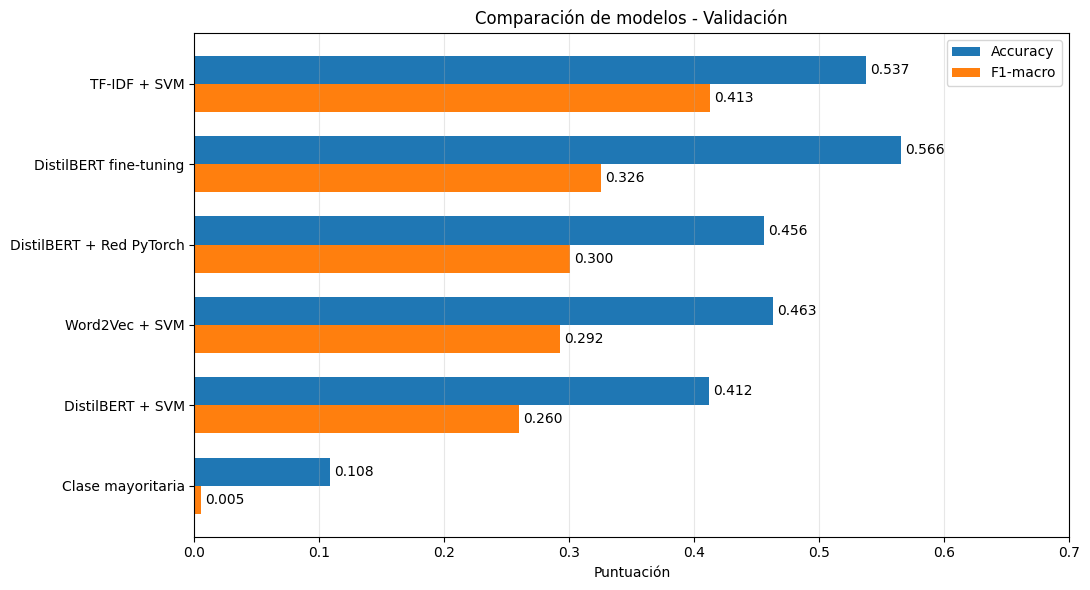

Gráfica comparativa guardada correctamente


In [ ]:
# 87. GRAFICA COMPARATIVA DE TODOS LOS MODELOS

import matplotlib.pyplot as plt
import numpy as np

# Recuperamos los resultados de los modelos.
nombres = comparacion_modelos["modelo"]
accuracy = comparacion_modelos["accuracy"]
f1_macro = comparacion_modelos["f1_macro"]

# Posiciones de los modelos en la gráfica.
posiciones = np.arange(len(nombres))
ancho = 0.35

# Creamos la gráfica.
fig, ax = plt.subplots(figsize=(11, 6))

# Dibujamos las barras de accuracy y F1-macro.
barras_accuracy = ax.barh(
    posiciones - ancho / 2,
    accuracy,
    height=ancho,
    label="Accuracy"
)

barras_f1 = ax.barh(
    posiciones + ancho / 2,
    f1_macro,
    height=ancho,
    label="F1-macro"
)

# Añadimos los valores a las barras.
ax.bar_label(barras_accuracy, fmt="%.3f", padding=3)
ax.bar_label(barras_f1, fmt="%.3f", padding=3)

# Configuramos la gráfica.
ax.set_yticks(posiciones)
ax.set_yticklabels(nombres)
ax.invert_yaxis()

ax.set_xlabel("Puntuación")
ax.set_title("Comparación de modelos - Validación")
ax.set_xlim(0, 0.7)

ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

# Guardamos la gráfica para el informe.
plt.savefig(
    carpeta_resultados / "comparacion_general_modelos.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Gráfica comparativa guardada correctamente")

In [ ]:
# 88. PREPARAR LAS CATEGORIAS DE NIVEL 1

from sklearn.preprocessing import LabelEncoder
import pandas as pd

# Recuperamos las categorías de nivel 1.
y_train_nivel1 = datos_train["nivel_1"].to_numpy()
y_val_nivel1 = datos_val["nivel_1"].to_numpy()

# Creamos un codificador para las 6 categorías.
codificador_nivel1 = LabelEncoder()

# Ajustamos el codificador solo con entrenamiento.
y_train_nivel1_num = codificador_nivel1.fit_transform(
    y_train_nivel1
)

# Aplicamos el mismo codificador a validación.
y_val_nivel1_num = codificador_nivel1.transform(
    y_val_nivel1
)

# Comprobamos los tamaños y el número de categorías.
print("Entrenamiento:", len(y_train_nivel1))
print("Validación:", len(y_val_nivel1))
print("Categorías de nivel 1:", len(codificador_nivel1.classes_))

# Mostramos las categorías y sus cantidades.
tabla_nivel1 = pd.DataFrame({
    "categoria": codificador_nivel1.classes_,
    "proyectos_train": [
        sum(y_train_nivel1 == categoria)
        for categoria in codificador_nivel1.classes_
    ],
    "proyectos_val": [
        sum(y_val_nivel1 == categoria)
        for categoria in codificador_nivel1.classes_
    ]
})

print("\nDISTRIBUCION DE LAS CATEGORIAS DE NIVEL 1")
print(tabla_nivel1.to_string(index=False))

# Guardamos la tabla para el informe.
tabla_nivel1.to_csv(
    carpeta_resultados / "distribucion_nivel1.csv",
    index=False
)

print("\nTabla guardada correctamente")

Entrenamiento: 19188
Validación: 6397
Categorías de nivel 1: 6

DISTRIBUCION DE LAS CATEGORIAS DE NIVEL 1
                  categoria  proyectos_train  proyectos_val
      agricultural sciences              387            131
 engineering and technology             3975           1325
                 humanities              686            230
medical and health sciences             3082           1026
           natural sciences             7513           2504
            social sciences             3545           1181

Tabla guardada correctamente


In [ ]:
# 89. RECUPERAR LOS VECTORES TF-IDF

import joblib
import pandas as pd

# Recuperamos el vectorizador TF-IDF que guardamos anteriormente.
modelo_guardado = joblib.load(
    carpeta_resultados / "modelo_tfidf_svm.joblib"
)

vectorizador_tfidf = modelo_guardado["vectorizador"]

# Recuperamos los textos procesados de entrenamiento y validación.
train_procesado = pd.read_csv(
    carpeta_resultados / "entrenamiento_procesado.csv",
    keep_default_na=False
)

val_procesado = pd.read_csv(
    carpeta_resultados / "validacion_procesada.csv",
    keep_default_na=False
)

# Asociamos cada texto procesado a su proyecto original.
datos_train = datos_train.merge(
    train_procesado,
    on="projectID",
    how="left",
    validate="one_to_one"
)

datos_val = datos_val.merge(
    val_procesado,
    on="projectID",
    how="left",
    validate="one_to_one"
)

# Comprobamos que todos los proyectos tienen su texto recuperado.
assert datos_train["texto_limpio"].notna().all()
assert datos_val["texto_limpio"].notna().all()

# Convertimos los textos en vectores usando el vectorizador guardado.
X_train_tfidf = vectorizador_tfidf.transform(
    datos_train["texto_limpio"]
)

X_val_tfidf = vectorizador_tfidf.transform(
    datos_val["texto_limpio"]
)

# Comprobamos los resultados.
print("Vectorizador TF-IDF recuperado correctamente")
print("Entrenamiento:", X_train_tfidf.shape)
print("Validación:", X_val_tfidf.shape)
print("Categorías de nivel 1:", len(codificador_nivel1.classes_))
print("Vectores preparados correctamente")

Vectorizador TF-IDF recuperado correctamente
Entrenamiento: (19188, 50000)
Validación: (6397, 50000)
Categorías de nivel 1: 6
Vectores preparados correctamente


In [ ]:
# 90. ENTRENAR SVM CON TF-IDF PARA NIVEL 1

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
from time import perf_counter
import joblib

# Recuperamos los parámetros del mejor SVM de nivel 2.
modelo_anterior = modelo_guardado["clasificador"]

# Creamos el clasificador para las 6 categorías.
modelo_svm_tfidf_nivel1 = LinearSVC(
    C=modelo_anterior.C,
    class_weight=modelo_anterior.class_weight,
    dual="auto",
    max_iter=5000,
    random_state=42
)

# Entrenamos con los proyectos de entrenamiento.
print("Entrenando SVM con TF-IDF para nivel 1...")

inicio = perf_counter()

modelo_svm_tfidf_nivel1.fit(
    X_train_tfidf,
    y_train_nivel1
)

tiempo_tfidf_nivel1 = perf_counter() - inicio

# Realizamos las predicciones en validación.
pred_tfidf_nivel1 = modelo_svm_tfidf_nivel1.predict(
    X_val_tfidf
)

# Calculamos las métricas.
accuracy_tfidf_nivel1 = accuracy_score(
    y_val_nivel1,
    pred_tfidf_nivel1
)

f1_tfidf_nivel1 = f1_score(
    y_val_nivel1,
    pred_tfidf_nivel1,
    labels=codificador_nivel1.classes_,
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("\nCategorías:", len(modelo_svm_tfidf_nivel1.classes_))
print("C utilizada:", modelo_svm_tfidf_nivel1.C)
print("Pesos:", modelo_svm_tfidf_nivel1.class_weight)
print(f"Accuracy: {accuracy_tfidf_nivel1:.2%}")
print(f"F1-macro: {f1_tfidf_nivel1:.4f}")
print(f"Tiempo: {tiempo_tfidf_nivel1:.1f} segundos")

# Guardamos el clasificador.
joblib.dump(
    modelo_svm_tfidf_nivel1,
    carpeta_resultados / "modelo_svm_tfidf_nivel1.joblib"
)

# Guardamos las métricas.
resultados_tfidf_nivel1 = pd.DataFrame([{
    "modelo": "TF-IDF + SVM",
    "nivel": 1,
    "categorias": 6,
    "C": modelo_svm_tfidf_nivel1.C,
    "class_weight": str(modelo_svm_tfidf_nivel1.class_weight),
    "accuracy": accuracy_tfidf_nivel1,
    "f1_macro": f1_tfidf_nivel1,
    "tiempo_s": tiempo_tfidf_nivel1
}])

resultados_tfidf_nivel1.to_csv(
    carpeta_resultados / "resultados_tfidf_nivel1.csv",
    index=False
)

print("\nModelo y resultados guardados correctamente")

Entrenando SVM con TF-IDF para nivel 1...

Categorías: 6
C utilizada: 1.0
Pesos: balanced
Accuracy: 68.52%
F1-macro: 0.6286
Tiempo: 3.2 segundos

Modelo y resultados guardados correctamente


In [ ]:
# 91. RECUPERAR LOS VECTORES WORD2VEC

import numpy as np

# Cargamos los vectores Word2Vec guardados anteriormente.
vectores_w2v = np.load(
    carpeta_resultados / "vectores_word2vec.npz"
)

# Recuperamos entrenamiento y validación.
X_train_w2v_scaled = vectores_w2v["X_train"]
X_val_w2v_scaled = vectores_w2v["X_val"]

# Comprobamos las dimensiones.
print("Entrenamiento:", X_train_w2v_scaled.shape)
print("Validación:", X_val_w2v_scaled.shape)

# Comprobamos las etiquetas de nivel 1.
print("Etiquetas entrenamiento:", len(y_train_nivel1))
print("Etiquetas validación:", len(y_val_nivel1))

# Verificamos que coinciden las cantidades.
assert len(X_train_w2v_scaled) == len(y_train_nivel1)
assert len(X_val_w2v_scaled) == len(y_val_nivel1)

print("\nVectores Word2Vec recuperados correctamente")

Entrenamiento: (19188, 200)
Validación: (6397, 200)
Etiquetas entrenamiento: 19188
Etiquetas validación: 6397

Vectores Word2Vec recuperados correctamente


In [ ]:
# 92. COMPROBAR EL ORDEN DE LOS PROYECTOS

# Recuperamos las particiones originales.
particiones_originales = pd.read_csv(
    carpeta_resultados / "particiones.csv"
)

# Recuperamos los identificadores en su orden original.
ids_train_original = particiones_originales.loc[
    particiones_originales["particion"] == "entrenamiento",
    "projectID"
].to_numpy()

ids_val_original = particiones_originales.loc[
    particiones_originales["particion"] == "validacion",
    "projectID"
].to_numpy()

# Comparamos con el orden que tenemos actualmente.
orden_train_correcto = np.array_equal(
    ids_train_original,
    datos_train["projectID"].to_numpy()
)

orden_val_correcto = np.array_equal(
    ids_val_original,
    datos_val["projectID"].to_numpy()
)

# Mostramos los resultados.
print("Orden de entrenamiento correcto:", orden_train_correcto)
print("Orden de validación correcto:", orden_val_correcto)

# Comprobamos que los tamaños también coinciden.
assert len(ids_train_original) == len(X_train_w2v_scaled)
assert len(ids_val_original) == len(X_val_w2v_scaled)

# Detenemos la ejecución si encontramos algún problema.
assert orden_train_correcto, "Error en el orden de entrenamiento"
assert orden_val_correcto, "Error en el orden de validación"

print("\nComprobaciones realizadas correctamente")

Orden de entrenamiento correcto: True
Orden de validación correcto: True

Comprobaciones realizadas correctamente


In [ ]:
# 93. ENTRENAR SVM CON WORD2VEC PARA NIVEL 1

# Creamos el SVM con los mejores parámetros anteriores.
modelo_svm_w2v_nivel1 = LinearSVC(
    C=1.0,
    class_weight=None,
    dual="auto",
    max_iter=5000,
    random_state=42
)

# Entrenamos utilizando los vectores Word2Vec.
print("Entrenando SVM con Word2Vec para nivel 1...")

inicio = perf_counter()

modelo_svm_w2v_nivel1.fit(
    X_train_w2v_scaled,
    y_train_nivel1
)

tiempo_w2v_nivel1 = perf_counter() - inicio

# Realizamos las predicciones de validación.
pred_w2v_nivel1 = modelo_svm_w2v_nivel1.predict(
    X_val_w2v_scaled
)

# Calculamos las métricas.
accuracy_w2v_nivel1 = accuracy_score(
    y_val_nivel1,
    pred_w2v_nivel1
)

f1_w2v_nivel1 = f1_score(
    y_val_nivel1,
    pred_w2v_nivel1,
    labels=codificador_nivel1.classes_,
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("\nCategorías:", len(modelo_svm_w2v_nivel1.classes_))
print("C utilizada:", modelo_svm_w2v_nivel1.C)
print("Pesos:", modelo_svm_w2v_nivel1.class_weight)
print(f"Accuracy: {accuracy_w2v_nivel1:.2%}")
print(f"F1-macro: {f1_w2v_nivel1:.4f}")
print(f"Tiempo: {tiempo_w2v_nivel1:.1f} segundos")

# Guardamos el modelo entrenado.
joblib.dump(
    modelo_svm_w2v_nivel1,
    carpeta_resultados / "modelo_svm_word2vec_nivel1.joblib"
)

# Guardamos los resultados.
resultados_w2v_nivel1 = pd.DataFrame([{
    "modelo": "Word2Vec + SVM",
    "nivel": 1,
    "categorias": 6,
    "C": modelo_svm_w2v_nivel1.C,
    "class_weight": str(modelo_svm_w2v_nivel1.class_weight),
    "accuracy": accuracy_w2v_nivel1,
    "f1_macro": f1_w2v_nivel1,
    "tiempo_s": tiempo_w2v_nivel1
}])

resultados_w2v_nivel1.to_csv(
    carpeta_resultados / "resultados_word2vec_nivel1.csv",
    index=False
)

print("\nModelo y resultados guardados correctamente")

Entrenando SVM con Word2Vec para nivel 1...

Categorías: 6
C utilizada: 1.0
Pesos: None
Accuracy: 64.62%
F1-macro: 0.5491
Tiempo: 10.6 segundos

Modelo y resultados guardados correctamente


In [ ]:
# 94. RECUPERAR LOS EMBEDDINGS DE DISTILBERT

import numpy as np
import joblib

# Recuperamos los embeddings originales de DistilBERT.
X_train_bert = np.load(
    carpeta_resultados / "embeddings_distilbert_train.npy"
)

X_val_bert = np.load(
    carpeta_resultados / "embeddings_distilbert_val.npy"
)

# Recuperamos el escalador que utilizamos anteriormente.
escalador_bert = joblib.load(
    carpeta_resultados / "escalador_distilbert.joblib"
)

# Aplicamos el mismo escalador, sin volver a ajustarlo.
X_train_bert_scaled = escalador_bert.transform(X_train_bert)

X_val_bert_scaled = escalador_bert.transform(X_val_bert)

# Comprobamos las dimensiones.
print("Entrenamiento:", X_train_bert_scaled.shape)
print("Validación:", X_val_bert_scaled.shape)

# Comprobamos que coinciden con las etiquetas de nivel 1.
assert len(X_train_bert_scaled) == len(y_train_nivel1)
assert len(X_val_bert_scaled) == len(y_val_nivel1)

# Comprobamos que los vectores contienen valores válidos.
assert np.isfinite(X_train_bert_scaled).all()
assert np.isfinite(X_val_bert_scaled).all()

print("Categorías de nivel 1:", len(codificador_nivel1.classes_))

print("\nEmbeddings de DistilBERT recuperados correctamente")

Entrenamiento: (19188, 768)
Validación: (6397, 768)
Categorías de nivel 1: 6

Embeddings de DistilBERT recuperados correctamente


In [ ]:
# 95. ENTRENAR SVM CON DISTILBERT PARA NIVEL 1

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
from time import perf_counter
import joblib

# Creamos el SVM con los mejores parámetros anteriores.
modelo_svm_bert_nivel1 = LinearSVC(
    C=1.0,
    class_weight=None,
    dual="auto",
    max_iter=5000,
    random_state=42
)

# Entrenamos utilizando los embeddings de DistilBERT.
print("Entrenando SVM con DistilBERT para nivel 1...")

inicio = perf_counter()

modelo_svm_bert_nivel1.fit(
    X_train_bert_scaled,
    y_train_nivel1
)

tiempo_bert_nivel1 = perf_counter() - inicio

# Realizamos las predicciones de validación.
pred_bert_nivel1 = modelo_svm_bert_nivel1.predict(
    X_val_bert_scaled
)

# Calculamos las métricas.
accuracy_bert_nivel1 = accuracy_score(
    y_val_nivel1,
    pred_bert_nivel1
)

f1_bert_nivel1 = f1_score(
    y_val_nivel1,
    pred_bert_nivel1,
    labels=codificador_nivel1.classes_,
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("\nCategorías:", len(modelo_svm_bert_nivel1.classes_))
print("C utilizada:", modelo_svm_bert_nivel1.C)
print("Pesos:", modelo_svm_bert_nivel1.class_weight)
print(f"Accuracy: {accuracy_bert_nivel1:.2%}")
print(f"F1-macro: {f1_bert_nivel1:.4f}")
print(f"Tiempo: {tiempo_bert_nivel1:.1f} segundos")

# Guardamos el modelo entrenado.
joblib.dump(
    modelo_svm_bert_nivel1,
    carpeta_resultados / "modelo_svm_distilbert_nivel1.joblib"
)

# Guardamos los resultados.
resultados_bert_nivel1 = pd.DataFrame([{
    "modelo": "DistilBERT + SVM",
    "nivel": 1,
    "categorias": 6,
    "C": modelo_svm_bert_nivel1.C,
    "class_weight": str(modelo_svm_bert_nivel1.class_weight),
    "accuracy": accuracy_bert_nivel1,
    "f1_macro": f1_bert_nivel1,
    "tiempo_s": tiempo_bert_nivel1
}])

resultados_bert_nivel1.to_csv(
    carpeta_resultados / "resultados_distilbert_nivel1.csv",
    index=False
)

print("\nModelo y resultados guardados correctamente")

Entrenando SVM con DistilBERT para nivel 1...

Categorías: 6
C utilizada: 1.0
Pesos: None
Accuracy: 65.52%
F1-macro: 0.5874
Tiempo: 160.1 segundos

Modelo y resultados guardados correctamente


In [ ]:
# 96. COMPARAR LAS TRES REPRESENTACIONES EN LOS DOS NIVELES

# Recuperamos los resultados de nivel 1 que hemos guardado.
tfidf_n1 = pd.read_csv(
    carpeta_resultados / "resultados_tfidf_nivel1.csv"
).iloc[0]

w2v_n1 = pd.read_csv(
    carpeta_resultados / "resultados_word2vec_nivel1.csv"
).iloc[0]

bert_n1 = pd.read_csv(
    carpeta_resultados / "resultados_distilbert_nivel1.csv"
).iloc[0]

# Recuperamos los resultados de nivel 2.
tfidf_n2 = comparacion_modelos[
    comparacion_modelos["modelo"] == "TF-IDF + SVM"
].iloc[0]

w2v_n2 = comparacion_modelos[
    comparacion_modelos["modelo"] == "Word2Vec + SVM"
].iloc[0]

bert_n2 = comparacion_modelos[
    comparacion_modelos["modelo"] == "DistilBERT + SVM"
].iloc[0]

# Creamos una tabla comparando las tres representaciones.
comparacion_niveles = pd.DataFrame([
    {
        "representacion": "TF-IDF",
        "f1_nivel2": tfidf_n2["f1_macro"],
        "f1_nivel1": tfidf_n1["f1_macro"]
    },
    {
        "representacion": "Word2Vec",
        "f1_nivel2": w2v_n2["f1_macro"],
        "f1_nivel1": w2v_n1["f1_macro"]
    },
    {
        "representacion": "DistilBERT",
        "f1_nivel2": bert_n2["f1_macro"],
        "f1_nivel1": bert_n1["f1_macro"]
    }
])

# Calculamos la diferencia de F1 entre ambos niveles.
comparacion_niveles["diferencia_f1"] = (
    comparacion_niveles["f1_nivel1"]
    - comparacion_niveles["f1_nivel2"]
)

# Mostramos los resultados.
print("COMPARACION DE REPRESENTACIONES ENTRE NIVELES")
print(comparacion_niveles.round(4).to_string(index=False))

# Calculamos el ranking de cada nivel.
ranking_nivel2 = comparacion_niveles.sort_values(
    "f1_nivel2", ascending=False
)["representacion"].tolist()

ranking_nivel1 = comparacion_niveles.sort_values(
    "f1_nivel1", ascending=False
)["representacion"].tolist()

print("\nRanking nivel 2:", " > ".join(ranking_nivel2))
print("Ranking nivel 1:", " > ".join(ranking_nivel1))

print("\n¿Cambia el ranking?:", ranking_nivel1 != ranking_nivel2)

# Guardamos la comparación para el informe.
comparacion_niveles.to_csv(
    carpeta_resultados / "comparacion_niveles_1_2.csv",
    index=False
)

print("\nComparación guardada correctamente")

COMPARACION DE REPRESENTACIONES ENTRE NIVELES
representacion  f1_nivel2  f1_nivel1  diferencia_f1
        TF-IDF     0.4127     0.6286         0.2159
      Word2Vec     0.2922     0.5491         0.2569
    DistilBERT     0.2601     0.5874         0.3274

Ranking nivel 2: TF-IDF > Word2Vec > DistilBERT
Ranking nivel 1: TF-IDF > DistilBERT > Word2Vec

¿Cambia el ranking?: True

Comparación guardada correctamente


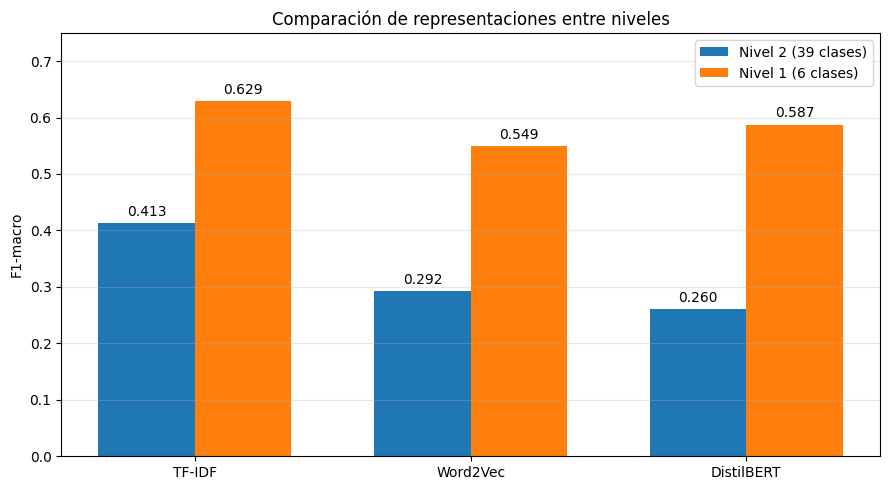

Gráfica comparativa guardada correctamente


In [ ]:
# 97. GRAFICA COMPARATIVA ENTRE NIVEL 1 Y NIVEL 2

import matplotlib.pyplot as plt
import numpy as np

# Recuperamos los resultados de las tres representaciones.
representaciones = comparacion_niveles["representacion"]

f1_nivel2 = comparacion_niveles["f1_nivel2"]
f1_nivel1 = comparacion_niveles["f1_nivel1"]

# Preparamos las posiciones de las barras.
posiciones = np.arange(len(representaciones))
ancho = 0.35

# Creamos la gráfica.
fig, ax = plt.subplots(figsize=(9, 5))

# Dibujamos las barras de ambos niveles.
barras_nivel2 = ax.bar(
    posiciones - ancho / 2,
    f1_nivel2,
    ancho,
    label="Nivel 2 (39 clases)"
)

barras_nivel1 = ax.bar(
    posiciones + ancho / 2,
    f1_nivel1,
    ancho,
    label="Nivel 1 (6 clases)"
)

# Añadimos los valores encima de las barras.
ax.bar_label(barras_nivel2, fmt="%.3f", padding=3)
ax.bar_label(barras_nivel1, fmt="%.3f", padding=3)

# Configuramos la gráfica.
ax.set_xticks(posiciones)
ax.set_xticklabels(representaciones)

ax.set_ylabel("F1-macro")
ax.set_title("Comparación de representaciones entre niveles")

ax.set_ylim(0, 0.75)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Guardamos la gráfica para el informe.
plt.savefig(
    carpeta_resultados / "comparacion_niveles_1_2.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Gráfica comparativa guardada correctamente")

In [ ]:
# 98. ANALIZAR EL TRUNCAMIENTO DE DISTILBERT

# Preparamos los conjuntos de textos originales.
conjuntos_texto = {
    "entrenamiento": datos_train["summary"].tolist(),
    "validacion": datos_val["summary"].tolist()
}

resultados_truncamiento = []

# Analizamos cada conjunto.
for nombre, textos in conjuntos_texto.items():

    longitudes = []

    # Procesamos los textos por grupos.
    for inicio in range(0, len(textos), 64):

        lote = textos[inicio:inicio + 64]

        # Contamos los tokens sin truncar los textos.
        tokens = tokenizador(
            lote,
            truncation=False,
            padding=False,
            return_length=True
        )

        longitudes.extend(tokens["length"])

    # Contamos los resúmenes que superan el límite.
    total = len(longitudes)
    truncados = sum(longitud > 512 for longitud in longitudes)

    porcentaje = 100 * truncados / total

    resultados_truncamiento.append({
        "conjunto": nombre,
        "total_resumenes": total,
        "resumenes_truncados": truncados,
        "porcentaje_truncados": porcentaje
    })

# Creamos una tabla con los resultados.
tabla_truncamiento = pd.DataFrame(resultados_truncamiento)

print("ANALISIS DEL TRUNCAMIENTO DE DISTILBERT")
print(tabla_truncamiento.to_string(index=False))

# Guardamos los resultados.
tabla_truncamiento.to_csv(
    carpeta_resultados / "truncamiento_distilbert.csv",
    index=False
)

print("\nResultados guardados correctamente")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (686 > 512). Running this sequence through the model will result in indexing errors


ANALISIS DEL TRUNCAMIENTO DE DISTILBERT
     conjunto  total_resumenes  resumenes_truncados  porcentaje_truncados
entrenamiento            19188                   11              0.057327
   validacion             6397                    8              0.125059

Resultados guardados correctamente


In [ ]:
# 99. PREPARAR EL CONJUNTO DE PRUEBA

# Recuperamos los proyectos de prueba originales.
datos_test = datos[
    datos["particion"] == "prueba"
].copy()

# Recuperamos los resúmenes originales.
textos_test = datos_test["summary"].tolist()

# Recuperamos las categorías de nivel 2.
y_test = datos_test["nivel_2"].to_numpy()

# Convertimos las categorías en números utilizando
# el mismo codificador del entrenamiento.
y_test_num = codificador_etiquetas.transform(y_test)

# Comprobamos que todos los proyectos tienen resumen.
assert datos_test["summary"].notna().all()

# Comprobamos que las categorías son válidas.
assert len(set(y_test)) == 39

# Comprobamos que no hay proyectos repetidos
# entre entrenamiento, validación y prueba.
ids_train = set(datos_train["projectID"])
ids_val = set(datos_val["projectID"])
ids_test = set(datos_test["projectID"])

assert ids_train.isdisjoint(ids_test)
assert ids_val.isdisjoint(ids_test)

# Mostramos los resultados.
print("CONJUNTO DE PRUEBA PREPARADO")

print("Proyectos de prueba:", len(datos_test))
print("Resúmenes disponibles:", len(textos_test))
print("Etiquetas disponibles:", len(y_test))
print("Categorías:", len(set(y_test)))

print("\nNo hay proyectos compartidos entre particiones")
print("Conjunto de prueba preparado correctamente")

CONJUNTO DE PRUEBA PREPARADO
Proyectos de prueba: 6397
Resúmenes disponibles: 6397
Etiquetas disponibles: 6397
Categorías: 39

No hay proyectos compartidos entre particiones
Conjunto de prueba preparado correctamente


In [ ]:
# 100. PREPROCESAR LOS RESUMENES DE PRUEBA PARA TF-IDF

# Recuperamos spaCy y su modelo de inglés.
%pip install -q spacy
!python -m spacy download en_core_web_sm

import spacy
import json
from tqdm.auto import tqdm

nlp = spacy.load(
    "en_core_web_sm",
    disable=["parser", "ner"]
)

# Comprobamos que usamos la misma versión del modelo de inglés.
with open(
    carpeta_resultados / "versiones_hasta_tfidf.json",
    "r",
    encoding="utf-8"
) as archivo:
    versiones_anteriores = json.load(archivo)

print("Versión original del modelo:", versiones_anteriores["en_core_web_sm"])
print("Versión actual del modelo:", nlp.meta["version"])

assert nlp.meta["version"] == versiones_anteriores["en_core_web_sm"]

# Utilizamos las mismas palabras vacías que anteriormente.
palabras_vacias = nlp.Defaults.stop_words

# Aplicamos exactamente las mismas reglas de limpieza.
def limpiar_documento(documento):

    palabras = []

    for token in documento:

        if token.is_stop or not token.is_alpha:
            continue

        lema = token.lemma_.lower().strip()

        if len(lema) < 3 or not lema.isalpha():
            continue

        if lema in palabras_vacias:
            continue

        palabras.append(lema)

    return palabras


# Procesamos los resúmenes de prueba.
tokens_test = []

documentos_test = nlp.pipe(
    datos_test["summary"],
    batch_size=64,
    n_process=1
)

for documento in tqdm(
    documentos_test,
    total=len(datos_test),
    desc="Procesando prueba"
):
    tokens_test.append(limpiar_documento(documento))

# Guardamos el texto procesado en una nueva columna.
datos_test["texto_limpio"] = [
    " ".join(palabras) for palabras in tokens_test
]

# Guardamos los resultados para no repetir el procesamiento.
datos_test[["projectID", "texto_limpio"]].to_csv(
    carpeta_resultados / "prueba_procesada.csv",
    index=False,
    encoding="utf-8"
)

# Comprobamos los resultados.
print("\nResúmenes procesados:", len(datos_test))
print("Resúmenes sin palabras:",
      (datos_test["texto_limpio"] == "").sum())

print("Archivo guardado correctamente")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 42.8 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Versión original del modelo: 3.8.0
Versión actual del modelo: 3.8.0


Procesando prueba:   0%|          | 0/6397 [00:00<?, ?it/s]


Resúmenes procesados: 6397
Resúmenes sin palabras: 0
Archivo guardado correctamente


In [ ]:
# 101. CONVERTIR LOS RESUMENES DE PRUEBA EN VECTORES TF-IDF

# Utilizamos el vectorizador que ya tenemos entrenado.
# No utilizamos fit_transform porque no queremos
# aprender información nueva del conjunto de prueba.
X_test_tfidf = vectorizador_tfidf.transform(
    datos_test["texto_limpio"]
)

# Comprobamos las dimensiones obtenidas.
print("VECTORES TF-IDF DEL CONJUNTO DE PRUEBA")

print("Entrenamiento:", X_train_tfidf.shape)
print("Validación:", X_val_tfidf.shape)
print("Prueba:", X_test_tfidf.shape)

# Comprobamos que no hemos perdido proyectos.
assert X_test_tfidf.shape[0] == len(y_test)

# Comprobamos que utilizamos el mismo vocabulario.
assert X_test_tfidf.shape[1] == X_train_tfidf.shape[1]

# Contamos los resúmenes que no contienen
# ningún término reconocido por el vectorizador.
filas_cero_test = (
    X_test_tfidf.getnnz(axis=1) == 0
).sum()

print("\nVectores completamente vacíos:", filas_cero_test)
print("Vectores TF-IDF preparados correctamente")

VECTORES TF-IDF DEL CONJUNTO DE PRUEBA
Entrenamiento: (19188, 50000)
Validación: (6397, 50000)
Prueba: (6397, 50000)

Vectores completamente vacíos: 0
Vectores TF-IDF preparados correctamente


In [ ]:
# 102. EVALUAR TF-IDF + SVM EN EL CONJUNTO DE PRUEBA

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Recuperamos el mejor clasificador TF-IDF + SVM.
# Ya está entrenado y no vamos a modificarlo.
mejor_svm_tfidf = modelo_guardado["clasificador"]

# Realizamos las predicciones sobre los proyectos de prueba.
print("Evaluando TF-IDF + SVM en test...")

pred_tfidf_test = mejor_svm_tfidf.predict(X_test_tfidf)

# Calculamos las métricas definitivas.
accuracy_tfidf_test = accuracy_score(
    y_test,
    pred_tfidf_test
)

f1_tfidf_test = f1_score(
    y_test,
    pred_tfidf_test,
    labels=clases_nivel2,
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("\nRESULTADOS DEFINITIVOS TF-IDF + SVM")

print("Proyectos evaluados:", len(y_test))
print("Categorías:", len(mejor_svm_tfidf.classes_))

print(f"Accuracy en test: {accuracy_tfidf_test:.2%}")
print(f"F1-macro en test: {f1_tfidf_test:.4f}")

# Comparamos con los resultados de validación.
print("\nCOMPARACIÓN CON VALIDACIÓN")

print("Accuracy validación: 53.71%")
print(f"Accuracy test: {accuracy_tfidf_test:.2%}")

print("F1-macro validación: 0.4127")
print(f"F1-macro test: {f1_tfidf_test:.4f}")

# Guardamos las métricas definitivas.
resultados_tfidf_test = pd.DataFrame([{
    "modelo": "TF-IDF + SVM",
    "conjunto": "test",
    "accuracy": accuracy_tfidf_test,
    "f1_macro": f1_tfidf_test
}])

resultados_tfidf_test.to_csv(
    carpeta_resultados / "resultados_tfidf_test.csv",
    index=False
)

print("\nResultados guardados correctamente")

Evaluando TF-IDF + SVM en test...

RESULTADOS DEFINITIVOS TF-IDF + SVM
Proyectos evaluados: 6397
Categorías: 39
Accuracy en test: 52.81%
F1-macro en test: 0.4072

COMPARACIÓN CON VALIDACIÓN
Accuracy validación: 53.71%
Accuracy test: 52.81%
F1-macro validación: 0.4127
F1-macro test: 0.4072

Resultados guardados correctamente


In [ ]:
# 103. EVALUAR TF-IDF POR CATEGORIA EN TEST

from sklearn.metrics import classification_report

# Calculamos las métricas de las 39 categorías.
reporte_tfidf_test = classification_report(
    y_test,
    pred_tfidf_test,
    labels=clases_nivel2,
    output_dict=True,
    zero_division=0
)

# Convertimos los resultados en una tabla.
tabla_reporte_tfidf_test = pd.DataFrame(
    reporte_tfidf_test
).T

# Guardamos el informe completo.
tabla_reporte_tfidf_test.to_csv(
    carpeta_resultados / "reporte_clases_tfidf_test.csv",
    encoding="utf-8"
)

# Mostramos las métricas generales.
print("RESULTADOS GENERALES TF-IDF EN TEST")

print("Accuracy:",
      round(reporte_tfidf_test["accuracy"], 4))

print("F1-macro:",
      round(reporte_tfidf_test["macro avg"]["f1-score"], 4))

# Mostramos las primeras 10 categorías.
print("\nRESULTADOS POR CATEGORIA")
print(tabla_reporte_tfidf_test.head(10).to_string())

print("\nReporte completo guardado correctamente")

RESULTADOS GENERALES TF-IDF EN TEST
Accuracy: 0.5281
F1-macro: 0.4072

RESULTADOS POR CATEGORIA
                                      precision    recall  f1-score  support
agricultural biotechnology             0.000000  0.000000  0.000000      7.0
agriculture, forestry, and fisheries   0.364583  0.380435  0.372340     92.0
animal and dairy science               0.352941  0.461538  0.400000     26.0
arts                                   0.586207  0.435897  0.500000     39.0
basic medicine                         0.576531  0.590078  0.583226    383.0
biological sciences                    0.648425  0.564214  0.603395    693.0
chemical engineering                   0.461538  0.230769  0.307692     26.0
chemical sciences                      0.498305  0.462264  0.479608    318.0
civil engineering                      0.342105  0.406250  0.371429     64.0
clinical medicine                      0.548463  0.615385  0.580000    377.0

Reporte completo guardado correctamente


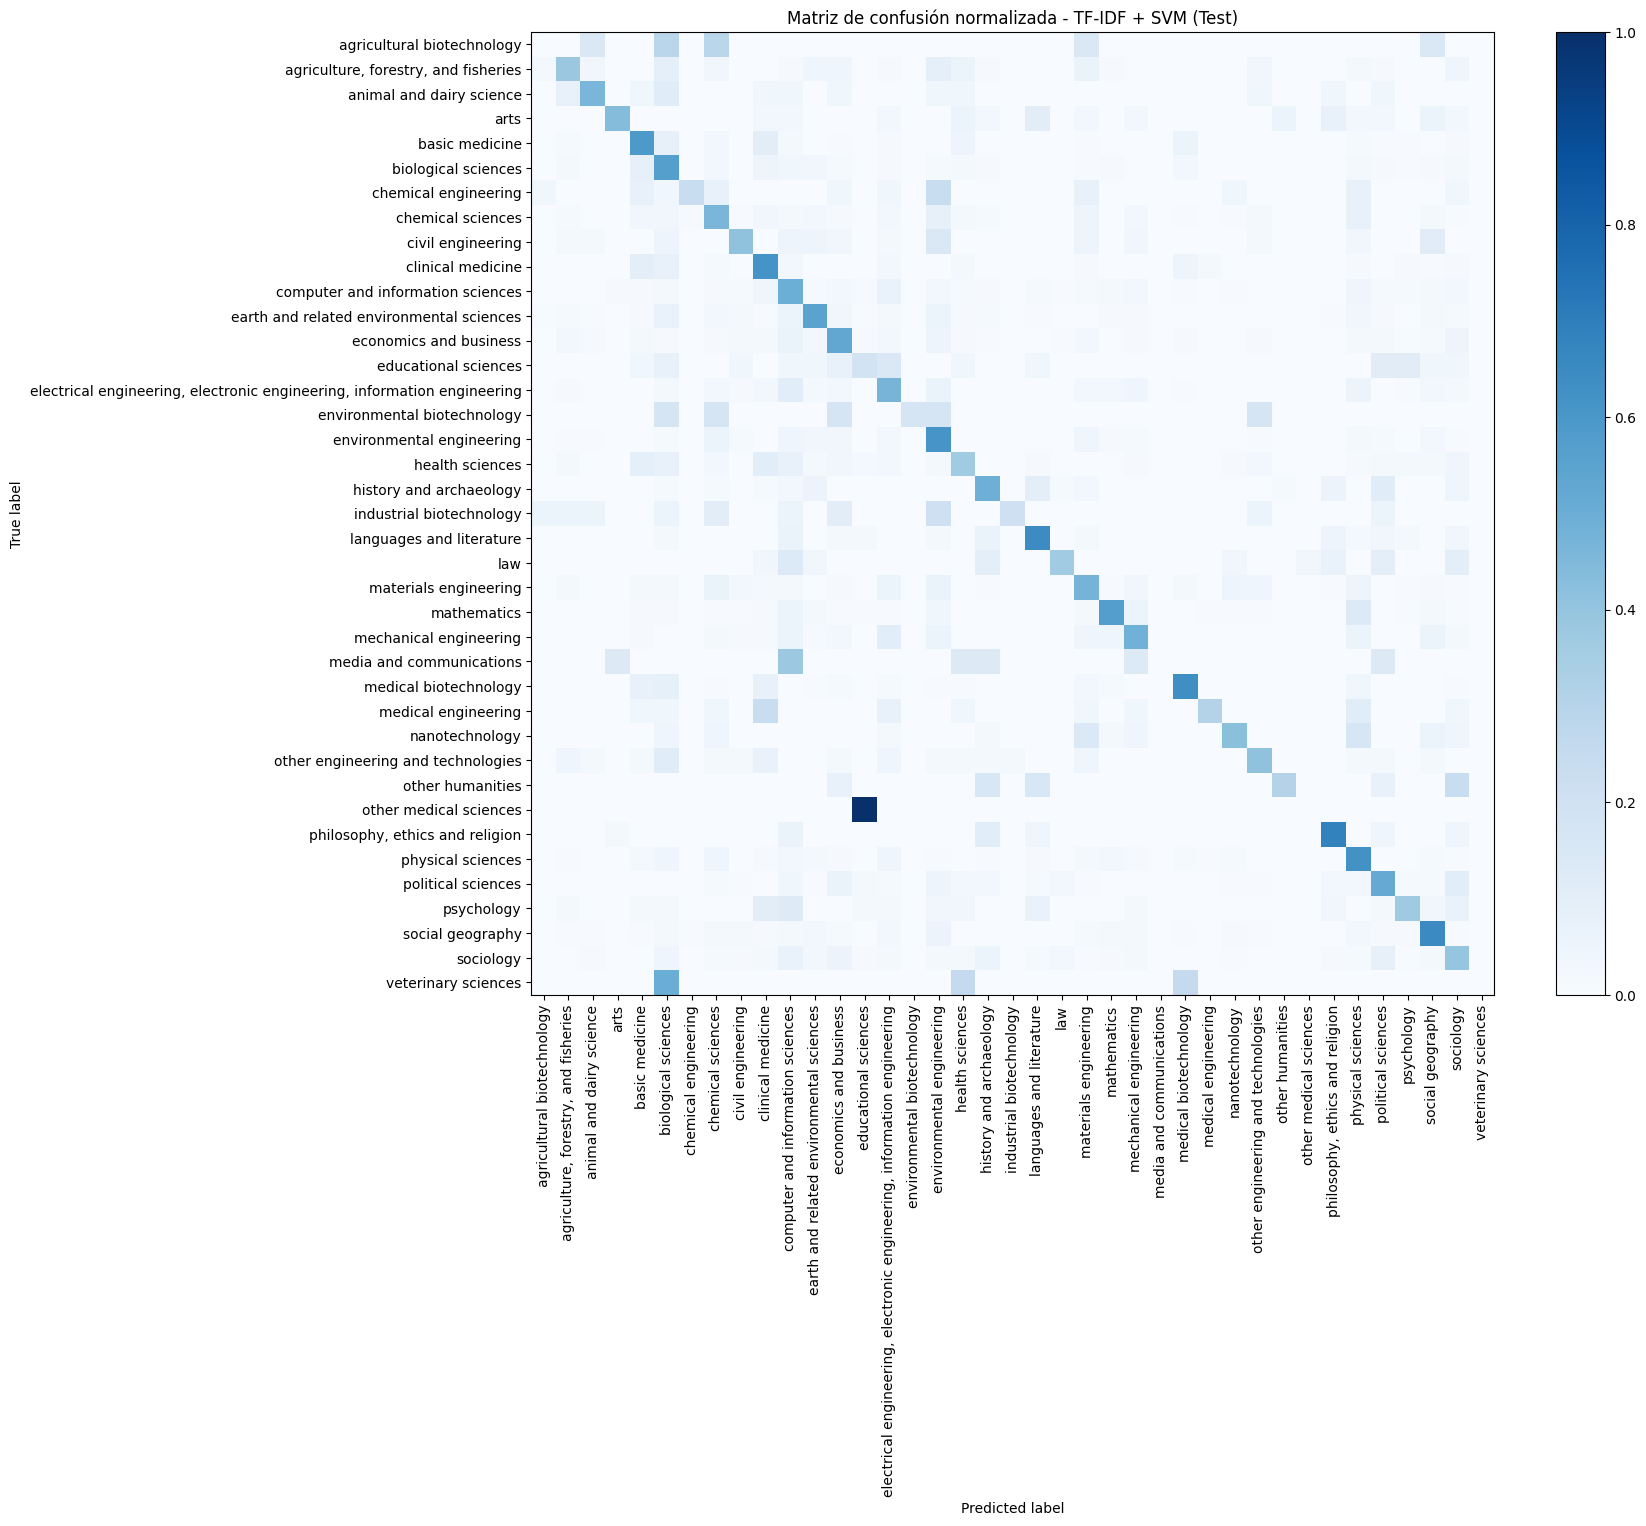

Matriz de confusión guardada correctamente
Total de proyectos: 6397
Predicciones correctas: 3378
Predicciones incorrectas: 3019


In [ ]:
# 104. MATRIZ DE CONFUSION DE TF-IDF EN TEST

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Calculamos la matriz de confusión con los valores originales.
matriz_tfidf_test = confusion_matrix(
    y_test,
    pred_tfidf_test,
    labels=clases_nivel2
)

# Calculamos la matriz normalizada.
matriz_tfidf_test_normalizada = confusion_matrix(
    y_test,
    pred_tfidf_test,
    labels=clases_nivel2,
    normalize="true"
)

# Dibujamos la matriz normalizada.
fig, ax = plt.subplots(figsize=(18, 15))

grafica = ConfusionMatrixDisplay(
    confusion_matrix=matriz_tfidf_test_normalizada,
    display_labels=clases_nivel2
)

grafica.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    include_values=False
)

plt.title("Matriz de confusión normalizada - TF-IDF + SVM (Test)")
plt.tight_layout()

# Guardamos la gráfica para el informe.
plt.savefig(
    carpeta_resultados / "matriz_confusion_tfidf_test.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# Guardamos también los valores originales de la matriz.
tabla_matriz_tfidf_test = pd.DataFrame(
    matriz_tfidf_test,
    index=clases_nivel2,
    columns=clases_nivel2
)

tabla_matriz_tfidf_test.to_csv(
    carpeta_resultados / "matriz_confusion_tfidf_test.csv"
)

# Comprobamos los resultados.
print("Matriz de confusión guardada correctamente")
print("Total de proyectos:", matriz_tfidf_test.sum())
print("Predicciones correctas:", np.trace(matriz_tfidf_test))
print("Predicciones incorrectas:",
      matriz_tfidf_test.sum() - np.trace(matriz_tfidf_test))

In [ ]:
# 105. IDENTIFICAR LAS PRINCIPALES CONFUSIONES DE TF-IDF EN TEST

# Creamos una lista para guardar los errores.
errores_tfidf_test = []

# Recorremos las categorías reales.
for i, categoria_real in enumerate(clases_nivel2):

    # Recorremos las categorías predichas.
    for j, categoria_predicha in enumerate(clases_nivel2):

        # Solo estudiamos las predicciones incorrectas.
        if i != j and matriz_tfidf_test[i, j] > 0:

            cantidad = matriz_tfidf_test[i, j]
            total_real = matriz_tfidf_test[i].sum()

            porcentaje = 100 * cantidad / total_real

            errores_tfidf_test.append({
                "categoria_real": categoria_real,
                "categoria_predicha": categoria_predicha,
                "proyectos_confundidos": int(cantidad),
                "porcentaje_clase_real": round(porcentaje, 2)
            })

# Convertimos los errores en una tabla.
tabla_errores_tfidf_test = pd.DataFrame(errores_tfidf_test)

# Ordenamos por número de errores.
tabla_errores_tfidf_test = tabla_errores_tfidf_test.sort_values(
    "proyectos_confundidos",
    ascending=False
)

# Mostramos las 10 confusiones más frecuentes.
print("PRINCIPALES CONFUSIONES DE TF-IDF EN TEST")

print(tabla_errores_tfidf_test.head(10).to_string(index=False))

# Comprobamos el número total de errores.
print("\nTotal de errores:",
      tabla_errores_tfidf_test["proyectos_confundidos"].sum())

# Guardamos la tabla completa.
tabla_errores_tfidf_test.to_csv(
    carpeta_resultados / "errores_tfidf_test.csv",
    index=False,
    encoding="utf-8"
)

print("\nTabla de errores guardada correctamente")

PRINCIPALES CONFUSIONES DE TF-IDF EN TEST
                                                         categoria_real                                                      categoria_predicha  proyectos_confundidos  porcentaje_clase_real
                                                    biological sciences                                                          basic medicine                     55                   7.94
electrical engineering, electronic engineering, information engineering                                       computer and information sciences                     41                  10.73
                                      computer and information sciences electrical engineering, electronic engineering, information engineering                     40                   6.87
                                                         basic medicine                                                       clinical medicine                     40                  10.44
        

In [ ]:
# 106. ANALIZAR LOS ERRORES DE TF-IDF SEGUN EUROSCIVOC

# Relacionamos cada categoría de nivel 2 con su nivel 1.
mapa_nivel1 = (
    datos.drop_duplicates("nivel_2")
    .set_index("nivel_2")["nivel_1"]
    .to_dict()
)

# Recuperamos los errores de TF-IDF.
tabla_jerarquia_tfidf = tabla_errores_tfidf_test.copy()

# Buscamos el nivel 1 de cada categoría real y predicha.
tabla_jerarquia_tfidf["nivel1_real"] = (
    tabla_jerarquia_tfidf["categoria_real"].map(mapa_nivel1)
)

tabla_jerarquia_tfidf["nivel1_predicha"] = (
    tabla_jerarquia_tfidf["categoria_predicha"].map(mapa_nivel1)
)

# Comprobamos que todas las categorías tienen nivel 1.
assert tabla_jerarquia_tfidf["nivel1_real"].notna().all()
assert tabla_jerarquia_tfidf["nivel1_predicha"].notna().all()

# Comprobamos si las categorías pertenecen a la misma rama.
tabla_jerarquia_tfidf["misma_rama"] = (
    tabla_jerarquia_tfidf["nivel1_real"]
    == tabla_jerarquia_tfidf["nivel1_predicha"]
)

# Contamos los errores dentro de la misma rama.
errores_misma_rama_tfidf = tabla_jerarquia_tfidf.loc[
    tabla_jerarquia_tfidf["misma_rama"],
    "proyectos_confundidos"
].sum()

# Contamos todos los errores.
total_errores_tfidf = tabla_jerarquia_tfidf[
    "proyectos_confundidos"
].sum()

# Calculamos los errores entre ramas diferentes.
errores_distinta_rama_tfidf = (
    total_errores_tfidf - errores_misma_rama_tfidf
)

# Calculamos los porcentajes.
porcentaje_misma_rama_tfidf = (
    100 * errores_misma_rama_tfidf / total_errores_tfidf
)

porcentaje_distinta_rama_tfidf = (
    100 * errores_distinta_rama_tfidf / total_errores_tfidf
)

# Mostramos los resultados.
print("ANALISIS DE ERRORES DE TF-IDF SEGUN EUROSCIVOC")

print("Errores totales:", total_errores_tfidf)
print("Errores en la misma rama:", errores_misma_rama_tfidf)
print("Errores en distintas ramas:", errores_distinta_rama_tfidf)

print(f"\nMisma rama: {porcentaje_misma_rama_tfidf:.2f}%")
print(f"Distintas ramas: {porcentaje_distinta_rama_tfidf:.2f}%")

# Mostramos las 10 principales confusiones.
print("\nPRINCIPALES CONFUSIONES:")

display(
    tabla_jerarquia_tfidf[
        ["categoria_real", "categoria_predicha",
         "proyectos_confundidos", "misma_rama"]
    ].head(10)
)

# Comprobamos que hemos analizado todos los errores.
assert total_errores_tfidf == 3019

# Guardamos los resultados para el informe.
tabla_jerarquia_tfidf.to_csv(
    carpeta_resultados / "errores_jerarquia_tfidf_test.csv",
    index=False
)

print("\nResultados guardados correctamente")

ANALISIS DE ERRORES DE TF-IDF SEGUN EUROSCIVOC
Errores totales: 3019
Errores en la misma rama: 998
Errores en distintas ramas: 2021

Misma rama: 33.06%
Distintas ramas: 66.94%

PRINCIPALES CONFUSIONES:


,categoria_real,categoria_predicha,proyectos_confundidos,misma_rama
68,biological sciences,basic medicine,55,False
269,"electrical engineering, electronic engineering...",computer and information sciences,41,False
174,computer and information sciences,"electrical engineering, electronic engineering...",40,False
51,basic medicine,clinical medicine,40,True
145,clinical medicine,basic medicine,38,True
72,biological sciences,clinical medicine,35,False
49,basic medicine,biological sciences,31,False
146,clinical medicine,biological sciences,29,False
73,biological sciences,computer and information sciences,26,True
416,mathematics,physical sciences,25,True



Resultados guardados correctamente


In [ ]:
# 107. CALCULAR LA INCERTIDUMBRE DE TF-IDF EN TEST

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Fijamos la semilla para poder repetir los resultados.
rng = np.random.default_rng(42)

# Número de repeticiones del bootstrap.
num_repeticiones = 1000

# Guardamos las métricas de cada repetición.
accuracy_bootstrap = []
f1_bootstrap = []

# Repetimos la evaluación sobre muestras de test.
for i in range(num_repeticiones):

    # Seleccionamos proyectos aleatoriamente con reemplazo.
    indices = rng.choice(
        len(y_test),
        size=len(y_test),
        replace=True
    )

    # Recuperamos las etiquetas reales y predichas.
    reales = y_test[indices]
    predichas = pred_tfidf_test[indices]

    # Calculamos las métricas de esta muestra.
    accuracy_bootstrap.append(
        accuracy_score(reales, predichas)
    )

    f1_bootstrap.append(
        f1_score(
            reales,
            predichas,
            labels=clases_nivel2,
            average="macro",
            zero_division=0
        )
    )

# Calculamos los intervalos de confianza del 95 %.
intervalo_accuracy = np.percentile(
    accuracy_bootstrap, [2.5, 97.5]
)

intervalo_f1 = np.percentile(
    f1_bootstrap, [2.5, 97.5]
)

# Mostramos los resultados.
print("INCERTIDUMBRE DE TF-IDF EN TEST")

print(f"Accuracy: {accuracy_tfidf_test:.4f}")
print(
    f"Intervalo del 95 %: "
    f"[{intervalo_accuracy[0]:.4f}, {intervalo_accuracy[1]:.4f}]"
)

print(f"\nF1-macro: {f1_tfidf_test:.4f}")
print(
    f"Intervalo del 95 %: "
    f"[{intervalo_f1[0]:.4f}, {intervalo_f1[1]:.4f}]"
)

# Guardamos los resultados.
tabla_incertidumbre = pd.DataFrame([
    {
        "metrica": "accuracy",
        "valor": accuracy_tfidf_test,
        "limite_inferior": intervalo_accuracy[0],
        "limite_superior": intervalo_accuracy[1]
    },
    {
        "metrica": "f1_macro",
        "valor": f1_tfidf_test,
        "limite_inferior": intervalo_f1[0],
        "limite_superior": intervalo_f1[1]
    }
])

tabla_incertidumbre.to_csv(
    carpeta_resultados / "incertidumbre_tfidf_test.csv",
    index=False
)

print("\nResultados guardados correctamente")

INCERTIDUMBRE DE TF-IDF EN TEST
Accuracy: 0.5281
Intervalo del 95 %: [0.5152, 0.5399]

F1-macro: 0.4072
Intervalo del 95 %: [0.3857, 0.4255]

Resultados guardados correctamente


In [ ]:
# Instalamos Gensim para recuperar el modelo Word2Vec.
%pip install -q gensim

# Comprobamos que funciona correctamente.
import gensim

print("Gensim instalado correctamente")
print("Versión:", gensim.__version__)

Gensim instalado correctamente
Versión: 4.4.0


In [ ]:
# 108. PREPARAR WORD2VEC PARA EL CONJUNTO DE PRUEBA

from gensim.models import Word2Vec
import joblib
import numpy as np

# Recuperamos el modelo Word2Vec entrenado anteriormente.
modelo_w2v_test = Word2Vec.load(
    str(carpeta_resultados / "modelo_word2vec.model")
)

# Recuperamos el escalador de entrenamiento.
escalador_w2v_test = joblib.load(
    carpeta_resultados / "escalador_word2vec.joblib"
)

# Recuperamos el mejor SVM de Word2Vec.
mejor_svm_w2v_test = joblib.load(
    carpeta_resultados / "modelo_svm_word2vec.joblib"
)

# Comprobamos que tenemos todos los resúmenes procesados.
assert len(tokens_test) == len(datos_test)

# Convertimos cada resumen en un vector de 200 dimensiones.
def vector_resumen_test(palabras, modelo):

    vectores = []

    for palabra in palabras:
        if palabra in modelo.wv:
            vectores.append(modelo.wv[palabra])

    if len(vectores) == 0:
        return np.zeros(modelo.vector_size, dtype=np.float32)

    return np.mean(vectores, axis=0)


# Creamos los vectores de prueba.
X_test_w2v = np.array([
    vector_resumen_test(palabras, modelo_w2v_test)
    for palabras in tokens_test
])

# Aplicamos el escalador ya entrenado.
X_test_w2v_scaled = escalador_w2v_test.transform(
    X_test_w2v
)

# Comprobamos los resultados.
print("VECTORES WORD2VEC DE PRUEBA")

print("Proyectos:", len(datos_test))
print("Dimensiones:", X_test_w2v_scaled.shape)

print("Vectores vacíos:",
      np.sum(np.all(X_test_w2v == 0, axis=1)))

print("Categorías del SVM:",
      len(mejor_svm_w2v_test.classes_))

# Guardamos los vectores para reutilizarlos.
np.save(
    carpeta_resultados / "embeddings_word2vec_test.npy",
    X_test_w2v_scaled
)

print("\nVectores Word2Vec preparados y guardados correctamente")

VECTORES WORD2VEC DE PRUEBA
Proyectos: 6397
Dimensiones: (6397, 200)
Vectores vacíos: 0
Categorías del SVM: 39

Vectores Word2Vec preparados y guardados correctamente


In [ ]:
# 109. EVALUAR WORD2VEC + SVM EN TEST

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Utilizamos el SVM de Word2Vec que ya tenemos entrenado.
print("Evaluando Word2Vec + SVM en test...")

# Realizamos las predicciones sobre los proyectos de prueba.
pred_w2v_test = mejor_svm_w2v_test.predict(
    X_test_w2v_scaled
)

# Calculamos las métricas.
accuracy_w2v_test = accuracy_score(
    y_test,
    pred_w2v_test
)

f1_w2v_test = f1_score(
    y_test,
    pred_w2v_test,
    labels=clases_nivel2,
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("\nRESULTADOS DEFINITIVOS WORD2VEC + SVM")

print("Proyectos evaluados:", len(y_test))
print("Categorías:", len(mejor_svm_w2v_test.classes_))

print(f"Accuracy en test: {accuracy_w2v_test:.2%}")
print(f"F1-macro en test: {f1_w2v_test:.4f}")

# Comparamos con los resultados anteriores.
print("\nCOMPARACIÓN CON VALIDACIÓN")

print("Accuracy validación: 46.27%")
print(f"Accuracy test: {accuracy_w2v_test:.2%}")

print("F1-macro validación: 0.2922")
print(f"F1-macro test: {f1_w2v_test:.4f}")

# Guardamos los resultados.
resultados_w2v_test = pd.DataFrame([{
    "modelo": "Word2Vec + SVM",
    "conjunto": "test",
    "accuracy": accuracy_w2v_test,
    "f1_macro": f1_w2v_test
}])

resultados_w2v_test.to_csv(
    carpeta_resultados / "resultados_word2vec_test.csv",
    index=False
)

# Guardamos también las predicciones para compararlas después.
pd.DataFrame({
    "projectID": datos_test["projectID"].to_numpy(),
    "categoria_real": y_test,
    "categoria_predicha": pred_w2v_test
}).to_csv(
    carpeta_resultados / "predicciones_word2vec_test.csv",
    index=False
)

print("\nResultados y predicciones guardados correctamente")

Evaluando Word2Vec + SVM en test...

RESULTADOS DEFINITIVOS WORD2VEC + SVM
Proyectos evaluados: 6397
Categorías: 39
Accuracy en test: 44.07%
F1-macro en test: 0.2866

COMPARACIÓN CON VALIDACIÓN
Accuracy validación: 46.27%
Accuracy test: 44.07%
F1-macro validación: 0.2922
F1-macro test: 0.2866

Resultados y predicciones guardados correctamente


In [ ]:
# 110. OBTENER LOS EMBEDDINGS DE DISTILBERT EN TEST

# Recuperamos los resúmenes originales de prueba.
textos_test_bert = datos_test["summary"].tolist()

# Comprobamos que tenemos todos los proyectos.
assert len(textos_test_bert) == 6397

# Utilizamos el modelo original sin fine-tuning.
modelo_transformer.eval()

print("Procesando resúmenes de prueba con DistilBERT...")

# Calculamos los embeddings contextuales.
X_test_bert = crear_embeddings(
    textos_test_bert,
    tamano_lote=16
)

# Comprobamos las dimensiones.
print("\nEmbeddings de prueba obtenidos")
print("Dimensiones:", X_test_bert.shape)

# Verificamos que todos los valores sean válidos.
assert np.isfinite(X_test_bert).all()

# Guardamos los vectores para no tener que calcularlos otra vez.
np.save(
    carpeta_resultados / "embeddings_distilbert_test.npy",
    X_test_bert
)

print("Embeddings guardados correctamente")

Procesando resúmenes de prueba con DistilBERT...
Procesados: 1600 / 6397
Procesados: 3200 / 6397
Procesados: 4800 / 6397
Procesados: 6397 / 6397

Embeddings de prueba obtenidos
Dimensiones: (6397, 768)
Embeddings guardados correctamente


In [ ]:
# 111. EVALUAR DISTILBERT + SVM EN TEST

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Recuperamos el mejor SVM de DistilBERT.
mejor_svm_bert_test = joblib.load(
    carpeta_resultados / "modelo_svm_distilbert_sin_pesos.joblib"
)

# Aplicamos el escalador que ajustamos con entrenamiento.
# No lo volvemos a ajustar con los datos de prueba.
X_test_bert_scaled = escalador_bert.transform(X_test_bert)

# Comprobamos que las dimensiones son correctas.
assert X_test_bert_scaled.shape == (6397, 768)

# Realizamos las predicciones sobre test.
print("Evaluando DistilBERT + SVM en test...")

pred_bert_test = mejor_svm_bert_test.predict(
    X_test_bert_scaled
)

# Calculamos las métricas.
accuracy_bert_test = accuracy_score(
    y_test,
    pred_bert_test
)

f1_bert_test = f1_score(
    y_test,
    pred_bert_test,
    labels=clases_nivel2,
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("\nRESULTADOS DEFINITIVOS DISTILBERT + SVM")

print("Proyectos evaluados:", len(y_test))
print("Categorías:", len(mejor_svm_bert_test.classes_))

print(f"Accuracy en test: {accuracy_bert_test:.2%}")
print(f"F1-macro en test: {f1_bert_test:.4f}")

# Comparamos con los resultados de validación.
print("\nCOMPARACIÓN CON VALIDACIÓN")

print("Accuracy validación: 41.16%")
print(f"Accuracy test: {accuracy_bert_test:.2%}")

print("F1-macro validación: 0.2601")
print(f"F1-macro test: {f1_bert_test:.4f}")

# Guardamos las métricas.
resultados_bert_test = pd.DataFrame([{
    "modelo": "DistilBERT + SVM",
    "conjunto": "test",
    "accuracy": accuracy_bert_test,
    "f1_macro": f1_bert_test
}])

resultados_bert_test.to_csv(
    carpeta_resultados / "resultados_distilbert_svm_test.csv",
    index=False
)

# Guardamos las predicciones para compararlas posteriormente.
pd.DataFrame({
    "projectID": datos_test["projectID"].to_numpy(),
    "categoria_real": y_test,
    "categoria_predicha": pred_bert_test
}).to_csv(
    carpeta_resultados / "predicciones_distilbert_svm_test.csv",
    index=False
)

print("\nResultados y predicciones guardados correctamente")

Evaluando DistilBERT + SVM en test...

RESULTADOS DEFINITIVOS DISTILBERT + SVM
Proyectos evaluados: 6397
Categorías: 39
Accuracy en test: 39.58%
F1-macro en test: 0.2453

COMPARACIÓN CON VALIDACIÓN
Accuracy validación: 41.16%
Accuracy test: 39.58%
F1-macro validación: 0.2601
F1-macro test: 0.2453

Resultados y predicciones guardados correctamente


In [ ]:
# 112. EVALUAR LA RED NEURONAL PYTORCH EN TEST

import torch
import numpy as np
import pandas as pd

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

# Recuperamos los pesos de la mejor época.
modelo_red.load_state_dict(
    torch.load(
        carpeta_resultados / "mejor_red_pytorch.pth",
        map_location=dispositivo,
        weights_only=True
    )
)

# Activamos el modo evaluación.
modelo_red.eval()

# Convertimos los embeddings de prueba en tensores.
X_test_torch = torch.tensor(
    X_test_bert_scaled,
    dtype=torch.float32
)

# Preparamos los lotes de prueba.
dataset_test = TensorDataset(X_test_torch)

loader_test = DataLoader(
    dataset_test,
    batch_size=64,
    shuffle=False
)

# Guardamos las predicciones del modelo.
predicciones_red_test = []

print("Evaluando red neuronal PyTorch en test...")

# Evaluamos sin modificar los pesos.
with torch.no_grad():

    for (X_lote,) in loader_test:

        # Enviamos los datos a la GPU.
        X_lote = X_lote.to(dispositivo)

        # Obtenemos las predicciones.
        salidas = modelo_red(X_lote)

        predicciones = torch.argmax(salidas, dim=1)

        predicciones_red_test.extend(
            predicciones.cpu().numpy()
        )

# Convertimos las predicciones en un array.
predicciones_red_test = np.array(predicciones_red_test)

# Comprobamos que tenemos todas las predicciones.
assert len(predicciones_red_test) == len(y_test_num)

# Calculamos las métricas.
accuracy_red_test = accuracy_score(
    y_test_num,
    predicciones_red_test
)

f1_red_test = f1_score(
    y_test_num,
    predicciones_red_test,
    labels=range(39),
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("\nRESULTADOS DEFINITIVOS RED PYTORCH")

print("Proyectos evaluados:", len(y_test_num))
print("Categorías:", len(codificador_etiquetas.classes_))

print(f"Accuracy en test: {accuracy_red_test:.2%}")
print(f"F1-macro en test: {f1_red_test:.4f}")

# Comparamos con validación.
print("\nCOMPARACIÓN CON VALIDACIÓN")

print("Accuracy validación: 45.57%")
print(f"Accuracy test: {accuracy_red_test:.2%}")

print("F1-macro validación: 0.3002")
print(f"F1-macro test: {f1_red_test:.4f}")

# Guardamos los resultados.
resultados_red_test = pd.DataFrame([{
    "modelo": "DistilBERT + Red PyTorch",
    "conjunto": "test",
    "accuracy": accuracy_red_test,
    "f1_macro": f1_red_test
}])

resultados_red_test.to_csv(
    carpeta_resultados / "resultados_red_pytorch_test.csv",
    index=False
)

# Recuperamos los nombres de las categorías predichas.
categorias_predichas_red = (
    codificador_etiquetas.inverse_transform(
        predicciones_red_test
    )
)

# Guardamos las predicciones.
pd.DataFrame({
    "projectID": datos_test["projectID"].to_numpy(),
    "categoria_real": y_test,
    "categoria_predicha": categorias_predichas_red
}).to_csv(
    carpeta_resultados / "predicciones_red_pytorch_test.csv",
    index=False
)

print("\nResultados y predicciones guardados correctamente")

Evaluando red neuronal PyTorch en test...

RESULTADOS DEFINITIVOS RED PYTORCH
Proyectos evaluados: 6397
Categorías: 39
Accuracy en test: 44.32%
F1-macro en test: 0.2948

COMPARACIÓN CON VALIDACIÓN
Accuracy validación: 45.57%
Accuracy test: 44.32%
F1-macro validación: 0.3002
F1-macro test: 0.2948

Resultados y predicciones guardados correctamente


In [ ]:
# 113. PREPARAR LOS DATOS DE TEST PARA EL FINE-TUNING

from datasets import Dataset

# Creamos el conjunto de prueba con los textos originales.
dataset_test_finetuning = Dataset.from_dict({
    "text": datos_test["summary"].tolist(),
    "label": y_test_num.tolist()
})

# Tokenizamos utilizando la misma función del entrenamiento.
print("Tokenizando los proyectos de prueba...")

dataset_test_finetuning = dataset_test_finetuning.map(
    tokenizar_resumenes,
    batched=True
)

# Eliminamos las columnas que no necesita DistilBERT.
columnas_eliminar = [
    columna
    for columna in ["text", "token_type_ids"]
    if columna in dataset_test_finetuning.column_names
]

dataset_test_finetuning = dataset_test_finetuning.remove_columns(
    columnas_eliminar
)

# Comprobamos el resultado.
print("\nDatos de prueba preparados correctamente")
print(dataset_test_finetuning)

print("\nProyectos:", len(dataset_test_finetuning))
print("Categorías:", len(set(y_test_num)))

# Comprobamos que no hemos perdido proyectos.
assert len(dataset_test_finetuning) == 6397

print("\nPreparación completada correctamente")

Tokenizando los proyectos de prueba...


Map:   0%|          | 0/6397 [00:00<?, ? examples/s]


Datos de prueba preparados correctamente
Dataset({
    features: ['label', 'input_ids', 'attention_mask'],
    num_rows: 6397
})

Proyectos: 6397
Categorías: 39

Preparación completada correctamente


In [ ]:
# 114. EVALUAR DISTILBERT CON FINE-TUNING EN TEST

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Utilizamos el mejor modelo seleccionado durante la validación.
# No volvemos a entrenar ni modificamos sus parámetros.
print("Evaluando DistilBERT con fine-tuning en test...")

resultado_finetuning_test = entrenador_bert.predict(
    dataset_test_finetuning
)

# Recuperamos las categorías reales.
etiquetas_test_bert = resultado_finetuning_test.label_ids

# Obtenemos las categorías predichas.
pred_finetuning_test = np.argmax(
    resultado_finetuning_test.predictions,
    axis=1
)

# Comprobamos que las etiquetas coinciden con las originales.
assert np.array_equal(etiquetas_test_bert, y_test_num)

# Calculamos las métricas definitivas.
accuracy_finetuning_test = accuracy_score(
    etiquetas_test_bert,
    pred_finetuning_test
)

f1_finetuning_test = f1_score(
    etiquetas_test_bert,
    pred_finetuning_test,
    labels=range(39),
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("\nRESULTADOS DEFINITIVOS DISTILBERT FINE-TUNING")

print("Proyectos evaluados:", len(etiquetas_test_bert))
print("Categorías:", len(codificador_etiquetas.classes_))

print(f"Accuracy en test: {accuracy_finetuning_test:.2%}")
print(f"F1-macro en test: {f1_finetuning_test:.4f}")

# Comparamos con los resultados de validación.
print("\nCOMPARACIÓN CON VALIDACIÓN")

print("Accuracy validación: 56.56%")
print(f"Accuracy test: {accuracy_finetuning_test:.2%}")

print("F1-macro validación: 0.3256")
print(f"F1-macro test: {f1_finetuning_test:.4f}")

# Guardamos las métricas definitivas.
resultados_finetuning_test = pd.DataFrame([{
    "modelo": "DistilBERT fine-tuning",
    "conjunto": "test",
    "accuracy": accuracy_finetuning_test,
    "f1_macro": f1_finetuning_test
}])

resultados_finetuning_test.to_csv(
    carpeta_resultados / "resultados_finetuning_test.csv",
    index=False
)

# Recuperamos los nombres de las categorías predichas.
categorias_predichas_finetuning = (
    codificador_etiquetas.inverse_transform(
        pred_finetuning_test
    )
)

# Guardamos las predicciones.
pd.DataFrame({
    "projectID": datos_test["projectID"].to_numpy(),
    "categoria_real": y_test,
    "categoria_predicha": categorias_predichas_finetuning
}).to_csv(
    carpeta_resultados / "predicciones_finetuning_test.csv",
    index=False
)

print("\nResultados y predicciones guardados correctamente")

Evaluando DistilBERT con fine-tuning en test...



RESULTADOS DEFINITIVOS DISTILBERT FINE-TUNING
Proyectos evaluados: 6397
Categorías: 39
Accuracy en test: 55.56%
F1-macro en test: 0.3149

COMPARACIÓN CON VALIDACIÓN
Accuracy validación: 56.56%
Accuracy test: 55.56%
F1-macro validación: 0.3256
F1-macro test: 0.3149

Resultados y predicciones guardados correctamente


In [ ]:
# 115. COMPARACION FINAL DE TODOS LOS MODELOS

import pandas as pd

# Archivos con los resultados definitivos de test.
archivos_test = [
    "resultados_tfidf_test.csv",
    "resultados_word2vec_test.csv",
    "resultados_distilbert_svm_test.csv",
    "resultados_red_pytorch_test.csv",
    "resultados_finetuning_test.csv"
]

# Recuperamos los resultados de los cinco modelos.
tablas_test = []

for archivo in archivos_test:

    tabla = pd.read_csv(carpeta_resultados / archivo)
    tablas_test.append(tabla)

# Unimos los resultados en una sola tabla.
resultados_test = pd.concat(
    tablas_test,
    ignore_index=True
)

# Recuperamos las métricas obtenidas durante la validación.
resultados_validacion = pd.read_csv(
    carpeta_resultados / "comparacion_general_modelos.csv"
)

# Unimos validación y test utilizando el nombre del modelo.
comparacion_final = resultados_validacion.merge(
    resultados_test,
    on="modelo",
    suffixes=("_val", "_test"),
    validate="one_to_one"
)

# Calculamos las diferencias entre test y validación.
comparacion_final["diferencia_accuracy"] = (
    comparacion_final["accuracy_test"]
    - comparacion_final["accuracy_val"]
)

comparacion_final["diferencia_f1"] = (
    comparacion_final["f1_macro_test"]
    - comparacion_final["f1_macro_val"]
)

# Ordenamos según el F1-macro obtenido en validación.
comparacion_final = comparacion_final.sort_values(
    "f1_macro_val",
    ascending=False
).reset_index(drop=True)

# Mostramos las columnas más importantes.
columnas = [
    "modelo",
    "accuracy_val",
    "accuracy_test",
    "f1_macro_val",
    "f1_macro_test",
    "diferencia_f1"
]

print("COMPARACION FINAL DE MODELOS")
print(comparacion_final[columnas].round(4).to_string(index=False))

# Guardamos la comparación para el informe.
comparacion_final.to_csv(
    carpeta_resultados / "comparacion_final_validacion_test.csv",
    index=False
)

print("\nComparación final guardada correctamente")

COMPARACION FINAL DE MODELOS
                  modelo  accuracy_val  accuracy_test  f1_macro_val  f1_macro_test  diferencia_f1
            TF-IDF + SVM        0.5371         0.5281        0.4127         0.4072        -0.0055
  DistilBERT fine-tuning        0.5656         0.5556        0.3256         0.3149        -0.0107
DistilBERT + Red PyTorch        0.4557         0.4432        0.3002         0.2948        -0.0054
          Word2Vec + SVM        0.4627         0.4407        0.2922         0.2866        -0.0056
        DistilBERT + SVM        0.4116         0.3958        0.2601         0.2453        -0.0148

Comparación final guardada correctamente


In [ ]:
# 116. COMPARAR ESTADISTICAMENTE LOS DOS MEJORES MODELOS

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# Convertimos las predicciones de TF-IDF a números.
pred_tfidf_num = codificador_etiquetas.transform(
    pred_tfidf_test
)

# Recuperamos las predicciones del fine-tuning.
pred_bert_num = np.array(pred_finetuning_test)

# Utilizamos las mismas etiquetas reales para ambos modelos.
reales = np.array(y_test_num)

# Comprobamos que tenemos las mismas cantidades.
assert len(reales) == len(pred_tfidf_num)
assert len(reales) == len(pred_bert_num)

# Calculamos la diferencia original de F1-macro.
diferencia_original = f1_tfidf_test - f1_finetuning_test

# Preparamos el bootstrap.
rng = np.random.default_rng(42)
num_repeticiones = 1000

diferencias_bootstrap = []

for i in range(num_repeticiones):

    # Seleccionamos los mismos proyectos para los dos modelos.
    indices = rng.choice(
        len(reales),
        size=len(reales),
        replace=True
    )

    # Calculamos el F1-macro de TF-IDF.
    f1_tfidf = f1_score(
        reales[indices],
        pred_tfidf_num[indices],
        labels=range(39),
        average="macro",
        zero_division=0
    )

    # Calculamos el F1-macro de DistilBERT.
    f1_bert = f1_score(
        reales[indices],
        pred_bert_num[indices],
        labels=range(39),
        average="macro",
        zero_division=0
    )

    # Guardamos la diferencia.
    diferencias_bootstrap.append(f1_tfidf - f1_bert)

# Calculamos el intervalo de confianza del 95 %.
intervalo_diferencia = np.percentile(
    diferencias_bootstrap,
    [2.5, 97.5]
)

# Mostramos los resultados.
print("COMPARACION ESTADISTICA DE LOS DOS MEJORES MODELOS")

print(f"F1-macro TF-IDF: {f1_tfidf_test:.4f}")
print(f"F1-macro DistilBERT: {f1_finetuning_test:.4f}")

print(f"\nDiferencia de F1-macro: {diferencia_original:.4f}")

print(
    f"Intervalo del 95 %: "
    f"[{intervalo_diferencia[0]:.4f}, "
    f"{intervalo_diferencia[1]:.4f}]"
)

# Comprobamos si el intervalo incluye el cero.
if intervalo_diferencia[0] > 0:
    print("\nLa diferencia favorece a TF-IDF y el intervalo no incluye cero.")
elif intervalo_diferencia[1] < 0:
    print("\nLa diferencia favorece a DistilBERT y el intervalo no incluye cero.")
else:
    print("\nEl intervalo incluye cero: no podemos descartar una diferencia nula.")

# Guardamos los resultados.
tabla_diferencia = pd.DataFrame([{
    "modelo_1": "TF-IDF + SVM",
    "modelo_2": "DistilBERT fine-tuning",
    "diferencia_f1": diferencia_original,
    "limite_inferior": intervalo_diferencia[0],
    "limite_superior": intervalo_diferencia[1]
}])

tabla_diferencia.to_csv(
    carpeta_resultados / "comparacion_estadistica_modelos.csv",
    index=False
)

print("\nResultados guardados correctamente")

COMPARACION ESTADISTICA DE LOS DOS MEJORES MODELOS
F1-macro TF-IDF: 0.4072
F1-macro DistilBERT: 0.3149

Diferencia de F1-macro: 0.0923
Intervalo del 95 %: [0.0707, 0.1113]

La diferencia favorece a TF-IDF y el intervalo no incluye cero.

Resultados guardados correctamente


In [ ]:
# 117. COMPARAR ESTADISTICAMENTE PYTORCH Y WORD2VEC

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# Convertimos las predicciones de Word2Vec a números.
pred_w2v_num = codificador_etiquetas.transform(
    pred_w2v_test
)

# Recuperamos las predicciones de PyTorch.
pred_red_num = np.array(predicciones_red_test)

# Utilizamos las etiquetas reales de test.
reales = np.array(y_test_num)

# Comprobamos que los tamaños coinciden.
assert len(reales) == len(pred_w2v_num)
assert len(reales) == len(pred_red_num)

# Calculamos la diferencia original.
diferencia_original = f1_red_test - f1_w2v_test

# Preparamos el bootstrap emparejado.
rng = np.random.default_rng(42)
num_repeticiones = 1000

diferencias_bootstrap = []

for i in range(num_repeticiones):

    # Elegimos los mismos proyectos para ambos modelos.
    indices = rng.choice(
        len(reales),
        size=len(reales),
        replace=True
    )

    # Calculamos el F1-macro de PyTorch.
    f1_red = f1_score(
        reales[indices],
        pred_red_num[indices],
        labels=range(39),
        average="macro",
        zero_division=0
    )

    # Calculamos el F1-macro de Word2Vec.
    f1_w2v = f1_score(
        reales[indices],
        pred_w2v_num[indices],
        labels=range(39),
        average="macro",
        zero_division=0
    )

    # Guardamos la diferencia entre ambos modelos.
    diferencias_bootstrap.append(f1_red - f1_w2v)

# Calculamos el intervalo de confianza del 95 %.
intervalo = np.percentile(
    diferencias_bootstrap,
    [2.5, 97.5]
)

# Mostramos los resultados.
print("COMPARACION ESTADISTICA PYTORCH Y WORD2VEC")

print(f"F1-macro PyTorch: {f1_red_test:.4f}")
print(f"F1-macro Word2Vec: {f1_w2v_test:.4f}")

print(f"\nDiferencia de F1-macro: {diferencia_original:.4f}")

print(
    f"Intervalo del 95 %: "
    f"[{intervalo[0]:.4f}, {intervalo[1]:.4f}]"
)

# Comprobamos si la diferencia es significativa.
if intervalo[0] > 0:
    print("\nLa diferencia favorece a PyTorch y el intervalo no incluye cero.")
elif intervalo[1] < 0:
    print("\nLa diferencia favorece a Word2Vec y el intervalo no incluye cero.")
else:
    print("\nEl intervalo incluye cero: no podemos descartar una diferencia nula.")

# Guardamos los resultados.
tabla_comparacion = pd.DataFrame([{
    "modelo_1": "DistilBERT + Red PyTorch",
    "modelo_2": "Word2Vec + SVM",
    "diferencia_f1": diferencia_original,
    "limite_inferior": intervalo[0],
    "limite_superior": intervalo[1]
}])

tabla_comparacion.to_csv(
    carpeta_resultados / "comparacion_estadistica_pytorch_word2vec.csv",
    index=False
)

print("\nResultados guardados correctamente")

COMPARACION ESTADISTICA PYTORCH Y WORD2VEC
F1-macro PyTorch: 0.2948
F1-macro Word2Vec: 0.2866

Diferencia de F1-macro: 0.0082
Intervalo del 95 %: [-0.0105, 0.0274]

El intervalo incluye cero: no podemos descartar una diferencia nula.

Resultados guardados correctamente


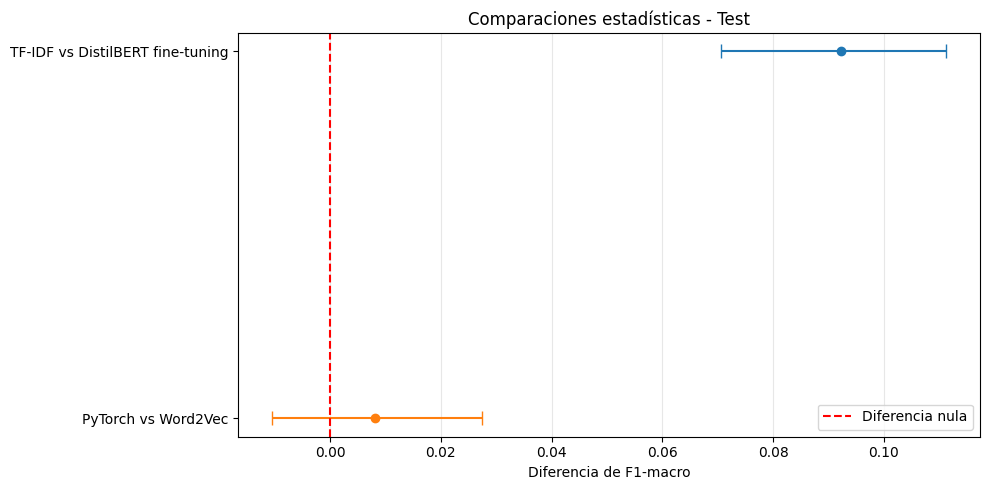

Gráfica estadística guardada correctamente


In [ ]:
# 118. GRAFICA DE LAS COMPARACIONES ESTADISTICAS

import pandas as pd
import matplotlib.pyplot as plt

# Recuperamos los resultados guardados.
comparacion_1 = pd.read_csv(
    carpeta_resultados / "comparacion_estadistica_modelos.csv"
)

comparacion_2 = pd.read_csv(
    carpeta_resultados / "comparacion_estadistica_pytorch_word2vec.csv"
)

# Unimos las dos comparaciones.
comparaciones = pd.concat(
    [comparacion_1, comparacion_2],
    ignore_index=True
)

# Creamos la gráfica.
fig, ax = plt.subplots(figsize=(10, 5))

for i, fila in comparaciones.iterrows():

    diferencia = fila["diferencia_f1"]

    # Distancias desde la diferencia hasta los límites.
    error_inferior = diferencia - fila["limite_inferior"]
    error_superior = fila["limite_superior"] - diferencia

    # Dibujamos la diferencia y su intervalo.
    ax.errorbar(
        diferencia,
        i,
        xerr=[[error_inferior], [error_superior]],
        fmt="o",
        capsize=5
    )

# Creamos los nombres de las comparaciones.
nombres = [
    "TF-IDF vs DistilBERT fine-tuning",
    "PyTorch vs Word2Vec"
]

ax.set_yticks(range(len(nombres)))
ax.set_yticklabels(nombres)
ax.invert_yaxis()

# Marcamos el valor cero.
ax.axvline(
    0,
    color="red",
    linestyle="--",
    label="Diferencia nula"
)

ax.set_xlabel("Diferencia de F1-macro")
ax.set_title("Comparaciones estadísticas - Test")

ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

# Guardamos la gráfica.
plt.savefig(
    carpeta_resultados / "comparaciones_estadisticas.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Gráfica estadística guardada correctamente")

In [ ]:
# 119. COPIA DE SEGURIDAD DE LA EVALUACION FINAL

import zipfile
from pathlib import Path
from google.colab import files

# Indicamos dónde guardaremos la copia.
ruta_respaldo = Path(
    "/content/respaldo_evaluacion_final.zip"
)

# Comprobamos que existen los resultados más importantes.
archivos_importantes = [
    "comparacion_final_validacion_test.csv",
    "comparaciones_estadisticas.png",
    "resultados_tfidf_test.csv",
    "resultados_word2vec_test.csv",
    "resultados_distilbert_svm_test.csv",
    "resultados_red_pytorch_test.csv",
    "resultados_finetuning_test.csv"
]

for nombre in archivos_importantes:
    assert (carpeta_resultados / nombre).exists(), nombre

# Comprobamos que el modelo fine-tuning está guardado.
carpeta_modelo = carpeta_resultados / "modelo_distilbert_finetuning"

assert (carpeta_modelo / "config.json").exists()
assert any(carpeta_modelo.glob("*.safetensors"))

# Comprimimos todos los resultados.
total_archivos = 0

with zipfile.ZipFile(
    ruta_respaldo,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archivo_zip:

    for ruta in carpeta_resultados.rglob("*"):

        if not ruta.is_file():
            continue

        ruta_relativa = ruta.relative_to(carpeta_resultados)

        # Excluimos los checkpoints intermedios de Hugging Face.
        if ruta_relativa.parts[0] == "finetuning_distilbert":
            continue

        archivo_zip.write(ruta, arcname=str(ruta_relativa))
        total_archivos += 1

# Comprobamos el archivo creado.
tamano_mb = ruta_respaldo.stat().st_size / (1024 * 1024)

print("Copia de seguridad creada correctamente")
print("Archivo:", ruta_respaldo.name)
print(f"Tamaño: {tamano_mb:.2f} MB")
print("Archivos guardados:", total_archivos)

# Descargamos el ZIP.
files.download(str(ruta_respaldo))

Copia de seguridad creada correctamente
Archivo: respaldo_evaluacion_final.zip
Tamaño: 407.59 MB
Archivos guardados: 93


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# 120a. RECUPERAR LOS RESULTADOS DEL PROYECTO

from pathlib import Path
import zipfile

# Indicamos dónde están los archivos.
ruta_zip = Path("/content/respaldo_evaluacion_final.zip")
carpeta_resultados = Path("/content/resultados")

# Creamos la carpeta si todavía no existe.
carpeta_resultados.mkdir(exist_ok=True)

# Recuperamos los resultados anteriores.
with zipfile.ZipFile(ruta_zip, "r") as archivo:
    archivo.extractall(carpeta_resultados)

# Comprobamos los archivos recuperados.
total_archivos = sum(
    1 for archivo in carpeta_resultados.rglob("*")
    if archivo.is_file()
)

print("Resultados recuperados correctamente")
print("Archivos recuperados:", total_archivos)

# Comprobamos algunos archivos importantes.
print("\nCOMPROBACIONES")

archivos_importantes = [
    "particiones.csv",
    "comparacion_final_validacion_test.csv",
    "resultados_tfidf_test.csv",
    "resultados_finetuning_test.csv"
]

for nombre in archivos_importantes:
    print(nombre, ":",
          (carpeta_resultados / nombre).exists())

Resultados recuperados correctamente
Archivos recuperados: 93

COMPROBACIONES
particiones.csv : True
comparacion_final_validacion_test.csv : True
resultados_tfidf_test.csv : True
resultados_finetuning_test.csv : True


In [5]:
# 120b. RECUPERAR LAS VARIABLES DEL PROYECTO

import pandas as pd
from pathlib import Path

# Recuperamos las carpetas de trabajo.
carpeta_datos = Path("/content/datos")
carpeta_resultados = Path("/content/resultados")

# Leemos las particiones originales del proyecto.
particiones = pd.read_csv(
    carpeta_resultados / "particiones.csv"
)

# Recuperamos los datos originales y sus metadatos.
columnas = [
    "projectID",
    "summary",
    "totalCost",
    "ecMaxContribution",
    "startDate",
    "endDate",
    "coordinatorCountry",
    "countryContr"
]

proyectos = pd.read_excel(
    carpeta_datos / "projects.xlsx",
    usecols=columnas
)

# Unimos los proyectos con sus categorías y particiones.
datos = particiones.merge(
    proyectos,
    on="projectID",
    how="left",
    validate="one_to_one"
)

# Recuperamos los tres conjuntos originales.
datos_train = datos[
    datos["particion"] == "entrenamiento"
].copy()

datos_val = datos[
    datos["particion"] == "validacion"
].copy()

datos_test = datos[
    datos["particion"] == "prueba"
].copy()

# Comprobamos que hemos recuperado todos los proyectos.
assert len(datos) == 31982
assert len(datos_train) == 19188
assert len(datos_val) == 6397
assert len(datos_test) == 6397
assert datos["summary"].notna().all()

# Comprobamos las categorías.
assert datos["nivel_1"].nunique() == 6
assert datos["nivel_2"].nunique() == 39

# Mostramos los resultados.
print("DATOS RECUPERADOS CORRECTAMENTE")

print("Proyectos totales:", len(datos))
print("Entrenamiento:", len(datos_train))
print("Validación:", len(datos_val))
print("Prueba:", len(datos_test))

print("\nCategorías de nivel 1:", datos["nivel_1"].nunique())
print("Categorías de nivel 2:", datos["nivel_2"].nunique())

print("\nMetadatos recuperados:")
print(datos[columnas].dtypes)

print("\nVariables preparadas correctamente")

DATOS RECUPERADOS CORRECTAMENTE
Proyectos totales: 31982
Entrenamiento: 19188
Validación: 6397
Prueba: 6397

Categorías de nivel 1: 6
Categorías de nivel 2: 39

Metadatos recuperados:
projectID                      int64
summary                       object
totalCost                    float64
ecMaxContribution            float64
startDate             datetime64[ns]
endDate               datetime64[ns]
coordinatorCountry            object
countryContr                  object
dtype: object

Variables preparadas correctamente


In [6]:
#EXTENSIÓN
# 121. ANALIZAR LOS METADATOS DE LOS PROYECTOS

import pandas as pd

# Seleccionamos las variables que utilizaremos.
columnas_metadatos = [
    "totalCost",
    "ecMaxContribution",
    "startDate",
    "endDate",
    "coordinatorCountry",
    "countryContr"
]

# Contamos los valores ausentes.
tabla_ausentes = pd.DataFrame({
    "variable": columnas_metadatos,
    "valores_ausentes": [
        datos[columna].isna().sum()
        for columna in columnas_metadatos
    ]
})

# Calculamos el porcentaje de valores ausentes.
tabla_ausentes["porcentaje"] = (
    100 * tabla_ausentes["valores_ausentes"] / len(datos)
)

print("VALORES AUSENTES EN LOS METADATOS")
print(tabla_ausentes.to_string(index=False))

# Comprobamos los costes y la financiación.
print("\nESTADISTICAS DE LOS DATOS ECONOMICOS")
print(
    datos[["totalCost", "ecMaxContribution"]].describe()
)

# Comprobamos algunos ejemplos de países coordinadores.
print("\nEJEMPLOS DE PAISES COORDINADORES")
print(datos["coordinatorCountry"].dropna().head(5).tolist())

# Comprobamos cómo se guarda la financiación por países.
print("\nEJEMPLOS DE COUNTRYCONTR")

for valor in datos["countryContr"].dropna().head(3):
    print(str(valor)[:200])

print("\nAnálisis de metadatos completado")

VALORES AUSENTES EN LOS METADATOS
          variable  valores_ausentes  porcentaje
         totalCost                 0    0.000000
 ecMaxContribution                 0    0.000000
         startDate                11    0.034394
           endDate                11    0.034394
coordinatorCountry                 0    0.000000
      countryContr                 0    0.000000

ESTADISTICAS DE LOS DATOS ECONOMICOS
          totalCost  ecMaxContribution
count  3.198200e+04       3.198200e+04
mean   2.329257e+06       1.915116e+06
std    9.910579e+06       5.611197e+06
min    0.000000e+00       3.150000e+03
25%    1.714733e+05       1.714733e+05
50%    9.577945e+05       8.927629e+05
75%    2.496358e+06       2.336200e+06
max    1.329689e+09       6.788000e+08

EJEMPLOS DE PAISES COORDINADORES
['SE', 'NL', 'PT', 'UK', 'ES']

EJEMPLOS DE COUNTRYCONTR
BE|318125.0 DE|175000.0 DK|520875.0 FI|261250.0 FR|835230.0 IT|760078.0 SE|623666.0 SN|216250.0 UK|590461.0
BE|475092.0 CH|0.0 CZ|300000.0 DE|5

In [7]:
# 122. CREAR LAS VARIABLES DE DURACION Y NUMERO DE PAISES

import pandas as pd

# Calculamos la duración de cada proyecto en días.
datos["duracion_dias"] = (
    datos["endDate"] - datos["startDate"]
).dt.days


# Esta función cuenta los países de cada proyecto.
def contar_paises(valor):

    # Si no hay información, devolvemos un valor ausente.
    if pd.isna(valor) or str(valor).strip() == "":
        return None

    # Cada país aparece con el formato CODIGO|CONTRIBUCION.
    paises = str(valor).split()

    return sum(1 for pais in paises if "|" in pais)


# Calculamos el número de países participantes.
datos["numero_paises"] = datos["countryContr"].apply(
    contar_paises
)


# Mostramos algunos resultados.
print("EJEMPLOS DE LAS NUEVAS VARIABLES")

print(
    datos[
        ["projectID", "duracion_dias", "numero_paises"]
    ].head(10).to_string(index=False)
)


# Comprobamos los valores ausentes.
print("\nVALORES AUSENTES")

print("Duración:",
      datos["duracion_dias"].isna().sum())

print("Número de países:",
      datos["numero_paises"].isna().sum())


# Comprobamos posibles valores problemáticos.
print("\nCOMPROBACIONES")

print("Duraciones negativas:",
      (datos["duracion_dias"] < 0).sum())

print("Proyectos con cero países:",
      (datos["numero_paises"] == 0).sum())


# Mostramos algunas estadísticas.
print("\nESTADISTICAS")

print(
    datos[
        ["duracion_dias", "numero_paises"]
    ].describe()
)

print("\nVariables creadas correctamente")

EJEMPLOS DE LAS NUEVAS VARIABLES
 projectID  duracion_dias  numero_paises
    115843         1095.0              9
    115910         2374.0             10
    635266         1095.0              8
    637488         2008.0              1
    639226         2040.0              1
    640254         1826.0              1
    642935         1460.0              4
    643002         1583.0              4
    643937         1095.0              6
    645198         1276.0              8

VALORES AUSENTES
Duración: 11
Número de países: 0

COMPROBACIONES
Duraciones negativas: 0
Proyectos con cero países: 0

ESTADISTICAS
       duracion_dias  numero_paises
count   31971.000000   31982.000000
mean     1084.532795       2.800700
std       605.150967       3.367543
min        30.000000       1.000000
25%       729.000000       1.000000
50%      1002.000000       1.000000
75%      1641.000000       4.000000
max      3468.000000      39.000000

Variables creadas correctamente


In [8]:
# 123. PREPARAR LOS METADATOS PARA LA CLASIFICACION

# Seleccionamos las variables de nuestra extensión.
columnas_extension = [
    "totalCost",
    "ecMaxContribution",
    "duracion_dias",
    "numero_paises",
    "coordinatorCountry"
]

# Recuperamos las particiones con las nuevas variables.
datos_train_ext = datos[
    datos["particion"] == "entrenamiento"
].copy()

datos_val_ext = datos[
    datos["particion"] == "validacion"
].copy()

# Preparamos los metadatos de entrenamiento y validación.
X_train_meta = datos_train_ext[columnas_extension].copy()

X_val_meta = datos_val_ext[columnas_extension].copy()

# Recuperamos las categorías de nivel 2.
y_train_meta = datos_train_ext["nivel_2"].to_numpy()

y_val_meta = datos_val_ext["nivel_2"].to_numpy()

# Comprobamos los tamaños.
print("METADATOS PREPARADOS")

print("Entrenamiento:", X_train_meta.shape)
print("Validación:", X_val_meta.shape)

print("\nCategorías:", len(set(y_train_meta)))

# Comprobamos los valores ausentes.
print("\nVALORES AUSENTES EN ENTRENAMIENTO")
print(X_train_meta.isna().sum())

print("\nVALORES AUSENTES EN VALIDACION")
print(X_val_meta.isna().sum())

# Verificamos que coinciden los proyectos y etiquetas.
assert len(X_train_meta) == len(y_train_meta)
assert len(X_val_meta) == len(y_val_meta)

print("\nDatos preparados correctamente")

METADATOS PREPARADOS
Entrenamiento: (19188, 5)
Validación: (6397, 5)

Categorías: 39

VALORES AUSENTES EN ENTRENAMIENTO
totalCost             0
ecMaxContribution     0
duracion_dias         3
numero_paises         0
coordinatorCountry    0
dtype: int64

VALORES AUSENTES EN VALIDACION
totalCost             0
ecMaxContribution     0
duracion_dias         4
numero_paises         0
coordinatorCountry    0
dtype: int64

Datos preparados correctamente


In [9]:
# 124. TRANSFORMAR LOS METADATOS PARA EL SVM

import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)

# Seleccionamos las variables numéricas.
columnas_numericas = [
    "totalCost",
    "ecMaxContribution",
    "duracion_dias",
    "numero_paises"
]

# Preparamos las variables numéricas.
transformacion_numerica = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("logaritmo", FunctionTransformer(np.log1p)),
    ("escalar", StandardScaler())
])

# Preparamos el país coordinador.
transformacion_pais = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Unimos las transformaciones.
preprocesador_meta = ColumnTransformer([
    ("numericas", transformacion_numerica, columnas_numericas),
    ("pais", transformacion_pais, ["coordinatorCountry"])
])

# Ajustamos las transformaciones solo con entrenamiento.
X_train_meta_preparado = preprocesador_meta.fit_transform(
    X_train_meta
)

# Aplicamos las mismas transformaciones a validación.
X_val_meta_preparado = preprocesador_meta.transform(
    X_val_meta
)

# Comprobamos los resultados.
print("METADATOS TRANSFORMADOS")

print("Entrenamiento:", X_train_meta_preparado.shape)
print("Validación:", X_val_meta_preparado.shape)

print("\nCaracterísticas finales:",
      X_train_meta_preparado.shape[1])

print("\nTransformaciones completadas correctamente")

METADATOS TRANSFORMADOS
Entrenamiento: (19188, 57)
Validación: (6397, 57)

Características finales: 57

Transformaciones completadas correctamente


In [10]:
# 125. ENTRENAR UN SVM UTILIZANDO SOLO METADATOS

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
from time import perf_counter
import pandas as pd
import joblib

# Creamos el clasificador SVM.
modelo_svm_meta = LinearSVC(
    C=1.0,
    class_weight="balanced",
    dual="auto",
    max_iter=5000,
    random_state=42
)

# Entrenamos con los metadatos de entrenamiento.
print("Entrenando SVM con metadatos...")

inicio = perf_counter()

modelo_svm_meta.fit(
    X_train_meta_preparado,
    y_train_meta
)

tiempo_meta = perf_counter() - inicio

# Realizamos predicciones sobre validación.
pred_meta_val = modelo_svm_meta.predict(
    X_val_meta_preparado
)

# Calculamos las métricas.
accuracy_meta_val = accuracy_score(
    y_val_meta,
    pred_meta_val
)

f1_meta_val = f1_score(
    y_val_meta,
    pred_meta_val,
    labels=sorted(set(y_train_meta)),
    average="macro",
    zero_division=0
)

# Mostramos los resultados.
print("\nRESULTADOS DEL SVM CON METADATOS")

print("Categorías:", len(modelo_svm_meta.classes_))
print(f"Accuracy en validación: {accuracy_meta_val:.2%}")
print(f"F1-macro en validación: {f1_meta_val:.4f}")
print(f"Tiempo de entrenamiento: {tiempo_meta:.1f} segundos")

# Guardamos el preprocesador y el clasificador juntos.
joblib.dump(
    {
        "preprocesador": preprocesador_meta,
        "clasificador": modelo_svm_meta,
        "columnas": columnas_extension
    },
    carpeta_resultados / "modelo_svm_metadatos_inicial.joblib"
)

# Guardamos las métricas.
resultados_meta = pd.DataFrame([{
    "modelo": "SVM solo metadatos",
    "conjunto": "validacion",
    "C": 1.0,
    "class_weight": "balanced",
    "accuracy": accuracy_meta_val,
    "f1_macro": f1_meta_val,
    "tiempo_s": tiempo_meta
}])

resultados_meta.to_csv(
    carpeta_resultados / "resultados_metadatos_inicial.csv",
    index=False
)

print("\nModelo y resultados guardados correctamente")

Entrenando SVM con metadatos...

RESULTADOS DEL SVM CON METADATOS
Categorías: 39
Accuracy en validación: 1.45%
F1-macro en validación: 0.0111
Tiempo de entrenamiento: 4.2 segundos

Modelo y resultados guardados correctamente


In [11]:
# 126. PROBAR SVM CON METADATOS SIN PESOS BALANCEADOS

# Creamos el modelo sin pesos balanceados.
modelo_meta_sin_pesos = LinearSVC(
    C=1.0,
    class_weight=None,
    dual="auto",
    max_iter=5000,
    random_state=42
)

# Entrenamos utilizando los mismos metadatos.
print("Entrenando SVM sin pesos balanceados...")

inicio = perf_counter()

modelo_meta_sin_pesos.fit(
    X_train_meta_preparado,
    y_train_meta
)

tiempo_meta_sin_pesos = perf_counter() - inicio

# Realizamos predicciones sobre validación.
pred_meta_sin_pesos = modelo_meta_sin_pesos.predict(
    X_val_meta_preparado
)

# Calculamos las métricas.
accuracy_meta_sin_pesos = accuracy_score(
    y_val_meta,
    pred_meta_sin_pesos
)

f1_meta_sin_pesos = f1_score(
    y_val_meta,
    pred_meta_sin_pesos,
    labels=sorted(set(y_train_meta)),
    average="macro",
    zero_division=0
)

# Comparamos las dos configuraciones.
print("\nCOMPARACION DE LOS MODELOS CON METADATOS")

tabla_comparacion_meta = pd.DataFrame([
    {
        "class_weight": "balanced",
        "accuracy": accuracy_meta_val,
        "f1_macro": f1_meta_val
    },
    {
        "class_weight": "None",
        "accuracy": accuracy_meta_sin_pesos,
        "f1_macro": f1_meta_sin_pesos
    }
])

print(tabla_comparacion_meta.to_string(index=False))

# Comprobamos cuántas categorías predice el nuevo modelo.
print("\nCategorias predichas:",
      len(set(pred_meta_sin_pesos)))

print(f"Tiempo de entrenamiento: {tiempo_meta_sin_pesos:.1f} segundos")

# Guardamos el nuevo modelo.
joblib.dump(
    {
        "preprocesador": preprocesador_meta,
        "clasificador": modelo_meta_sin_pesos,
        "columnas": columnas_extension
    },
    carpeta_resultados / "modelo_svm_metadatos_sin_pesos.joblib"
)

# Guardamos la comparación.
tabla_comparacion_meta.to_csv(
    carpeta_resultados / "comparacion_svm_metadatos.csv",
    index=False
)

print("\nModelo y comparación guardados correctamente")

Entrenando SVM sin pesos balanceados...

COMPARACION DE LOS MODELOS CON METADATOS
class_weight  accuracy  f1_macro
    balanced  0.014538  0.011113
        None  0.146631  0.022277

Categorias predichas: 10
Tiempo de entrenamiento: 7.0 segundos

Modelo y comparación guardados correctamente


In [12]:
# 127. RECUPERAR EL MODELO TF-IDF Y LOS TEXTOS PROCESADOS

import joblib
import pandas as pd
import numpy as np

# Recuperamos el modelo de texto que ya entrenamos.
modelo_texto_guardado = joblib.load(
    carpeta_resultados / "modelo_tfidf_svm.joblib"
)

# Recuperamos los textos procesados de validación.
textos_val = pd.read_csv(
    carpeta_resultados / "validacion_procesada.csv"
)

# Comprobamos el contenido.
print("MODELO TF-IDF RECUPERADO")

print("Elementos guardados:",
      list(modelo_texto_guardado.keys()))

print("\nTEXTOS DE VALIDACION")

print("Proyectos con texto:", len(textos_val))
print("Proyectos en validación:", len(datos_val_ext))

print("\nColumnas disponibles:")
print(textos_val.columns.tolist())

# Comprobamos que corresponden a los mismos proyectos.
mismos_proyectos = (
    set(textos_val["projectID"]) ==
    set(datos_val_ext["projectID"])
)

print("\n¿Son los mismos proyectos?:", mismos_proyectos)

# Comprobamos si están en el mismo orden.
mismo_orden = np.array_equal(
    textos_val["projectID"].to_numpy(),
    datos_val_ext["projectID"].to_numpy()
)

print("¿Están en el mismo orden?:", mismo_orden)

# Comprobamos los textos ausentes.
print("\nTextos ausentes:",
      textos_val["texto_limpio"].isna().sum())

print("\nComprobación terminada")

MODELO TF-IDF RECUPERADO
Elementos guardados: ['vectorizador', 'clasificador', 'clases_nivel2', 'semilla']

TEXTOS DE VALIDACION
Proyectos con texto: 6397
Proyectos en validación: 6397

Columnas disponibles:
['projectID', 'texto_limpio']

¿Son los mismos proyectos?: True
¿Están en el mismo orden?: True

Textos ausentes: 1

Comprobación terminada


In [13]:
# 128. RECUPERAR LOS VECTORES TF-IDF DE ENTRENAMIENTO Y VALIDACION

import pandas as pd
import numpy as np

# Recuperamos los textos procesados de entrenamiento.
textos_train = pd.read_csv(
    carpeta_resultados / "entrenamiento_procesado.csv"
)

# Comprobamos que todos los proyectos están presentes.
assert len(textos_train) == len(datos_train_ext)
assert textos_train["projectID"].is_unique
assert textos_val["projectID"].is_unique

assert set(textos_train["projectID"]) == set(datos_train_ext["projectID"])
assert set(textos_val["projectID"]) == set(datos_val_ext["projectID"])

# Ordenamos los textos para que coincidan con los metadatos.
texto_train_ordenado = (
    textos_train
    .set_index("projectID")
    .loc[datos_train_ext["projectID"], "texto_limpio"]
    .fillna("")
)

texto_val_ordenado = (
    textos_val
    .set_index("projectID")
    .loc[datos_val_ext["projectID"], "texto_limpio"]
    .fillna("")
)

# Recuperamos el vectorizador TF-IDF ya entrenado.
vectorizador_tfidf = modelo_texto_guardado["vectorizador"]

# Transformamos los textos sin volver a entrenar el vectorizador.
X_train_texto = vectorizador_tfidf.transform(
    texto_train_ordenado
)

X_val_texto = vectorizador_tfidf.transform(
    texto_val_ordenado
)

# Comprobamos los resultados.
print("VECTORES TF-IDF RECUPERADOS")

print("Entrenamiento:", X_train_texto.shape)
print("Validación:", X_val_texto.shape)

print("\nTextos vacíos en entrenamiento:",
      (texto_train_ordenado == "").sum())

print("Textos vacíos en validación:",
      (texto_val_ordenado == "").sum())

# Verificamos que los tamaños son correctos.
assert X_train_texto.shape[0] == 19188
assert X_val_texto.shape[0] == 6397

print("\nVectores recuperados correctamente")

VECTORES TF-IDF RECUPERADOS
Entrenamiento: (19188, 50000)
Validación: (6397, 50000)

Textos vacíos en entrenamiento: 0
Textos vacíos en validación: 1

Vectores recuperados correctamente


In [14]:
# 129. COMBINAR LAS CARACTERISTICAS DE TEXTO Y METADATOS

from scipy.sparse import hstack, csr_matrix

# Convertimos los metadatos a formato disperso.
# Este formato permite trabajar con muchas columnas sin gastar tanta memoria.
X_train_meta_sparse = csr_matrix(X_train_meta_preparado)
X_val_meta_sparse = csr_matrix(X_val_meta_preparado)

# Unimos las características TF-IDF y los metadatos.
X_train_combinado = hstack(
    [X_train_texto, X_train_meta_sparse],
    format="csr"
)

X_val_combinado = hstack(
    [X_val_texto, X_val_meta_sparse],
    format="csr"
)

# Comprobamos las dimensiones.
print("CARACTERISTICAS COMBINADAS")

print("Entrenamiento:", X_train_combinado.shape)
print("Validación:", X_val_combinado.shape)

print("\nCaracterísticas de texto:", X_train_texto.shape[1])
print("Características de metadatos:", X_train_meta_sparse.shape[1])
print("Características totales:", X_train_combinado.shape[1])

# Verificamos que todas las dimensiones coinciden.
assert X_train_combinado.shape == (19188, 50057)
assert X_val_combinado.shape == (6397, 50057)

print("\nTexto y metadatos combinados correctamente")

CARACTERISTICAS COMBINADAS
Entrenamiento: (19188, 50057)
Validación: (6397, 50057)

Características de texto: 50000
Características de metadatos: 57
Características totales: 50057

Texto y metadatos combinados correctamente


In [15]:
# 130. ENTRENAR EL SVM CON TEXTO Y METADATOS

from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
from time import perf_counter
import pandas as pd
import joblib

# Recuperamos el clasificador original de texto.
modelo_svm_texto = modelo_texto_guardado["clasificador"]

# Creamos otro SVM con la misma configuración.
# Así podemos comparar el efecto de añadir metadatos.
modelo_svm_combinado = clone(modelo_svm_texto)

print("Entrenando SVM con texto y metadatos...")

inicio = perf_counter()

# Entrenamos con las características combinadas.
modelo_svm_combinado.fit(
    X_train_combinado,
    y_train_meta
)

tiempo_combinado = perf_counter() - inicio

# Realizamos predicciones sobre validación.
pred_combinado_val = modelo_svm_combinado.predict(
    X_val_combinado
)

# Calculamos las métricas del modelo combinado.
accuracy_combinado_val = accuracy_score(
    y_val_meta,
    pred_combinado_val
)

f1_combinado_val = f1_score(
    y_val_meta,
    pred_combinado_val,
    average="macro",
    zero_division=0
)

# Evaluamos también el modelo original de texto.
pred_texto_val = modelo_svm_texto.predict(
    X_val_texto
)

accuracy_texto_val = accuracy_score(
    y_val_meta,
    pred_texto_val
)

f1_texto_val = f1_score(
    y_val_meta,
    pred_texto_val,
    average="macro",
    zero_division=0
)

# Creamos una tabla comparativa.
comparacion_extension = pd.DataFrame([
    {
        "modelo": "Solo texto",
        "accuracy": accuracy_texto_val,
        "f1_macro": f1_texto_val
    },
    {
        "modelo": "Solo metadatos",
        "accuracy": accuracy_meta_sin_pesos,
        "f1_macro": f1_meta_sin_pesos
    },
    {
        "modelo": "Texto + metadatos",
        "accuracy": accuracy_combinado_val,
        "f1_macro": f1_combinado_val
    }
])

print("\nCOMPARACION EN VALIDACION")
print(comparacion_extension.to_string(index=False))

print("\nTiempo de entrenamiento:",
      round(tiempo_combinado, 1), "segundos")

print("Categorias del modelo:",
      len(modelo_svm_combinado.classes_))

# Guardamos el modelo combinado y sus transformaciones.
joblib.dump(
    {
        "clasificador": modelo_svm_combinado,
        "vectorizador": vectorizador_tfidf,
        "preprocesador_metadatos": preprocesador_meta,
        "columnas_metadatos": columnas_extension
    },
    carpeta_resultados / "modelo_svm_texto_metadatos_inicial.joblib"
)

# Guardamos los resultados de la comparación.
comparacion_extension.to_csv(
    carpeta_resultados / "comparacion_extension_validacion.csv",
    index=False
)

print("\nModelo y resultados guardados correctamente")

Entrenando SVM con texto y metadatos...

COMPARACION EN VALIDACION
           modelo  accuracy  f1_macro
       Solo texto  0.537127  0.412706
   Solo metadatos  0.146631  0.022277
Texto + metadatos  0.530874  0.400182

Tiempo de entrenamiento: 64.4 segundos
Categorias del modelo: 39

Modelo y resultados guardados correctamente


In [16]:
# 131. PROBAR EL MODELO COMBINADO CON MENOR PESO DE METADATOS

from scipy.sparse import hstack
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
from time import perf_counter
import pandas as pd
import joblib

# Reducimos la influencia de los metadatos.
peso_metadatos = 0.1

# Combinamos el texto con los metadatos ponderados.
X_train_combinado_01 = hstack(
    [
        X_train_texto,
        X_train_meta_sparse * peso_metadatos
    ],
    format="csr"
)

X_val_combinado_01 = hstack(
    [
        X_val_texto,
        X_val_meta_sparse * peso_metadatos
    ],
    format="csr"
)

# Creamos un SVM con los parámetros originales.
modelo_combinado_01 = clone(modelo_svm_texto)

print("Entrenando SVM con peso de metadatos 0.1...")

inicio = perf_counter()

modelo_combinado_01.fit(
    X_train_combinado_01,
    y_train_meta
)

tiempo_combinado_01 = perf_counter() - inicio

# Realizamos las predicciones.
pred_combinado_01 = modelo_combinado_01.predict(
    X_val_combinado_01
)

# Calculamos las métricas.
accuracy_combinado_01 = accuracy_score(
    y_val_meta,
    pred_combinado_01
)

f1_combinado_01 = f1_score(
    y_val_meta,
    pred_combinado_01,
    average="macro",
    zero_division=0
)

# Comparamos los resultados.
tabla_pesos = pd.DataFrame([
    {
        "modelo": "Solo texto",
        "accuracy": accuracy_texto_val,
        "f1_macro": f1_texto_val
    },
    {
        "modelo": "Texto + metadatos (peso 1.0)",
        "accuracy": accuracy_combinado_val,
        "f1_macro": f1_combinado_val
    },
    {
        "modelo": "Texto + metadatos (peso 0.1)",
        "accuracy": accuracy_combinado_01,
        "f1_macro": f1_combinado_01
    }
])

print("\nCOMPARACION DE RESULTADOS")
print(tabla_pesos.to_string(index=False))

print("\nTiempo de entrenamiento:",
      round(tiempo_combinado_01, 1), "segundos")

# Guardamos el nuevo modelo y las transformaciones.
joblib.dump(
    {
        "clasificador": modelo_combinado_01,
        "vectorizador": vectorizador_tfidf,
        "preprocesador_metadatos": preprocesador_meta,
        "columnas_metadatos": columnas_extension,
        "peso_metadatos": peso_metadatos
    },
    carpeta_resultados / "modelo_svm_combinado_peso_01.joblib"
)

# Guardamos la comparación.
tabla_pesos.to_csv(
    carpeta_resultados / "comparacion_pesos_metadatos.csv",
    index=False
)

print("\nModelo y resultados guardados correctamente")

Entrenando SVM con peso de metadatos 0.1...

COMPARACION DE RESULTADOS
                      modelo  accuracy  f1_macro
                  Solo texto  0.537127  0.412706
Texto + metadatos (peso 1.0)  0.530874  0.400182
Texto + metadatos (peso 0.1)  0.533531  0.401366

Tiempo de entrenamiento: 16.3 segundos

Modelo y resultados guardados correctamente


In [17]:
# 132. PROBAR EL MODELO COMBINADO CON PESO 0.01

from scipy.sparse import hstack
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
from time import perf_counter
import pandas as pd
import joblib

# Reducimos todavía más la influencia de los metadatos.
peso_metadatos_001 = 0.01

# Combinamos texto y metadatos con el nuevo peso.
X_train_combinado_001 = hstack(
    [
        X_train_texto,
        X_train_meta_sparse * peso_metadatos_001
    ],
    format="csr"
)

X_val_combinado_001 = hstack(
    [
        X_val_texto,
        X_val_meta_sparse * peso_metadatos_001
    ],
    format="csr"
)

# Creamos el SVM con la configuración original.
modelo_combinado_001 = clone(modelo_svm_texto)

print("Entrenando SVM con peso de metadatos 0.01...")

inicio = perf_counter()

modelo_combinado_001.fit(
    X_train_combinado_001,
    y_train_meta
)

tiempo_combinado_001 = perf_counter() - inicio

# Predecimos las categorías de validación.
pred_combinado_001 = modelo_combinado_001.predict(
    X_val_combinado_001
)

# Calculamos las métricas.
accuracy_combinado_001 = accuracy_score(
    y_val_meta,
    pred_combinado_001
)

f1_combinado_001 = f1_score(
    y_val_meta,
    pred_combinado_001,
    average="macro",
    zero_division=0
)

# Comparamos todas las configuraciones probadas.
tabla_pesos_final = pd.DataFrame([
    {
        "modelo": "Solo texto",
        "accuracy": accuracy_texto_val,
        "f1_macro": f1_texto_val
    },
    {
        "modelo": "Texto + metadatos (peso 1.0)",
        "accuracy": accuracy_combinado_val,
        "f1_macro": f1_combinado_val
    },
    {
        "modelo": "Texto + metadatos (peso 0.1)",
        "accuracy": accuracy_combinado_01,
        "f1_macro": f1_combinado_01
    },
    {
        "modelo": "Texto + metadatos (peso 0.01)",
        "accuracy": accuracy_combinado_001,
        "f1_macro": f1_combinado_001
    }
])

print("\nCOMPARACION FINAL DE PESOS")
print(tabla_pesos_final.to_string(index=False))

print("\nTiempo de entrenamiento:",
      round(tiempo_combinado_001, 1), "segundos")

# Guardamos el modelo y sus transformaciones.
joblib.dump(
    {
        "clasificador": modelo_combinado_001,
        "vectorizador": vectorizador_tfidf,
        "preprocesador_metadatos": preprocesador_meta,
        "columnas_metadatos": columnas_extension,
        "peso_metadatos": peso_metadatos_001
    },
    carpeta_resultados / "modelo_svm_combinado_peso_001.joblib"
)

# Guardamos la comparación.
tabla_pesos_final.to_csv(
    carpeta_resultados / "comparacion_final_pesos_extension.csv",
    index=False
)

print("\nModelo y comparación guardados correctamente")

Entrenando SVM con peso de metadatos 0.01...

COMPARACION FINAL DE PESOS
                       modelo  accuracy  f1_macro
                   Solo texto  0.537127  0.412706
 Texto + metadatos (peso 1.0)  0.530874  0.400182
 Texto + metadatos (peso 0.1)  0.533531  0.401366
Texto + metadatos (peso 0.01)  0.536501  0.412349

Tiempo de entrenamiento: 11.7 segundos

Modelo y comparación guardados correctamente


In [18]:
# 133. PREPARAR EL CONJUNTO DE PRUEBA DE LA EXTENSION

import pandas as pd
from scipy.sparse import hstack, csr_matrix

# Recuperamos los proyectos de prueba.
datos_test_ext = datos[
    datos["particion"] == "prueba"
].copy()

# Seleccionamos los metadatos.
X_test_meta = datos_test_ext[columnas_extension].copy()

# Recuperamos las categorías verdaderas.
y_test_meta = datos_test_ext["nivel_2"].to_numpy()

# Transformamos los metadatos con el preprocesador ya entrenado.
X_test_meta_preparado = preprocesador_meta.transform(
    X_test_meta
)

# Recuperamos los textos procesados de prueba.
textos_test = pd.read_csv(
    carpeta_resultados / "prueba_procesada.csv"
)

# Comprobamos que los proyectos coinciden.
assert len(textos_test) == len(datos_test_ext)
assert textos_test["projectID"].is_unique
assert datos_test_ext["projectID"].is_unique

assert set(textos_test["projectID"]) == set(
    datos_test_ext["projectID"]
)

# Ordenamos los textos para que coincidan con los metadatos.
texto_test_ordenado = (
    textos_test
    .set_index("projectID")
    .loc[datos_test_ext["projectID"], "texto_limpio"]
    .fillna("")
)

# Convertimos los textos a TF-IDF sin entrenar de nuevo.
X_test_texto = vectorizador_tfidf.transform(
    texto_test_ordenado
)

# Convertimos los metadatos a formato disperso.
X_test_meta_sparse = csr_matrix(
    X_test_meta_preparado
)

# Combinamos texto y metadatos con el peso seleccionado.
X_test_combinado_001 = hstack(
    [
        X_test_texto,
        X_test_meta_sparse * 0.01
    ],
    format="csr"
)

# Comprobamos las dimensiones.
print("CONJUNTO DE PRUEBA PREPARADO")

print("Proyectos:", len(datos_test_ext))
print("Solo texto:", X_test_texto.shape)
print("Solo metadatos:", X_test_meta_preparado.shape)
print("Texto + metadatos:", X_test_combinado_001.shape)

print("\nTextos vacíos:",
      (texto_test_ordenado == "").sum())

print("Duraciones ausentes:",
      X_test_meta["duracion_dias"].isna().sum())

# Verificamos que las dimensiones son correctas.
assert X_test_texto.shape == (6397, 50000)
assert X_test_meta_preparado.shape == (6397, 57)
assert X_test_combinado_001.shape == (6397, 50057)

print("\nDatos de prueba preparados correctamente")

CONJUNTO DE PRUEBA PREPARADO
Proyectos: 6397
Solo texto: (6397, 50000)
Solo metadatos: (6397, 57)
Texto + metadatos: (6397, 50057)

Textos vacíos: 0
Duraciones ausentes: 4

Datos de prueba preparados correctamente


In [19]:
# 134. EVALUACION FINAL DE LA EXTENSION

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Realizamos las predicciones de los tres modelos.
pred_texto_test = modelo_svm_texto.predict(
    X_test_texto
)

pred_meta_test = modelo_meta_sin_pesos.predict(
    X_test_meta_preparado
)

pred_combinado_test = modelo_combinado_001.predict(
    X_test_combinado_001
)

# Calculamos las métricas de cada modelo.
resultados_extension_test = []

modelos = [
    ("Solo texto", pred_texto_test),
    ("Solo metadatos", pred_meta_test),
    ("Texto + metadatos", pred_combinado_test)
]

for nombre, predicciones in modelos:

    accuracy = accuracy_score(
        y_test_meta,
        predicciones
    )

    f1 = f1_score(
        y_test_meta,
        predicciones,
        average="macro",
        zero_division=0
    )

    resultados_extension_test.append({
        "modelo": nombre,
        "accuracy": accuracy,
        "f1_macro": f1
    })

# Mostramos la comparación final.
tabla_extension_test = pd.DataFrame(
    resultados_extension_test
)

print("RESULTADOS FINALES DE LA EXTENSION")
print(tabla_extension_test.to_string(index=False))

# Guardamos los resultados.
tabla_extension_test.to_csv(
    carpeta_resultados / "comparacion_extension_test.csv",
    index=False
)

# Guardamos las predicciones de cada proyecto.
predicciones_extension = pd.DataFrame({
    "projectID": datos_test_ext["projectID"].to_numpy(),
    "categoria_real": y_test_meta,
    "pred_texto": pred_texto_test,
    "pred_metadatos": pred_meta_test,
    "pred_combinado": pred_combinado_test
})

predicciones_extension.to_csv(
    carpeta_resultados / "predicciones_extension_test.csv",
    index=False
)

print("\nResultados y predicciones guardados correctamente")

RESULTADOS FINALES DE LA EXTENSION
           modelo  accuracy  f1_macro
       Solo texto  0.528060  0.407172
   Solo metadatos  0.147100  0.021359
Texto + metadatos  0.527591  0.406868

Resultados y predicciones guardados correctamente


In [20]:
# 135. COMPARAR LOS ERRORES DEL MODELO DE TEXTO Y EL COMBINADO

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# Comprobamos qué proyectos acierta cada modelo.
aciertos_texto = pred_texto_test == y_test_meta
aciertos_combinado = pred_combinado_test == y_test_meta

print("COMPARACION DE ACIERTOS")

print("Aciertos solo texto:", aciertos_texto.sum())
print("Aciertos texto + metadatos:", aciertos_combinado.sum())

# Contamos los casos en los que añadir metadatos ayuda o perjudica.
mejoras = (~aciertos_texto & aciertos_combinado).sum()
empeoramientos = (aciertos_texto & ~aciertos_combinado).sum()

print("\nProyectos que mejora el modelo combinado:", mejoras)
print("Proyectos que empeora el modelo combinado:", empeoramientos)

# Calculamos la diferencia de F1-macro.
diferencia_f1 = f1_combinado_001 - f1_texto_val

# Para la comparación final utilizamos los resultados de prueba.
f1_texto_test = f1_score(
    y_test_meta, pred_texto_test, average="macro", zero_division=0
)

f1_combinado_test = f1_score(
    y_test_meta, pred_combinado_test, average="macro", zero_division=0
)

diferencia_f1_test = f1_combinado_test - f1_texto_test

print("\nDiferencia de F1-macro en prueba:",
      round(diferencia_f1_test, 6))

# Estimamos la incertidumbre mediante bootstrap pareado.
rng = np.random.default_rng(42)
n_repeticiones = 1000
diferencias_bootstrap = []

clases = sorted(set(y_train_meta))

for _ in range(n_repeticiones):

    indices = rng.choice(
        len(y_test_meta),
        size=len(y_test_meta),
        replace=True
    )

    f1_texto = f1_score(
        y_test_meta[indices],
        pred_texto_test[indices],
        labels=clases,
        average="macro",
        zero_division=0
    )

    f1_combinado = f1_score(
        y_test_meta[indices],
        pred_combinado_test[indices],
        labels=clases,
        average="macro",
        zero_division=0
    )

    diferencias_bootstrap.append(
        f1_combinado - f1_texto
    )

# Calculamos el intervalo de confianza del 95 %.
limite_inferior, limite_superior = np.percentile(
    diferencias_bootstrap,
    [2.5, 97.5]
)

print("\nINTERVALO BOOTSTRAP DEL 95 %")

print(f"Límite inferior: {limite_inferior:.6f}")
print(f"Límite superior: {limite_superior:.6f}")

# Guardamos los resultados.
resumen_bootstrap = pd.DataFrame([{
    "diferencia_f1_test": diferencia_f1_test,
    "limite_inferior_95": limite_inferior,
    "limite_superior_95": limite_superior,
    "mejoras": mejoras,
    "empeoramientos": empeoramientos
}])

resumen_bootstrap.to_csv(
    carpeta_resultados / "bootstrap_extension.csv",
    index=False
)

print("\nAnálisis guardado correctamente")

COMPARACION DE ACIERTOS
Aciertos solo texto: 3378
Aciertos texto + metadatos: 3375

Proyectos que mejora el modelo combinado: 7
Proyectos que empeora el modelo combinado: 10

Diferencia de F1-macro en prueba: -0.000303

INTERVALO BOOTSTRAP DEL 95 %
Límite inferior: -0.001277
Límite superior: 0.000752

Análisis guardado correctamente


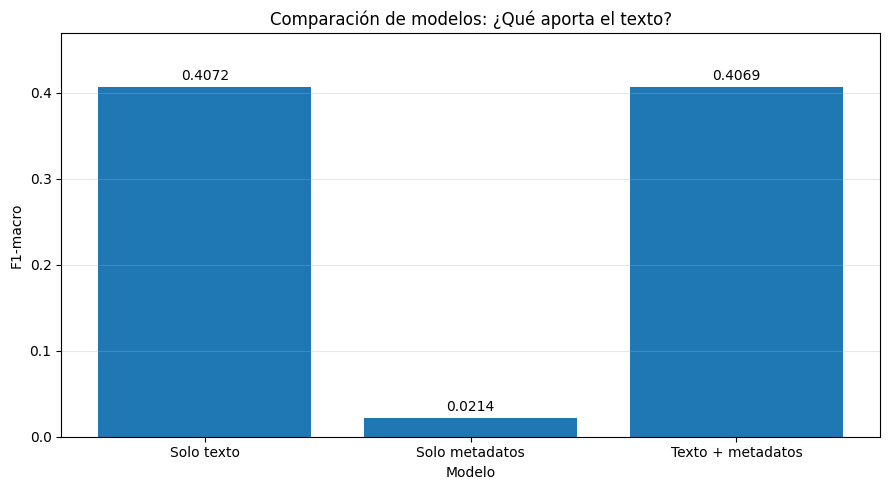

Gráfica guardada correctamente


In [21]:
# 136. GRAFICA COMPARATIVA DE LA EXTENSION

import pandas as pd
import matplotlib.pyplot as plt

# Recuperamos los resultados finales de prueba.
tabla_grafica = pd.read_csv(
    carpeta_resultados / "comparacion_extension_test.csv"
)

# Creamos la gráfica de F1-macro.
plt.figure(figsize=(9, 5))

barras = plt.bar(
    tabla_grafica["modelo"],
    tabla_grafica["f1_macro"]
)

# Mostramos el valor encima de cada barra.
for barra in barras:
    valor = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.008,
        f"{valor:.4f}",
        ha="center"
    )

# Configuramos la gráfica.
plt.title("Comparación de modelos: ¿Qué aporta el texto?")
plt.ylabel("F1-macro")
plt.xlabel("Modelo")
plt.ylim(0, 0.47)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Guardamos la gráfica.
plt.savefig(
    carpeta_resultados / "grafica_extension_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada correctamente")

### Conclusiones de la extensión: ¿Qué aporta el texto?

En esta extensión se ha estudiado la importancia del contenido textual en la clasificación temática de los proyectos de investigación. Para ello, se han comparado tres enfoques: un clasificador basado únicamente en metadatos administrativos, otro basado en los resúmenes mediante TF-IDF y SVM, y un tercero que combina ambas fuentes de información.

Los resultados obtenidos sobre los 6.397 proyectos del conjunto de prueba muestran diferencias importantes. El modelo basado únicamente en metadatos alcanza un accuracy del 14,71 % y un F1-macro de 0,0214, mientras que el modelo basado en texto consigue un accuracy del 52,81 % y un F1-macro de 0,4072.

Al combinar texto y metadatos, se obtiene un accuracy del 52,76 % y un F1-macro de 0,4069. Por tanto, la incorporación de los metadatos no mejora el rendimiento respecto al modelo que utiliza únicamente texto.

Además, se ha realizado un análisis bootstrap pareado con 1.000 repeticiones. La diferencia de F1-macro entre el modelo combinado y el modelo de texto es de −0,000303, con un intervalo del 95 % comprendido entre −0,001277 y 0,000752. Como este intervalo incluye el cero, no se observa una diferencia estadísticamente concluyente entre ambos modelos.

En conclusión, los resúmenes de los proyectos contienen mucha más información útil para identificar su temática científica que los metadatos administrativos considerados. En los experimentos realizados, añadir dichos metadatos no ha supuesto una mejora apreciable de la clasificación.

In [22]:
# 138. CREAR COPIA DE SEGURIDAD CON LA EXTENSION

from pathlib import Path
import zipfile

# Carpeta que contiene todos los resultados.
carpeta_resultados = Path("/content/resultados")

# Nombre de la nueva copia de seguridad.
ruta_respaldo = Path("/content/respaldo_proyecto_con_extension.zip")

# Obtenemos todos los archivos de resultados.
archivos = [
    archivo
    for archivo in carpeta_resultados.rglob("*")
    if archivo.is_file()
]

print("Creando copia de seguridad...")

# Comprimimos todos los resultados en un archivo ZIP.
with zipfile.ZipFile(
    ruta_respaldo,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=4
) as zip_salida:

    for archivo in archivos:

        # Conservamos la estructura original de resultados.
        nombre_interno = archivo.relative_to(carpeta_resultados)

        zip_salida.write(
            archivo,
            arcname=nombre_interno
        )

# Comprobamos la copia creada.
tamano_mb = ruta_respaldo.stat().st_size / (1024 * 1024)

print("\nCOPIA DE SEGURIDAD CREADA")

print("Nombre:", ruta_respaldo.name)
print("Archivos incluidos:", len(archivos))
print(f"Tamaño: {tamano_mb:.2f} MB")

print("ZIP válido:", zipfile.is_zipfile(ruta_respaldo))

# Comprobamos que están los resultados de la extensión.
with zipfile.ZipFile(ruta_respaldo, "r") as zip_lectura:

    nombres = zip_lectura.namelist()

    print("\nRESULTADOS DE LA EXTENSION")

    for nombre in [
        "comparacion_extension_test.csv",
        "predicciones_extension_test.csv",
        "bootstrap_extension.csv",
        "grafica_extension_f1.png",
        "modelo_svm_combinado_peso_001.joblib"
    ]:
        print(nombre, ":", nombre in nombres)

print("\nCopia de seguridad preparada correctamente")

Creando copia de seguridad...

COPIA DE SEGURIDAD CREADA
Nombre: respaldo_proyecto_con_extension.zip
Archivos incluidos: 107
Tamaño: 445.65 MB
ZIP válido: True

RESULTADOS DE LA EXTENSION
comparacion_extension_test.csv : True
predicciones_extension_test.csv : True
bootstrap_extension.csv : True
grafica_extension_f1.png : True
modelo_svm_combinado_peso_001.joblib : True

Copia de seguridad preparada correctamente
